In [1]:
##################
### Keagan Moo ###
### 2025/06/24 ###
###   DHARMa   ###
##################

# This script loads in the glmnb input and compares different models using the DHARMa package on the metrics of AIC value and zero-inflation. This script was used to define what covariates should be in the model,
# and is not part of the official workflow

suppressPackageStartupMessages({library(SingleCellExperiment)
library(Seurat)
library(Matrix)
library(dplyr)
library(ggplot2)
library(glue)
library(cowplot)
library(pbmcapply)
library(DHARMa)
library(magrittr)
library(glmmTMB)
library(pscl)
library(optparse)
library(lmtest)
})

Warning message in checkDepPackageVersion(dep_pkg = "TMB"):
“Package version inconsistency detected.
glmmTMB was built with TMB version 1.9.16
Current TMB version is 1.9.17
Please re-install glmmTMB from source or restore original ‘TMB’ package (see '?reinstalling' for more information)”


In [3]:
citation("glmmTMB")

To cite glmmTMB in publications use:

  Mollie E. Brooks, Kasper Kristensen, Koen J. van Benthem, Arni
  Magnusson, Casper W. Berg, Anders Nielsen, Hans J. Skaug, Martin
  Maechler and Benjamin M. Bolker (2017). glmmTMB Balances Speed and
  Flexibility Among Packages for Zero-inflated Generalized Linear Mixed
  Modeling. The R Journal, 9(2), 378-400. doi: 10.32614/RJ-2017-066.

A BibTeX entry for LaTeX users is

  @Article{,
    author = {Mollie E. Brooks and Kasper Kristensen and Koen J. {van Benthem} and Arni Magnusson and Casper W. Berg and Anders Nielsen and Hans J. Skaug and Martin Maechler and Benjamin M. Bolker},
    title = {{glmmTMB} Balances Speed and Flexibility Among Packages for Zero-inflated Generalized Linear Mixed Modeling},
    year = {2017},
    journal = {The R Journal},
    doi = {10.32614/RJ-2017-066},
    pages = {378--400},
    volume = {9},
    number = {2},
  }

In [2]:
savep = function(p, filename, height=6, width=7){
  png(filename = filename, width = width, height = height, units = "in", res = 150 )
  print(p)
  dev.off()
  print(p)
}

In [3]:
cDex <- "Type_1"
small <- readRDS(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/data/{cDex}_FUSIONsnATAC_sce.rds"))
smallF <- small[,small$sex == "F"]
smallM <- small[,small$sex == "M"]
contrast <- "age"
### test with default sce method #AV#

# Extract the count data from the sce and drop all of the factors that are now no longer represented
expr <- counts(small)
exprF <- counts(smallF)
exprM <- counts(smallM)

In [4]:
meta <- droplevels(colData(small))
meta$batch = as.factor(meta$batch)
meta$ogtt = as.factor(meta$ogtt)
meta$bmi = as.numeric(meta$bmi)
meta$age = as.numeric(meta$age)

metaF <- meta[meta$sex == "F",]
metaM <- meta[meta$sex == "M",]

meta$sex = as.factor(meta$sex)


#print(head(metaF))

In [5]:
sampleLevel <- read.table(file = "/gpfs/accounts/scjp_root/scjp99/arushiv/muscle-sn/analyses_hg38/quantify_atac_sample/results/cluster-sample-ataqv-formatted/cluster-sample-ataqv-stats.txt", header = TRUE)
nameSplits <- data.frame(t(data.frame(strsplit(sampleLevel$name, "@"))))
colnames(nameSplits) <- c("Type", "Cohort", "Sample")
rownames(nameSplits) <- NULL
sampleLevel$Type <- nameSplits$Type
sampleLevel$Sample <- nameSplits$Sample

sampleLevel <- sampleLevel[sampleLevel$Type ==glue("{cDex}"),] %>% select(tss_enrichment, Type, Sample)
colnames(sampleLevel) <- c("Sample_tss_enrichment", "Type", "sample")

In [6]:
metaSamp <- data.frame(meta) %>% select(sample, sex, age) %>% distinct()
sampleLevel <- merge(sampleLevel, metaSamp, by = "sample")
sampleLevel$Sample_tss_enrichment <- as.numeric(sampleLevel$Sample_tss_enrichment)
sampleLevelF <- sampleLevel[sampleLevel$sex == "F",]
sampleLevelM <- sampleLevel[sampleLevel$sex == "M",]

cor.test(sampleLevelF$age, sampleLevelF$Sample_tss_enrichment, method = "spearman")
cor.test(sampleLevelM$age, sampleLevelM$Sample_tss_enrichment, method = "spearman")

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/TSSVAge_{cDex}_F_Sample.pdf"), width=6, height=6)
    mygg <- ggplot(data=sampleLevelF, aes(x=age, y=Sample_tss_enrichment)) +
        geom_point(alpha = 0.5) +
        theme_bw() + #xlim(-11,11) + ylim(-11,11) +
        xlab("Age") + ylab("Sample Level TSS") 
   print(mygg)
dev.off()

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20250428_kgmoo_ATACge/KMScripts/Plots/TSSVAge{cDex}_M_Sample.pdf"), width=6, height=6)
    mygg <- ggplot(data=sampleLevelM, aes(x=age, y=Sample_tss_enrichment)) +
        geom_point(alpha = 0.5) +
        theme_bw() + #xlim(-11,11) + ylim(-11,11) +
        xlab("Age") + ylab("Sample Level TSS") 
   print(mygg)
dev.off()

Warning message in cor.test.default(sampleLevelF$age, sampleLevelF$Sample_tss_enrichment, :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  sampleLevelF$age and sampleLevelF$Sample_tss_enrichment
S = 324281, p-value = 0.1701
alternative hypothesis: true rho is not equal to 0
sample estimates:
       rho 
-0.1260541 


Warning message in cor.test.default(sampleLevelM$age, sampleLevelM$Sample_tss_enrichment, :
“Cannot compute exact p-value with ties”



	Spearman's rank correlation rho

data:  sampleLevelM$age and sampleLevelM$Sample_tss_enrichment
S = 635426, p-value = 0.08334
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.1356283 


pdf 
  2

pdf 
  2

In [6]:
if ("age" %in% c("No-HFPEF:HFPEF", "No-HFPEF:HFPEF-followup")){
  fmla <- as.formula("GENE ~ group + age + batch + sex_label + offset(log(total_counts)) + (1|samp)")
  null_fmla <- as.formula("GENE ~ age + batch + sex_label + offset(log(total_counts)) + (1|samp)")
} else if ("age" == "HFPEF:HFPEF-followup"){
  fmla <- as.formula("GENE ~ group + batch + individual + offset(log(total_counts)) + (1|samp)")
  null_fmla <- as.formula("GENE ~ batch + individual + offset(log(total_counts)) + (1|samp)")
} else if ("age" == "age"){
  print("Age Contrast IDd")
  fmla <- as.formula("GENE ~ age + bmi + batch + sex + ogtt + tss_enrichment + offset(log(total_counts)) + (1|individual)")
  null_fmla <- as.formula("GENE ~ age + bmi + batch + sex + ogtt + offset(log(total_counts)) + (1|individual)")
  fmla_SS <- as.formula("GENE ~ age + bmi + batch + ogtt + tss_enrichment + offset(log(total_counts)) + (1|individual)")
  null_fmla_SS <- as.formula("GENE ~ age + bmi + batch + ogtt + offset(log(total_counts)) + (1|individual)")
} else {
  print("Contrast Not Found")
}


[1] "Age Contrast IDd"


In [12]:
fmla

GENE ~ age + bmi + batch + sex + ogtt + offset(log(total_counts)) + 
    (1 | sample)

In [7]:
# Build a function for running the model
glmnb = function(index, expr, meta, fmla, null_fmla){
  # Takes the expression from one gene at a time and blocks it together with metadata
  # I will need to add ogtt and bmi here after ensuring they are part of meta above
  test_dat = data.frame(
    GENE = expr[index,],
    samp = meta$sample,
    batch = as.factor(meta$batch),
    sex = as.factor(meta$sex),
    ogtt = as.factor(meta$ogtt),
    bmi = as.numeric(meta$bmi),
    age = as.numeric(meta$age),
    tss_enrichment = as.numeric(meta$tss_enrichment)
  )
  # Generate new columns for the model, total_counts of this one gene (+1?)
  # and an individual id that includes the batch number... it seems. 
  test_dat %<>% mutate(total_counts = as.numeric(colSums(expr)+1))
  test_dat %<>% mutate(individual = mapply(gsub, glue("-{batch}"), "", samp))
  
  ## initialize with NA in case of error late #AV#
  age = estimate = se = z = p_mod1 = p_val = NA
  print("Begin Model ---------------------------------------------------")
  print(fmla) # -----------------------------------------------------------
  print(null_fmla) # ------------------------------------------------------
  print(head(test_dat)) # -------------------------------------------------

  tryCatch({
    print("Try Catch Entered ----------------------------------------------")
    # Run the test and null models using the glmmTMB method from package
    mod1 = glmmTMB(fmla, test_dat, family = nbinom2, REML = FALSE)
    mod_null = glmmTMB(null_fmla, test_dat, family = nbinom2, REML = FALSE)
    print(head(summary(mod1)$coefficients$cond)) # ------------------------
    # Get the gene names, coeffecients, standard errors, z values, and pvalues of the age component of the model
    hfpf_index = grep("age", rownames(summary(mod1)$coefficients$cond))
    hfpf = rownames(summary(mod1)$coefficients$cond)[hfpf_index]
    estimate = summary(mod1)$coefficients$cond[hfpf,'Estimate']
    se = summary(mod1)$coefficients$cond[hfpf,'Std. Error']
    z = summary(mod1)$coefficients$cond[hfpf,'z value']
    p_mod1 = summary(mod1)$coefficients$cond[hfpf,'Pr(>|z|)']

    print(summary(mod1))

    # Run the likelihood ratio test comparing the test and null models, get that p-value
    lr_result = lrtest(mod1, mod_null)
    p_val <- lr_result$`Pr(>Chisq)`[2] 

  }, error = function(e) {print(e)})
  result = list(index, hfpf, estimate, se, z, p_mod1, p_val) 
  print(result)
  return(result)
  
}

In [16]:
  # Takes the expression from one gene at a time and blocks it together with metadata
test_dat = data.frame(
    GENE = as.numeric(exprM["chr2:237886721:237887022",]),
    samp = metaM$sample,
    batch = as.factor(metaM$batch),
    sex = as.factor(metaM$sex),
    ogtt = as.factor(metaM$ogtt),
    bmi = as.numeric(metaM$bmi),
    age = as.numeric(metaM$age),
    tss_enrichment <- as.numeric(metaM$tss_enrichment)
  )

In [17]:
# Generate new columns for the model, total_counts of this one gene (+1?)
  # and an individual id that includes the batch number... it seems. 
  test_dat %<>% mutate(total_counts = as.numeric(colSums(exprM)+1))
  test_dat %<>% mutate(individual = mapply(gsub, glue("--{batch}"), "", samp))
  
  ## initialize with NA in case of error late #AV#
  age = estimate = se = z = p_mod1 = p_val = NA

In [18]:
print("Full")
mod1 = glmmTMB(fmla_SS, test_dat, family = nbinom2, REML = FALSE)
print("Null")
mod_null = glmmTMB(null_fmla_SS, test_dat, family = nbinom2, REML = FALSE)

[1] "Full"
[1] "Null"


In [19]:
#print(head(summary(mod1)$coefficients$cond)) # ------------------------
    # Get the gene names, coeffecients, standard errors, z values, and pvalues of the age component of the model
    hfpf_index = grep("age", rownames(summary(mod1)$coefficients$cond))
    hfpf = rownames(summary(mod1)$coefficients$cond)[hfpf_index]
    estimate = summary(mod1)$coefficients$cond[hfpf,'Estimate']
    se = summary(mod1)$coefficients$cond[hfpf,'Std. Error']
    z = summary(mod1)$coefficients$cond[hfpf,'z value']
    p_mod1 = summary(mod1)$coefficients$cond[hfpf,'Pr(>|z|)']

    #print(summary(mod1))

    # Run the likelihood ratio test comparing the test and null models, get that p-value
    lr_result = lrtest(mod_null, mod1)
    p_val <- lr_result$`Pr(>Chisq)`[2] 

In [20]:
lr_result
loglik_null <- logLik(mod_null)
loglik_full <- logLik(mod1)

# Calculate AIC values
AIC_null <- AIC(mod_null)
AIC_full <- AIC(mod1)

# Print log-likelihood values and AIC values
cat("Log-likelihood value (null model):", loglik_null, "\n")
cat("Log-likelihood value (full model):", loglik_full, "\n")
cat("AIC value (null model):", AIC_null, "\n")
cat("AIC value (full model):", AIC_full, "\n")

,#Df,LogLik,Df,Chisq,Pr(>Chisq)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,17,-13979.34,NA,NA,NA
2,18,-13929.87,1,98.94362,2.59793e-23


Log-likelihood value (null model): -13979.34 
Log-likelihood value (full model): -13929.87 
AIC value (null model): 27992.68 
AIC value (full model): 27895.74 


In [23]:
result = list(index, hfpf, estimate, se, z, p_mod1, p_val) 
  print(result)

[[1]]
function (x, ...) 
{
    UseMethod("index")
}
<bytecode: 0x555f1673a7e0>
<environment: namespace:zoo>

[[2]]
[1] "age"

[[3]]
[1] 0.001333538

[[4]]
[1] 0.003986474

[[5]]
[1] 0.3345157

[[6]]
[1] 0.7379905

[[7]]
[1] 0.7381628




	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 0.95904, p-value = 0.328
alternative hypothesis: two.sided


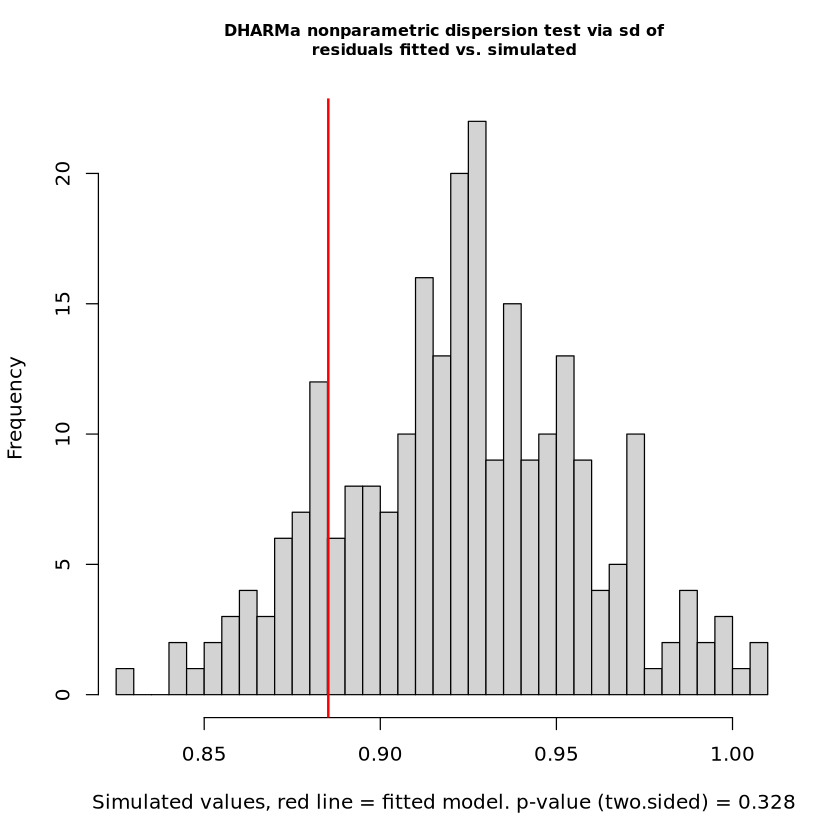


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 0.98107, p-value = 0.648
alternative hypothesis: two.sided


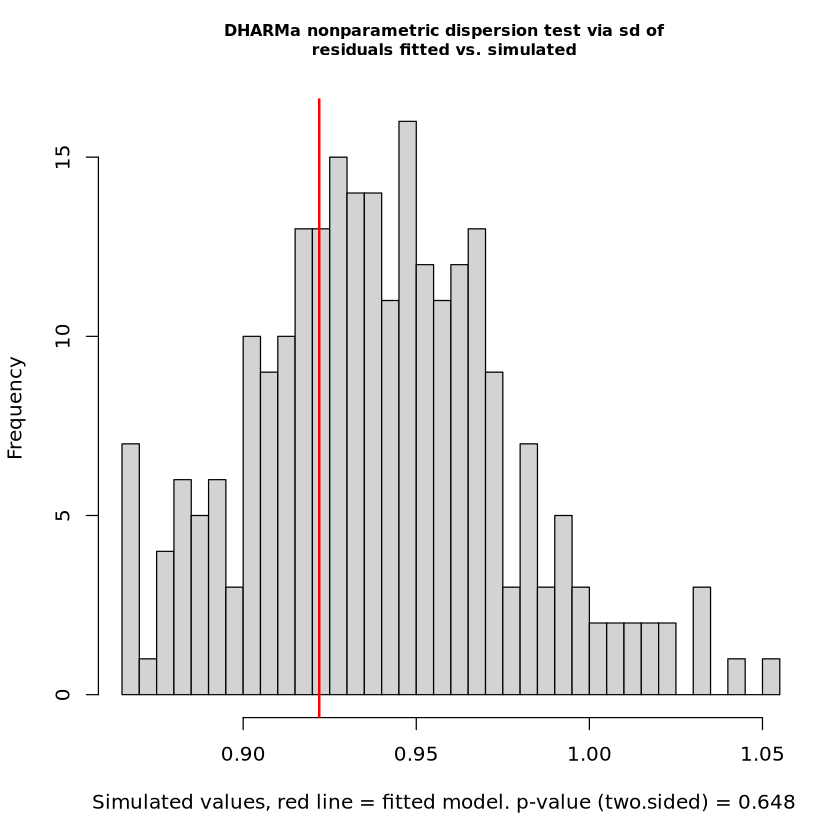

In [13]:
testDispersion(mod1)
testDispersion(mod_null)


	DHARMa bootstrapped outlier test

data:  simulationOutput
outliers at both margin(s) = 49, observations = 28280, p-value <
2.2e-16
alternative hypothesis: two.sided
 percent confidence interval:
 0.002492044 0.004280410
sample estimates:
outlier frequency (expected: 0.00332956152758133 ) 
                                       0.001732673 


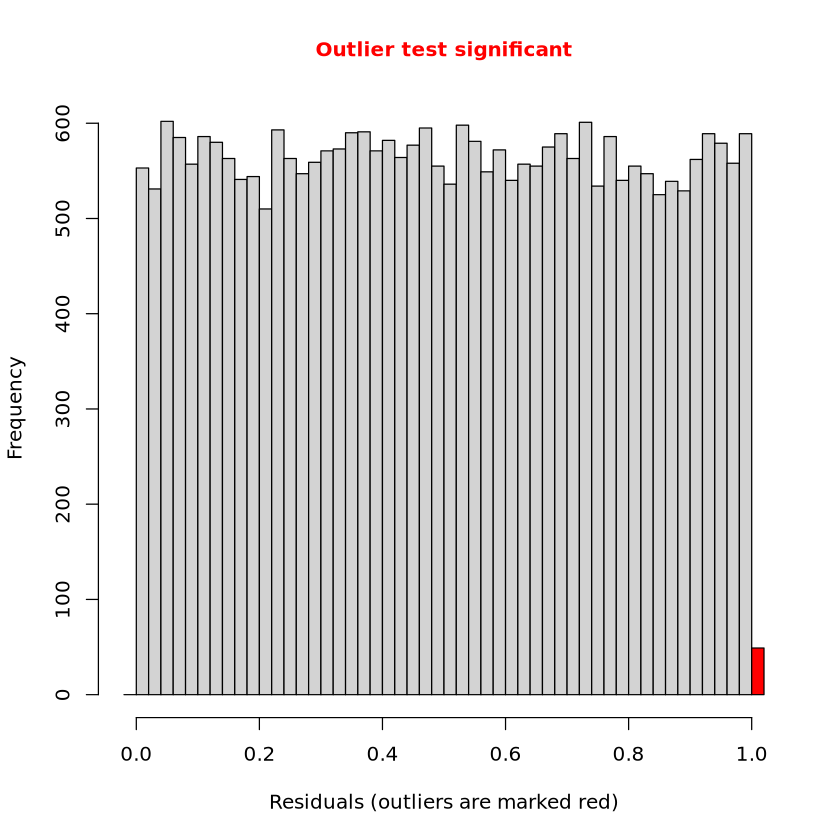

DHARMa:testOutliers with type = binomial may have inflated Type I error rates for integer-valued distributions. To get a more exact result, it is recommended to re-run testOutliers with type = 'bootstrap'. See ?testOutliers for details



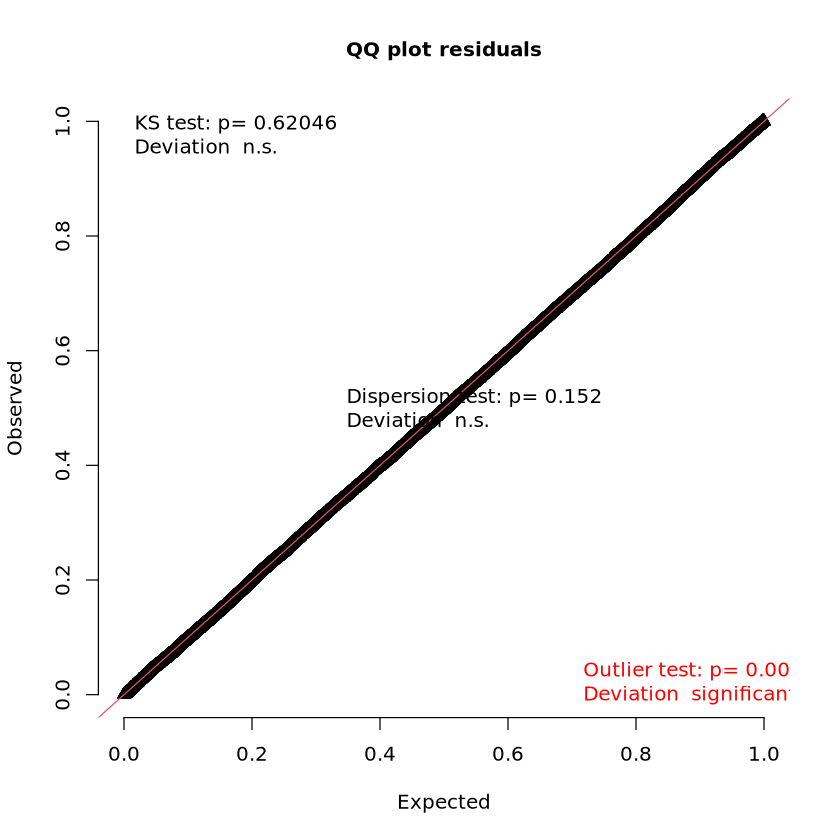

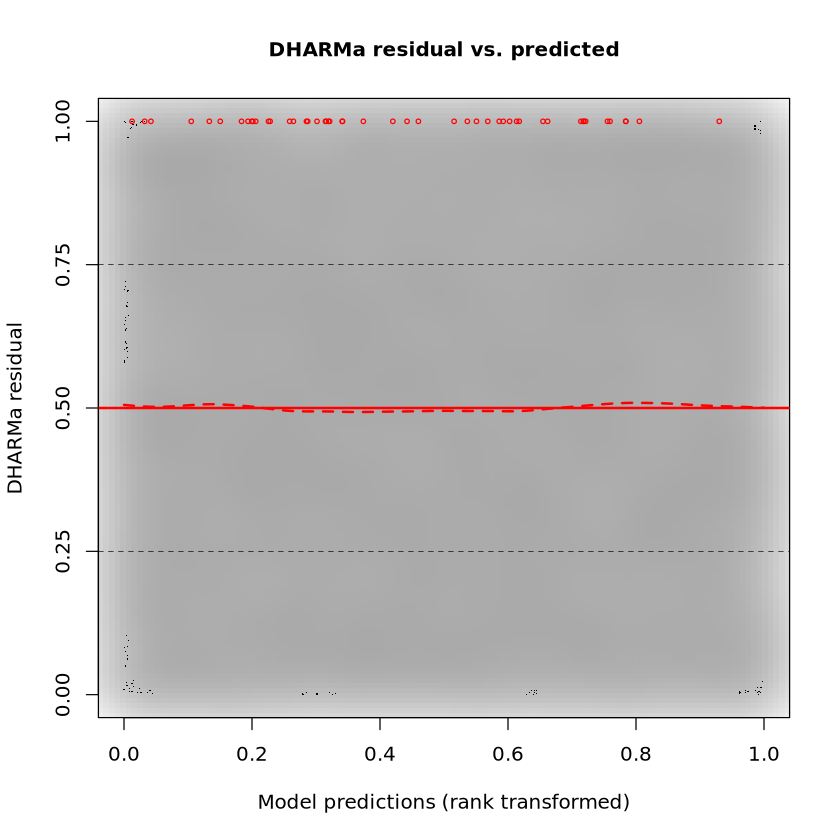


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 1.0038, p-value = 0.472
alternative hypothesis: two.sided


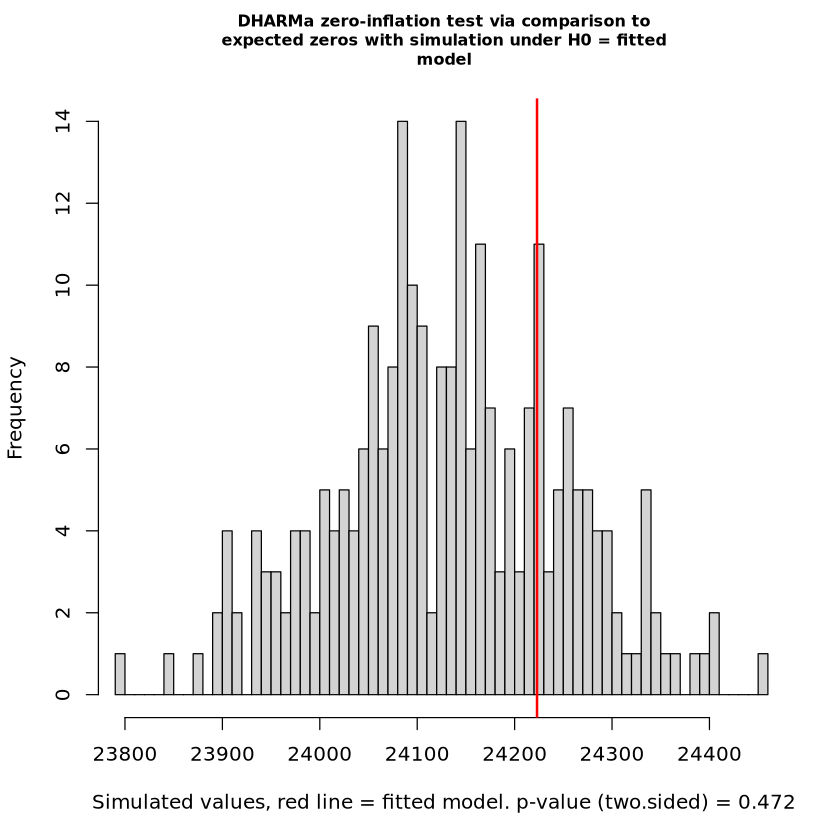


	Test for location of quantiles via qgam

data:  res
p-value = 0.01669
alternative hypothesis: both


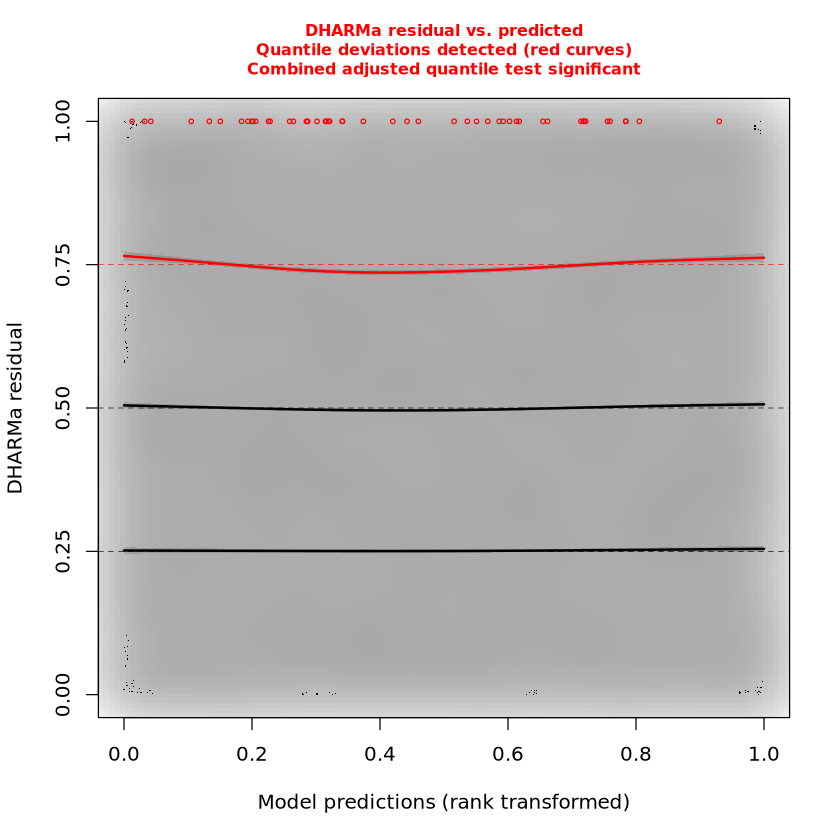


	DHARMa bootstrapped outlier test

data:  simulationOutput
outliers at both margin(s) = 54, observations = 28280, p-value <
2.2e-16
alternative hypothesis: two.sided
 percent confidence interval:
 0.002475248 0.004192893
sample estimates:
outlier frequency (expected: 0.00327298444130127 ) 
                                       0.001909477 


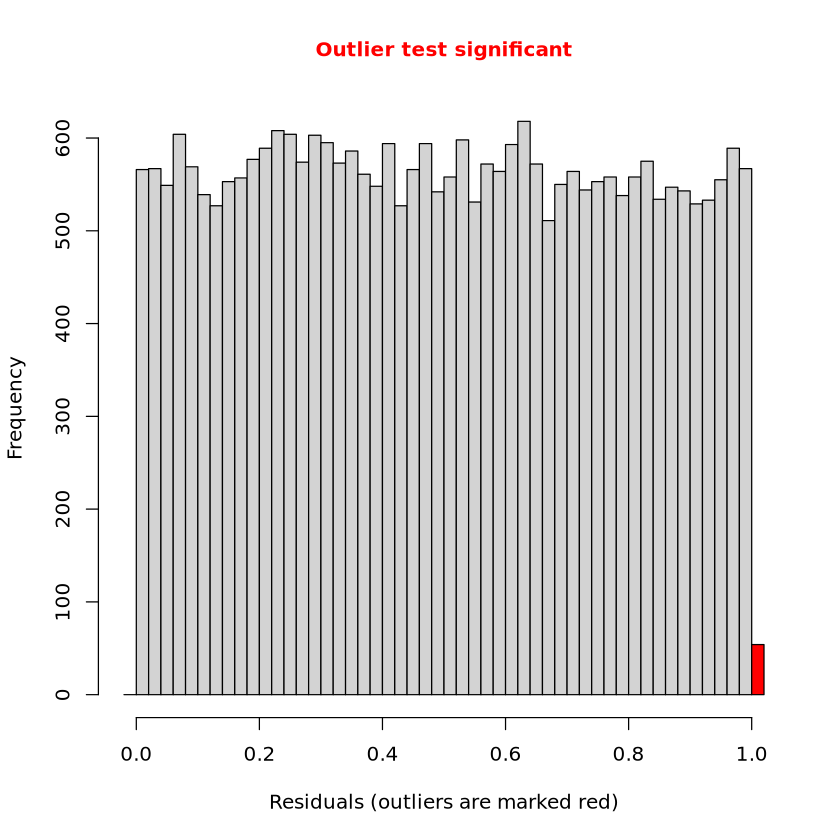

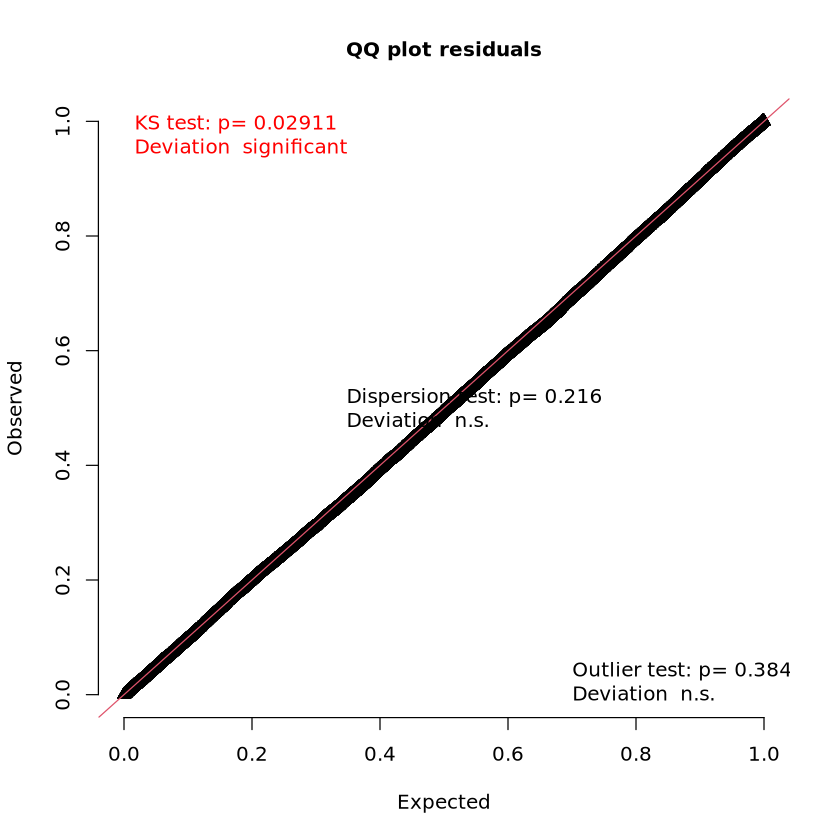

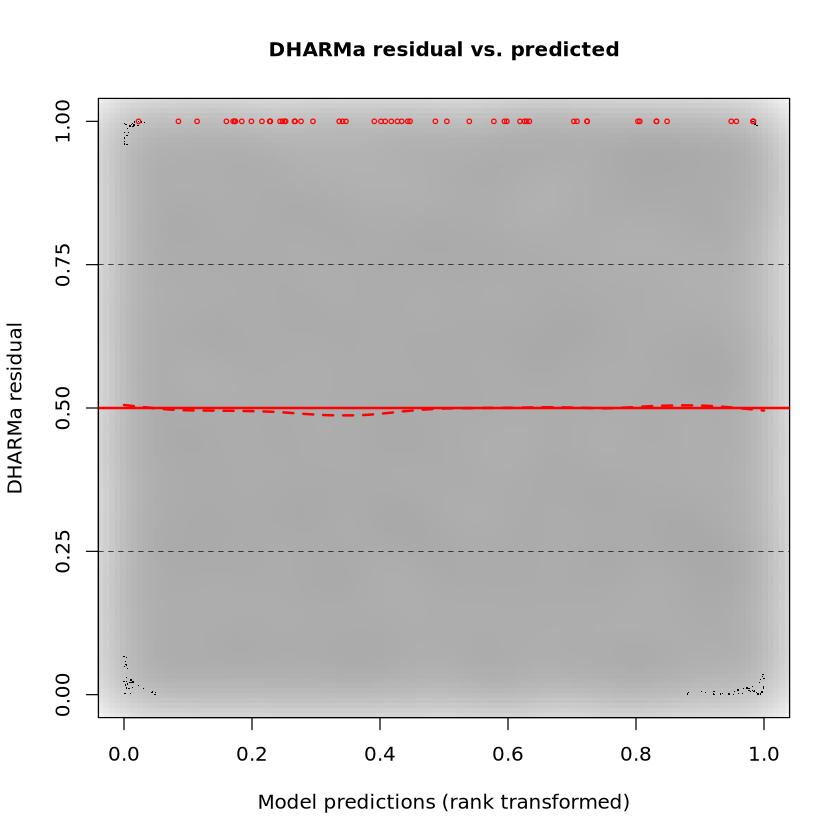


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 1.0036, p-value = 0.52
alternative hypothesis: two.sided


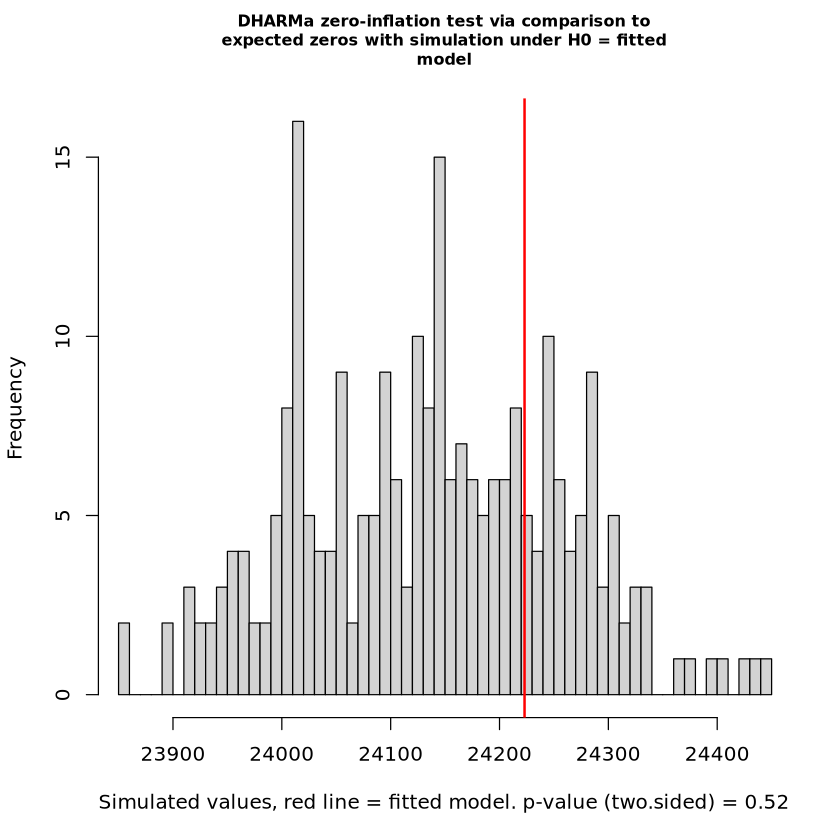


	Test for location of quantiles via qgam

data:  res
p-value = 0.245
alternative hypothesis: both


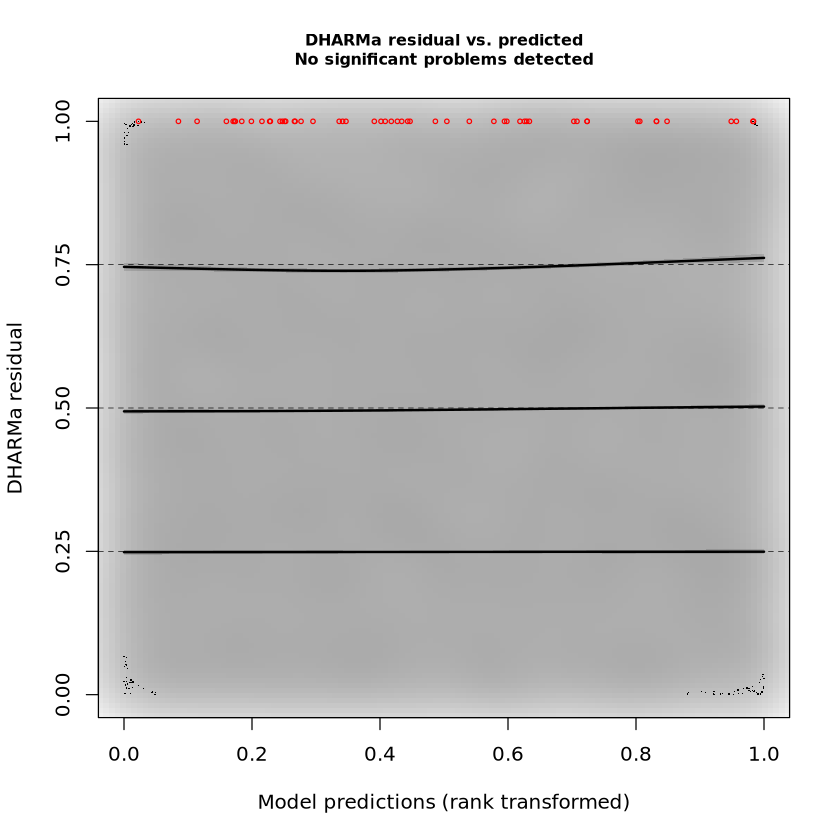

In [21]:
simulationOutput <- simulateResiduals(fittedModel = mod1, plot = F)
testOutliers(simulationOutput, type = "bootstrap")
plotQQunif(simulationOutput)
plotResiduals(simulationOutput)
testZeroInflation(simulationOutput)
testQuantiles(simulationOutput)
simulationOutput <- simulateResiduals(fittedModel = mod_null, plot = F)
testOutliers(simulationOutput, type = "bootstrap")
plotQQunif(simulationOutput)
plotResiduals(simulationOutput)
testZeroInflation(simulationOutput)
testQuantiles(simulationOutput)

[1] "chr15:96258731:96259032"   "chr11:101566622:101566923"
[3] "chr19:42378279:42378580"   "chr3:180352317:180352618" 
[5] "chr2:100617021:100617322"  "chr12:82650656:82650957"

[1] "Full"
[1] "Full"


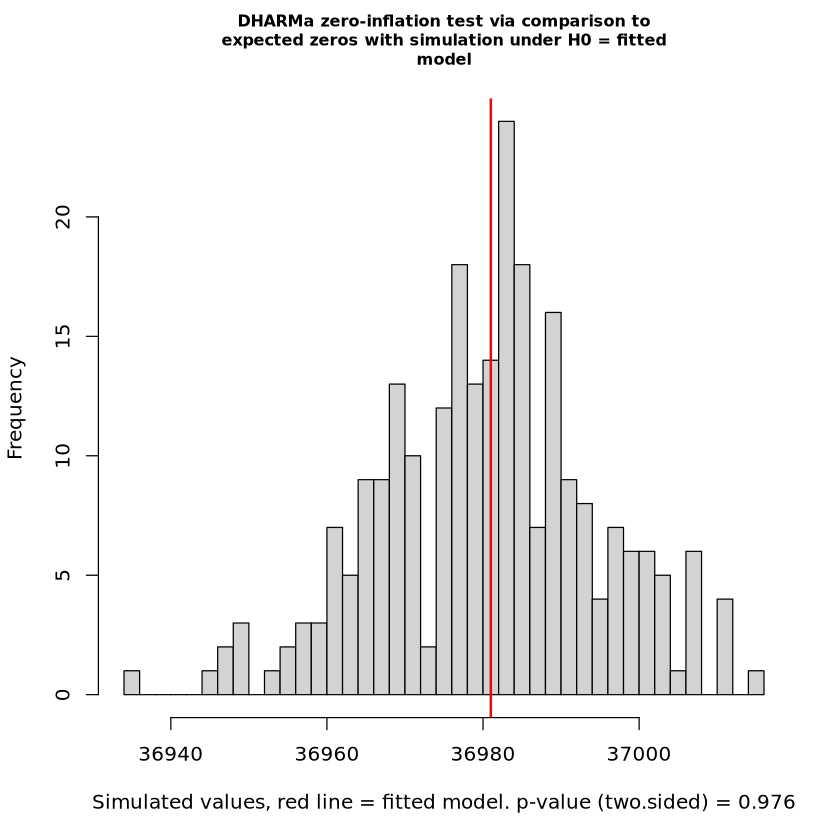

[1] "Full"


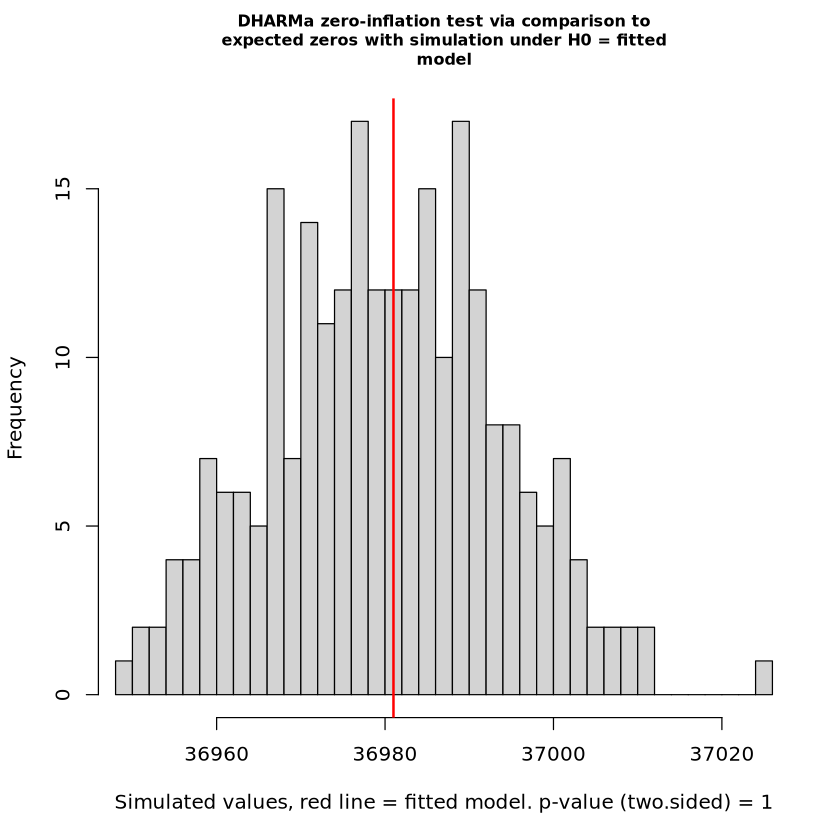

[1] "Full"


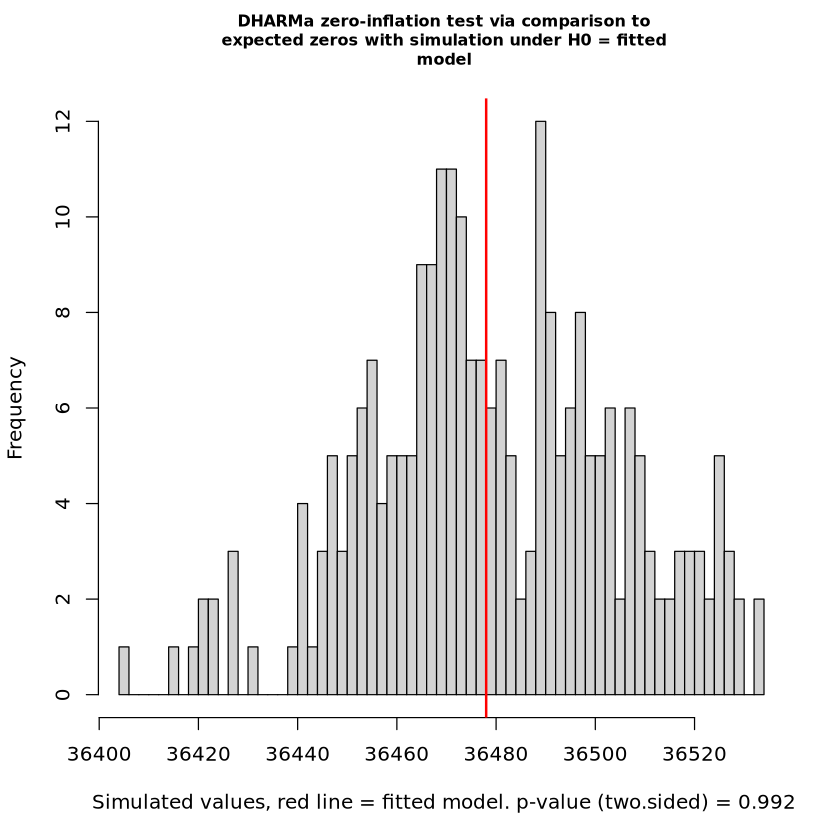

[1] "Full"


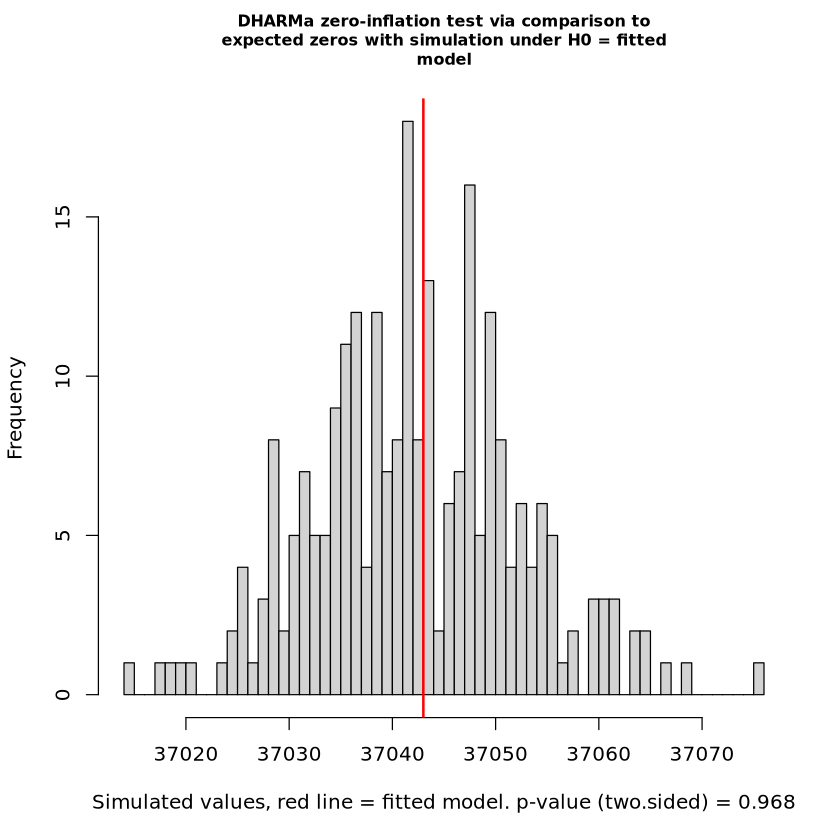

[1] "Full"


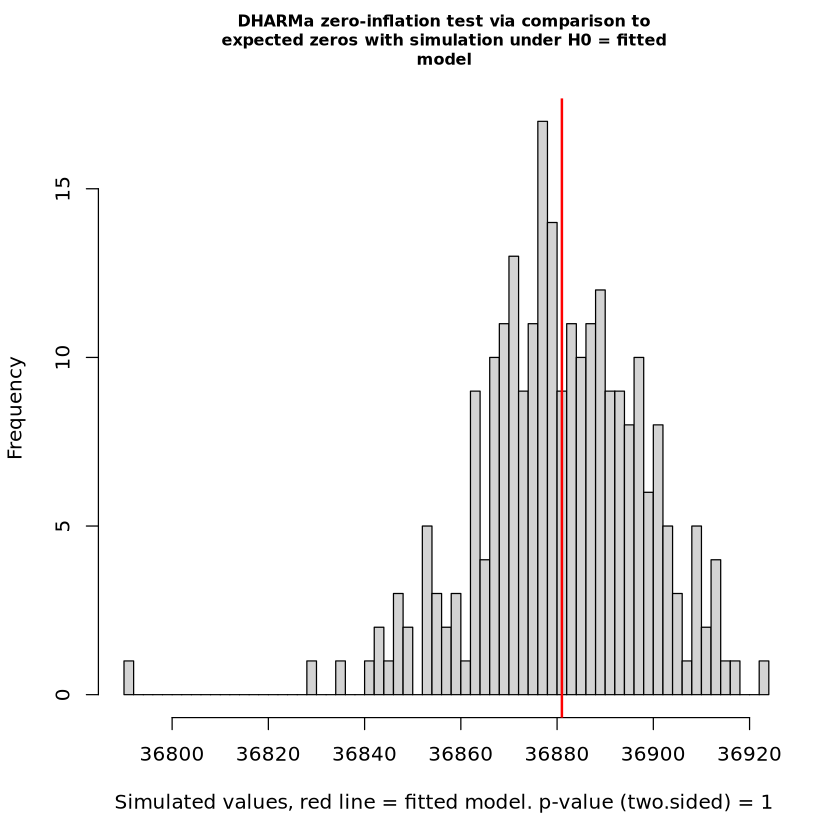

[1] "Full"


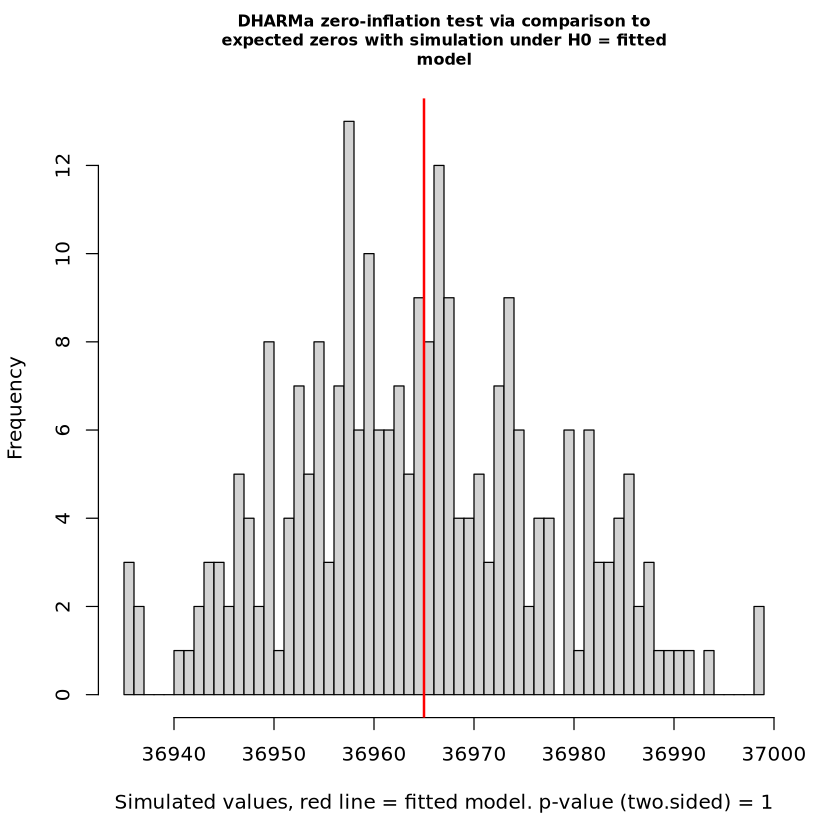

[1] "Full"


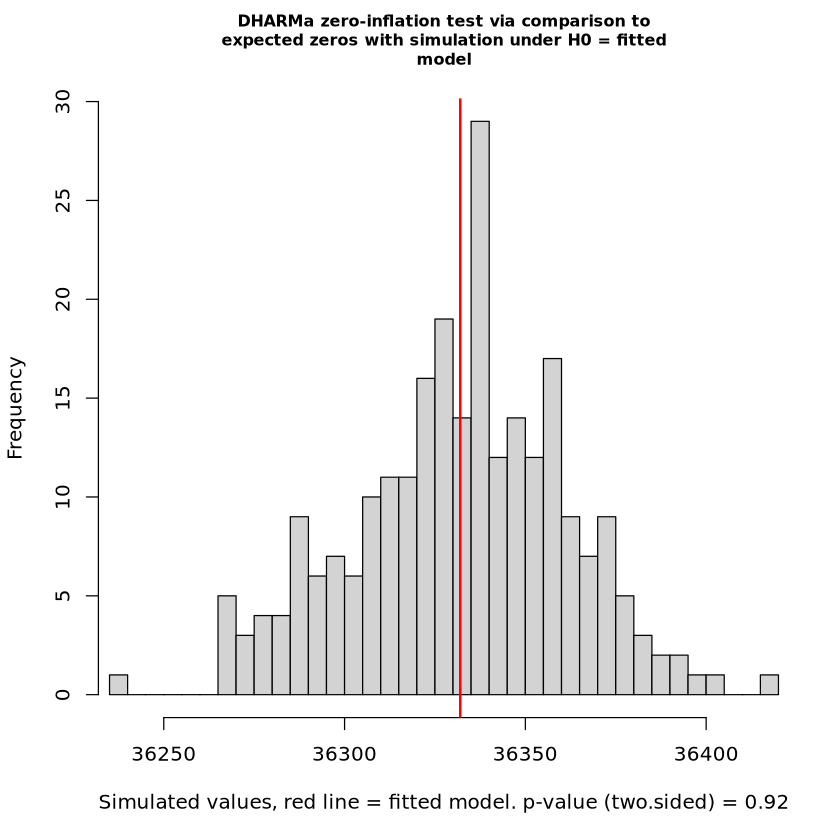

[1] "Full"


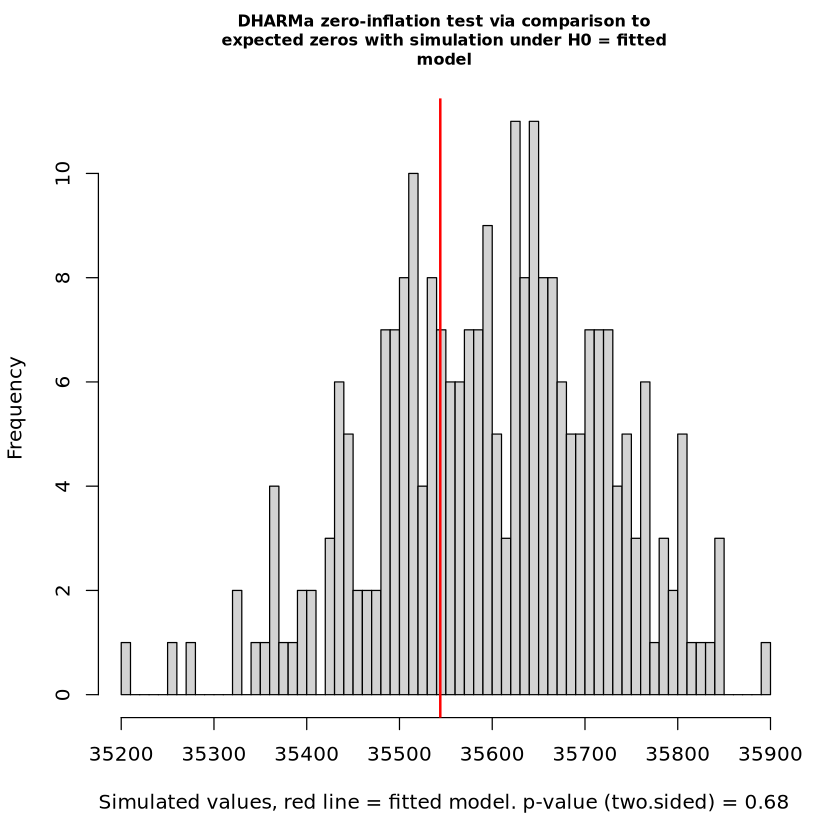

[1] "Full"


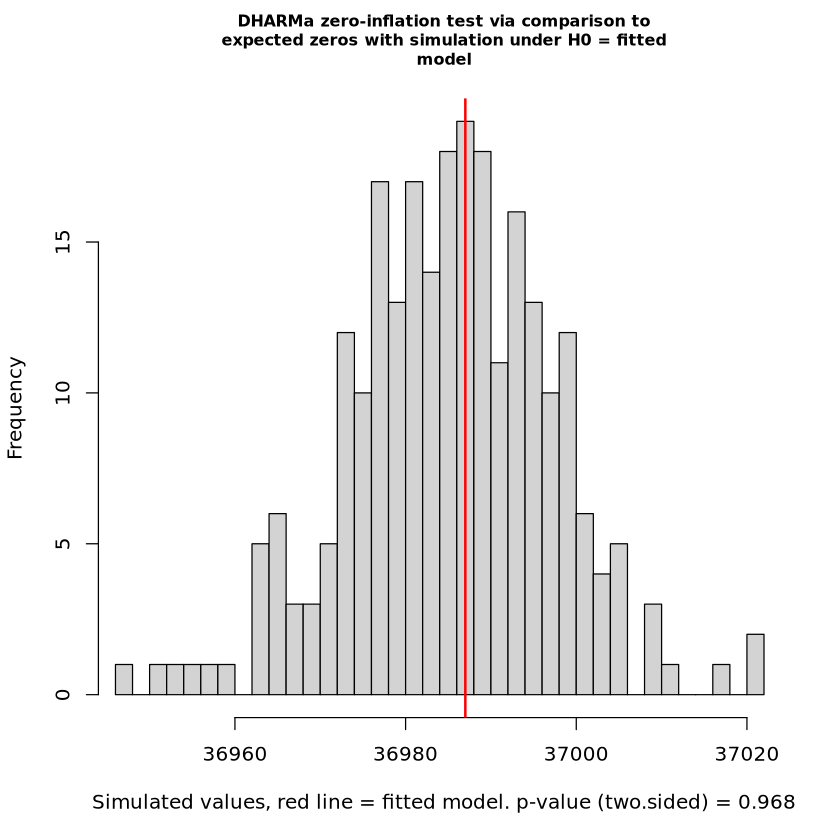

[1] "Full"


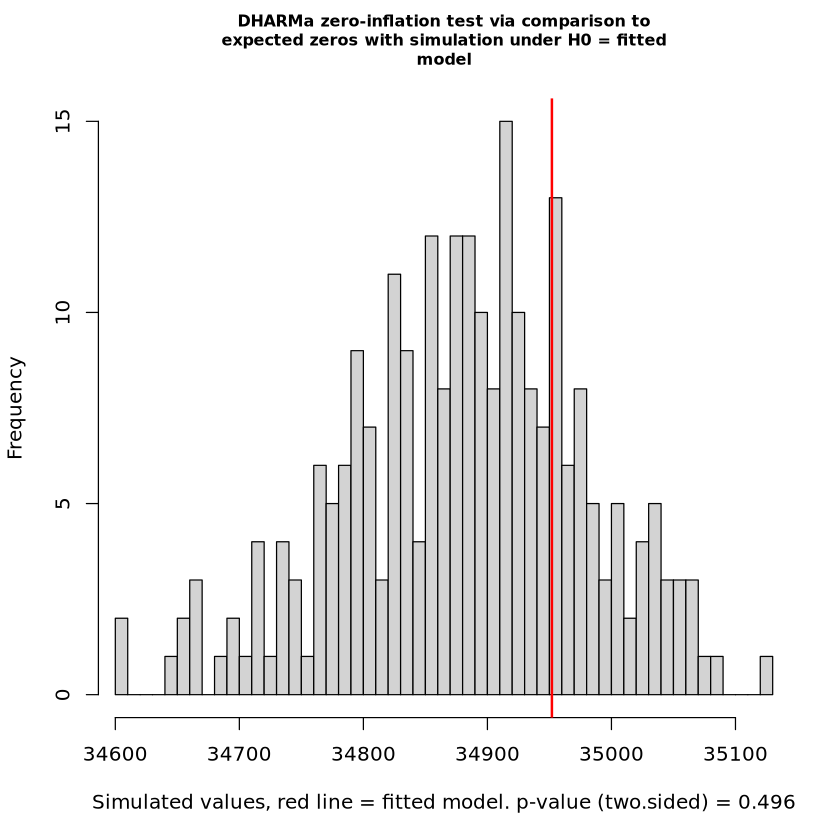

[1] "Full"


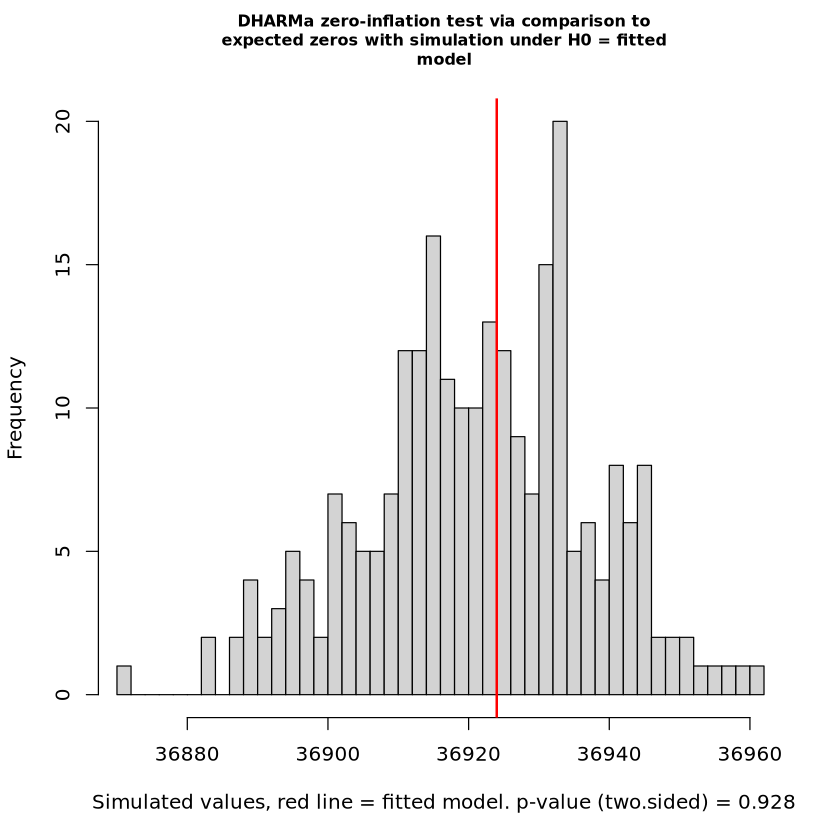

[1] "Full"


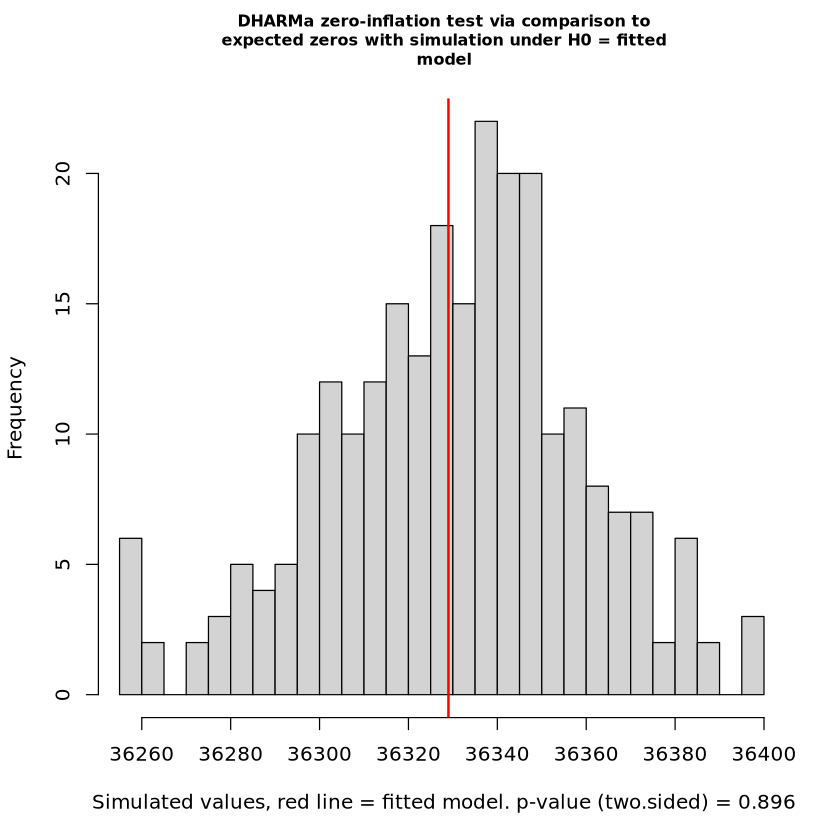

[1] "Full"


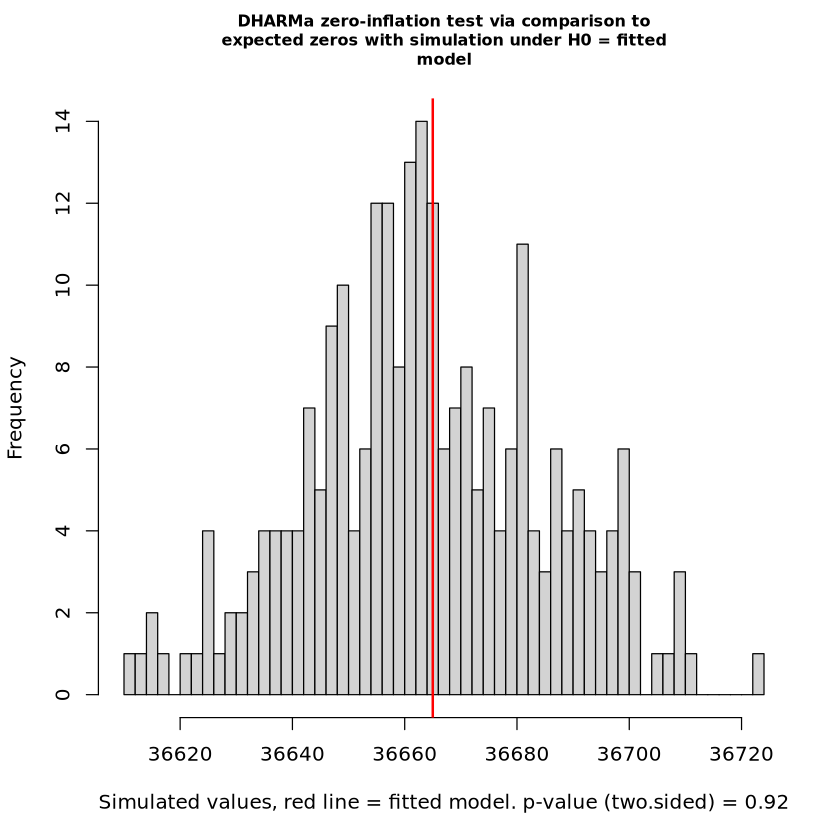

[1] "Full"


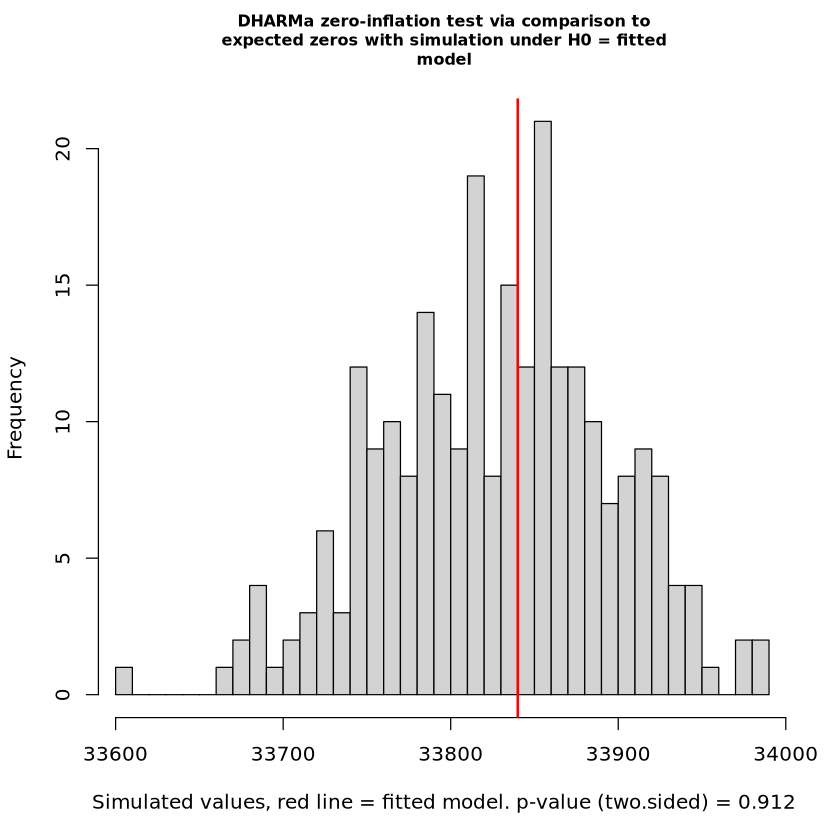

[1] "Full"


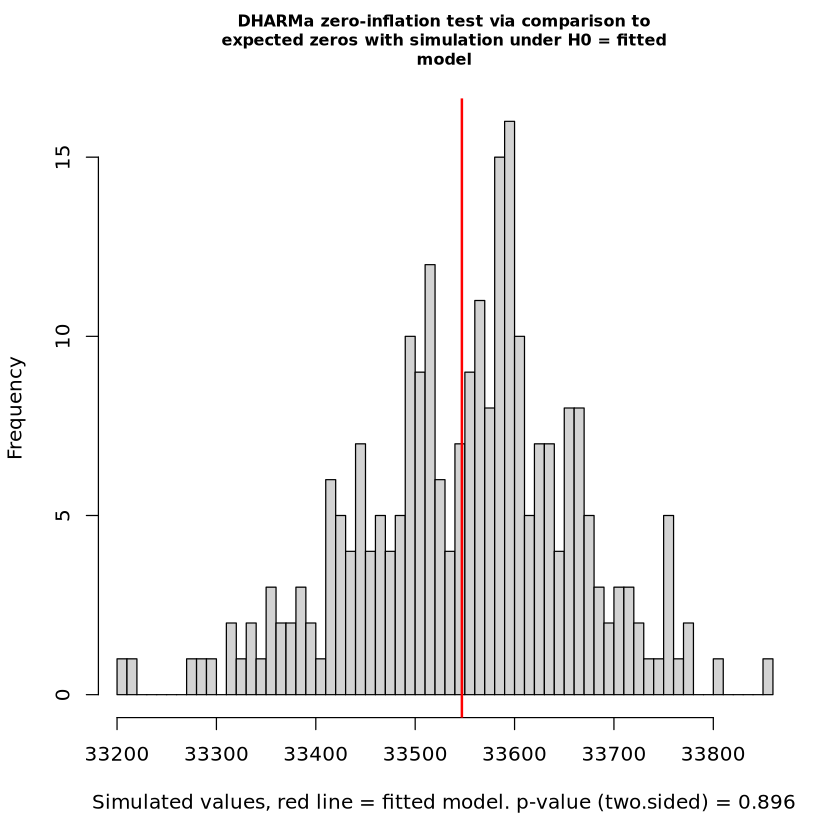

[1] "Full"


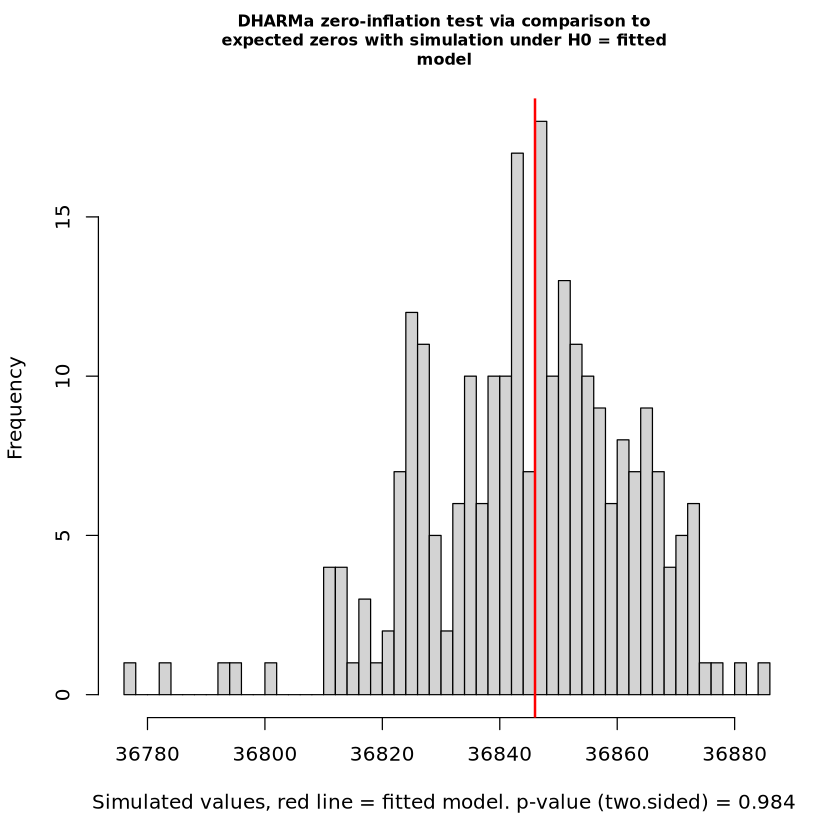

[1] "Full"


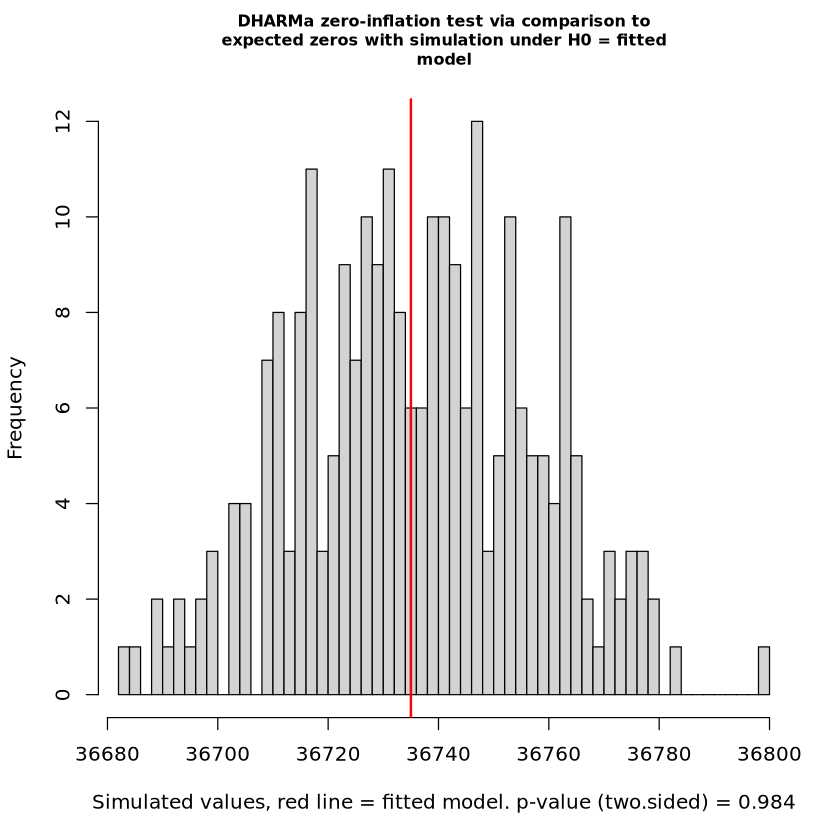

[1] "Full"


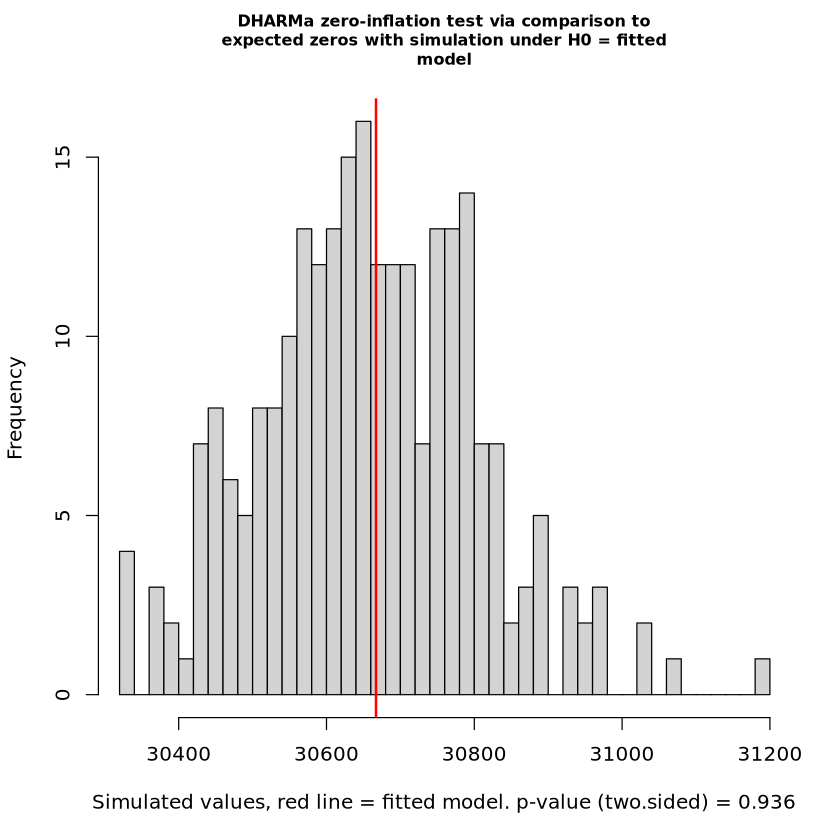

[1] "Full"


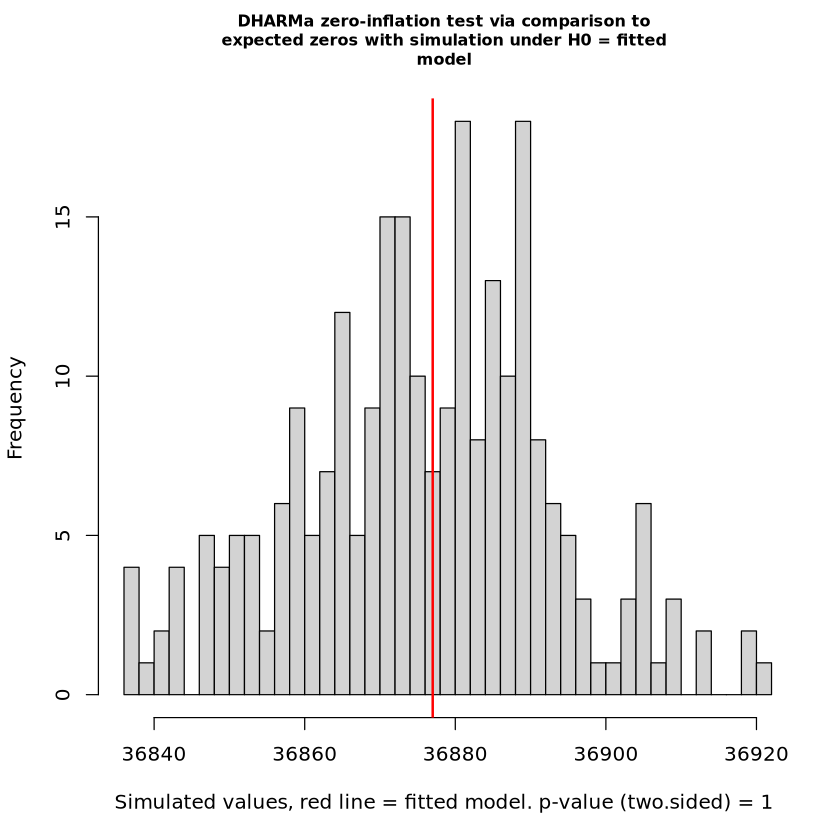

[1] "Full"


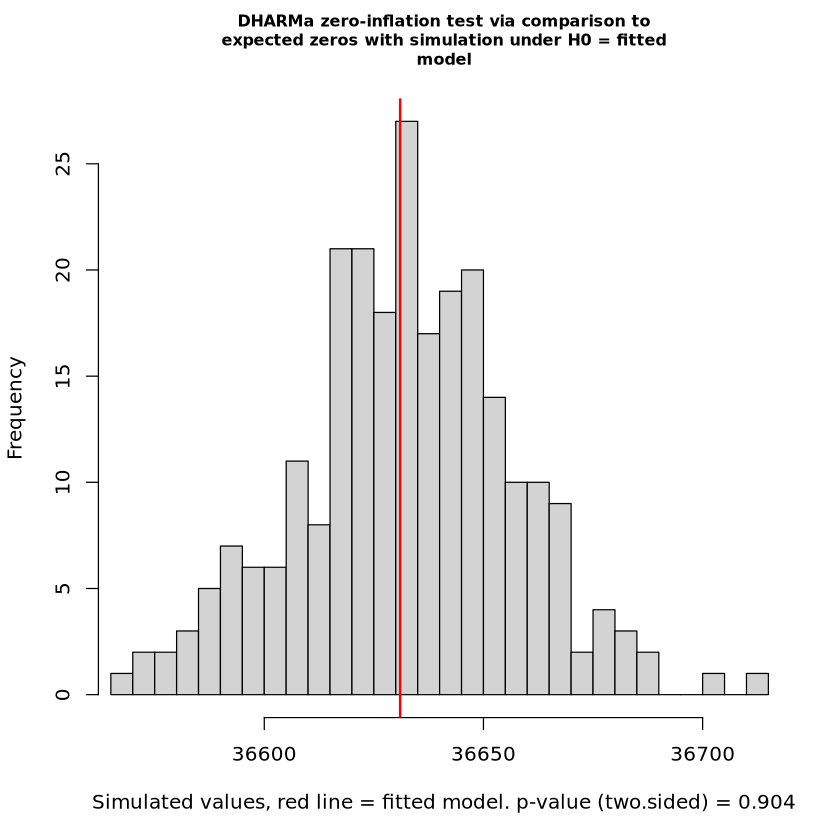

[1] "Full"


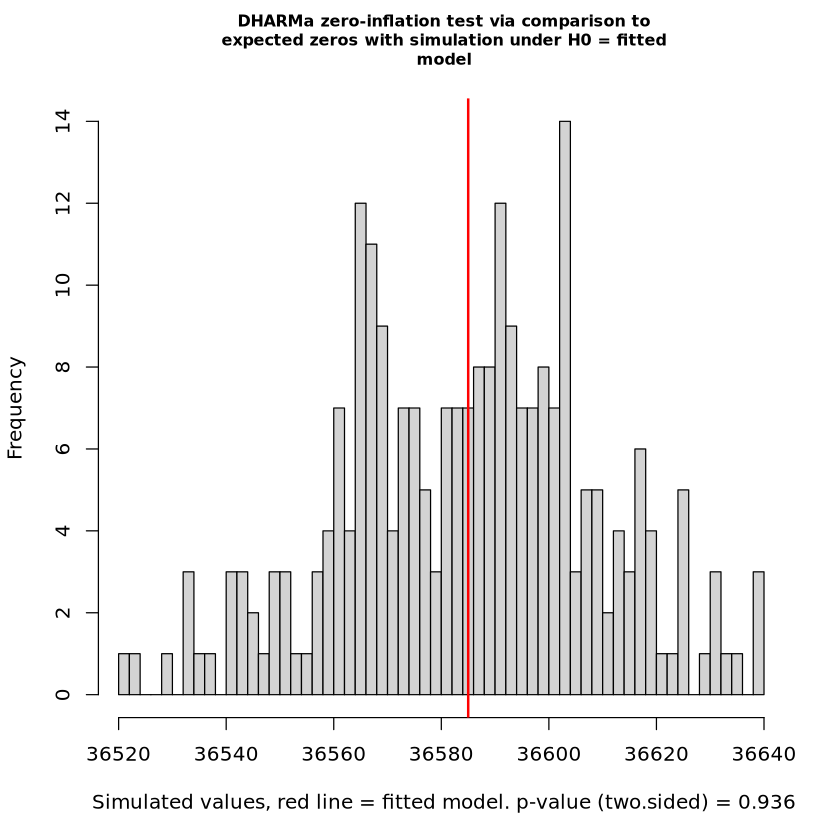

[1] "Full"


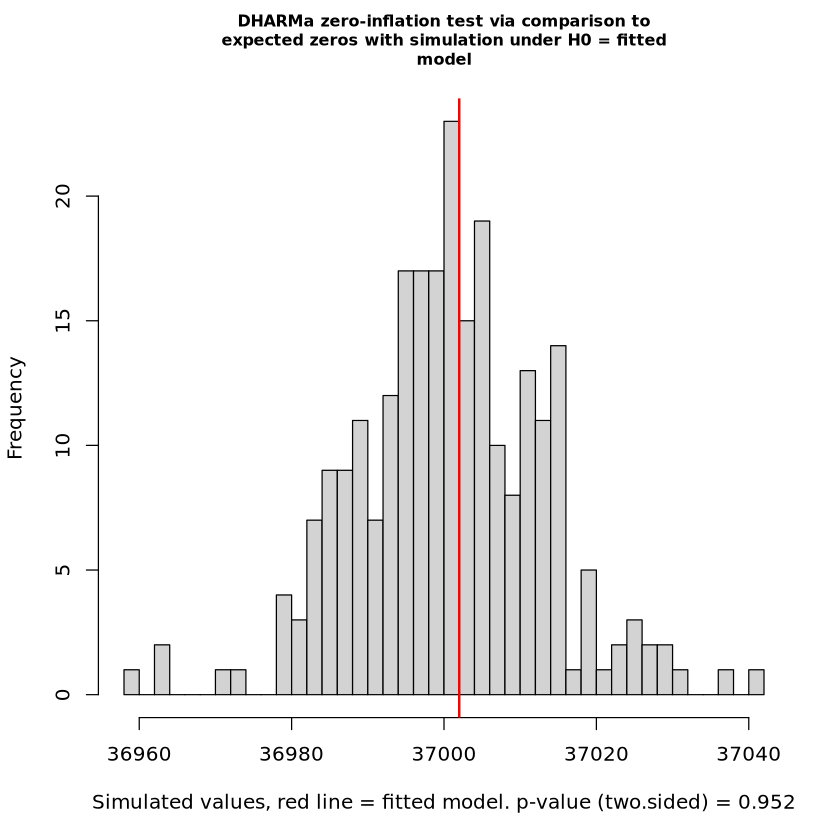

[1] "Full"


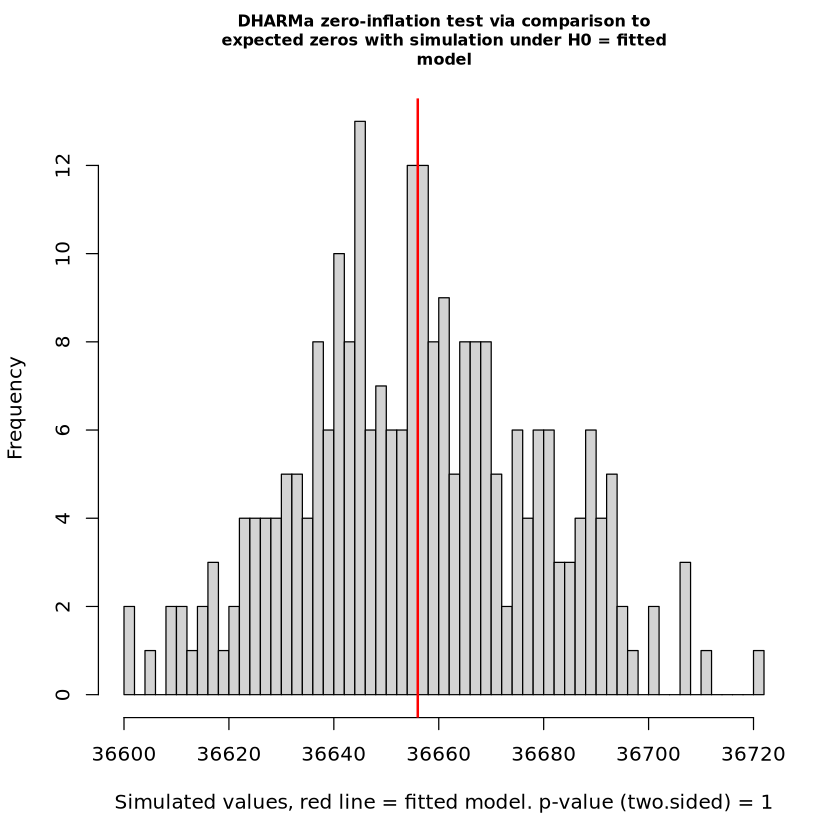

[1] "Full"


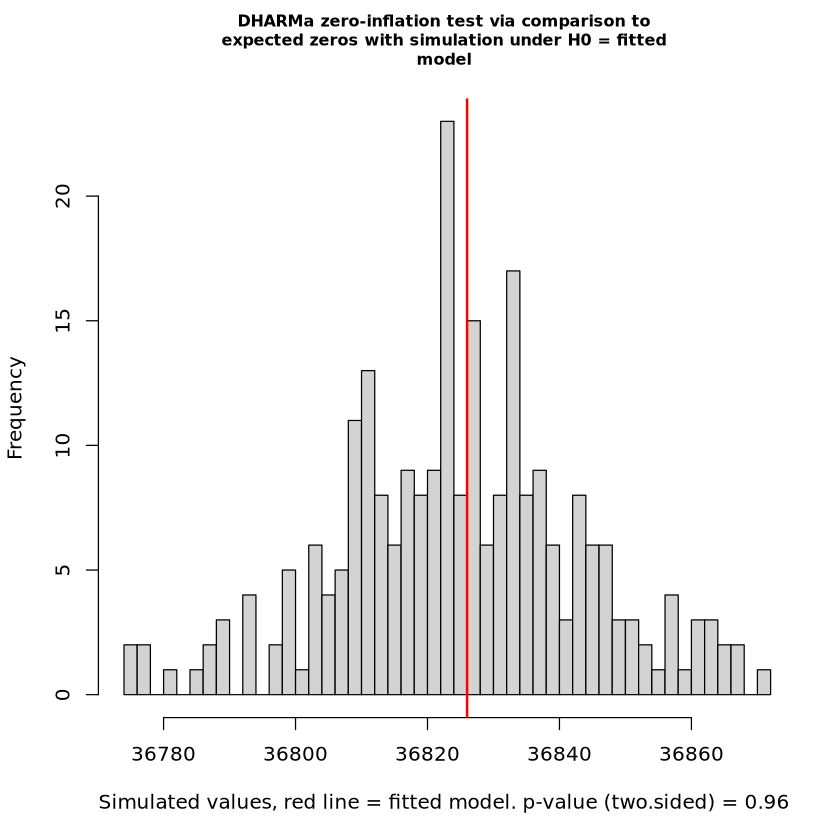

[1] "Full"


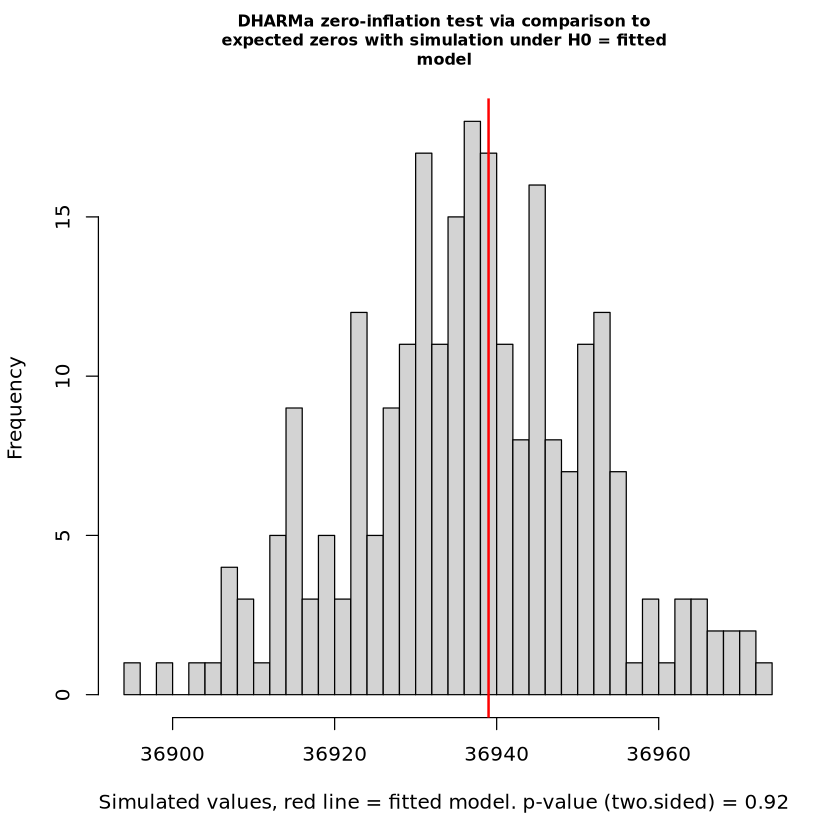

[1] "Full"


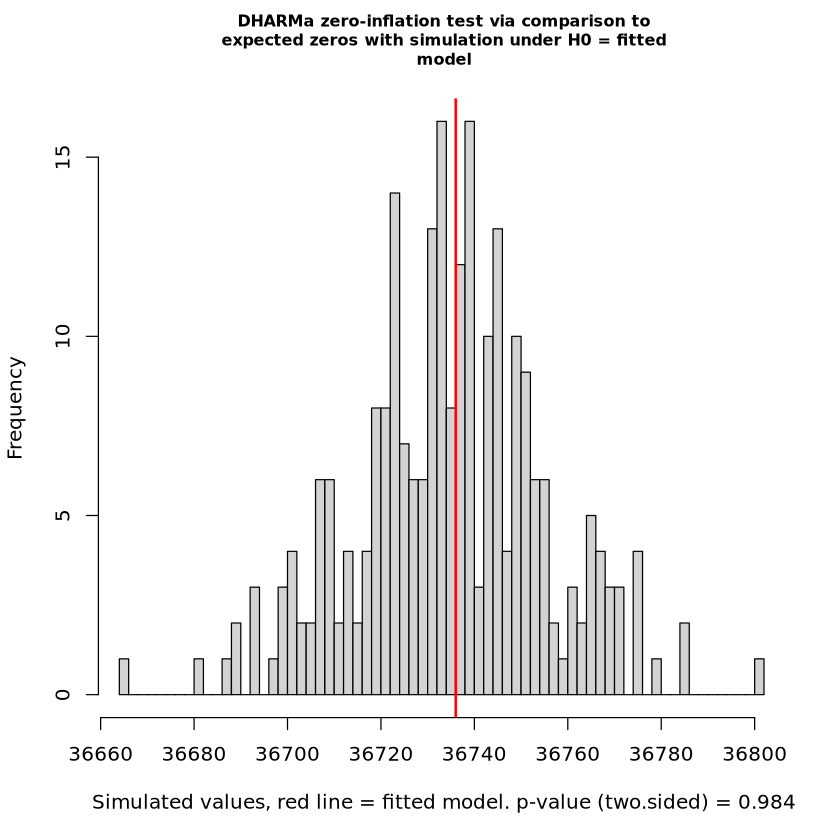

[1] "Full"


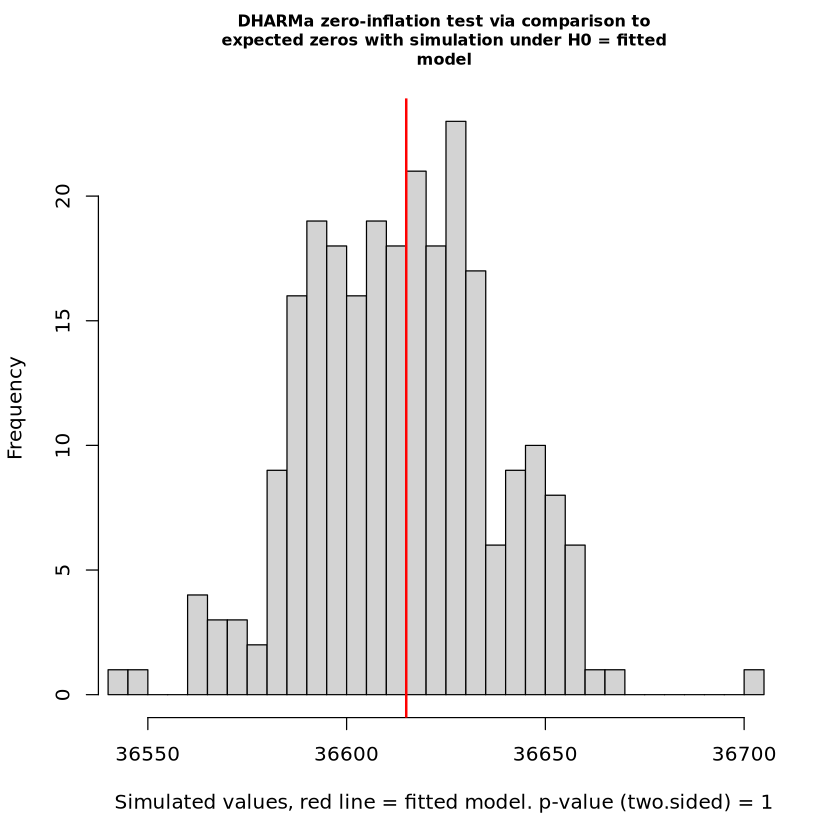

[1] "Full"


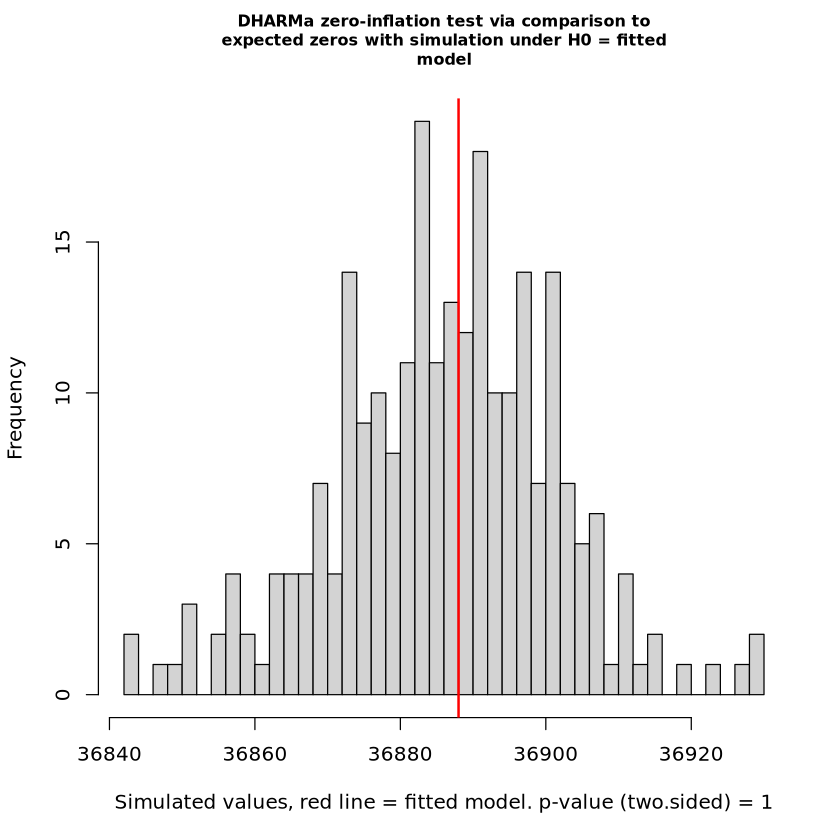

[1] "Full"


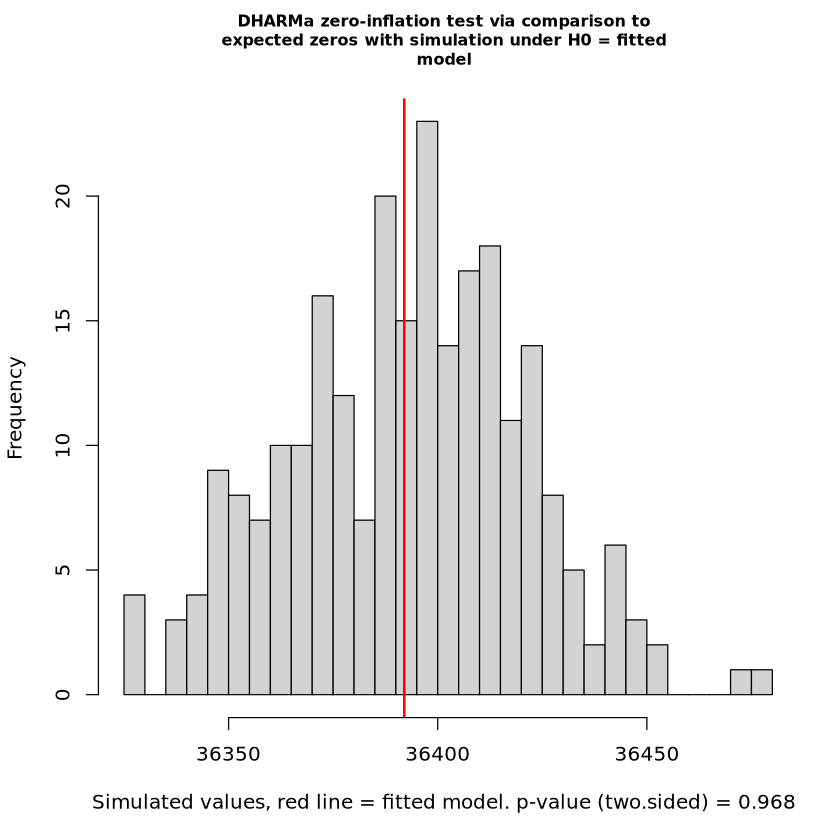

[1] "Full"


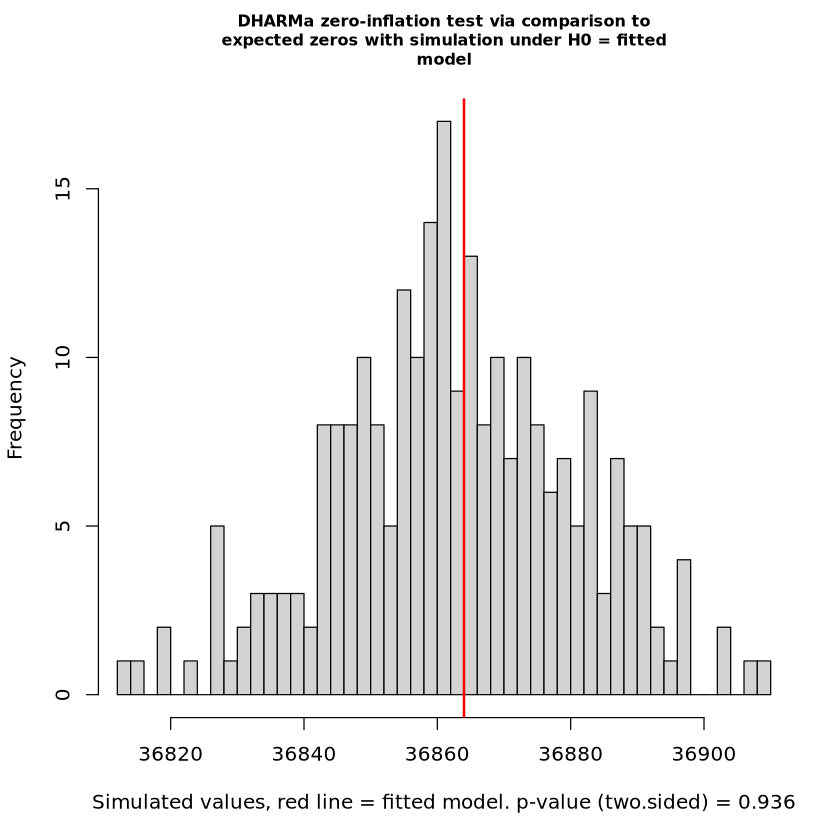

[1] "Full"


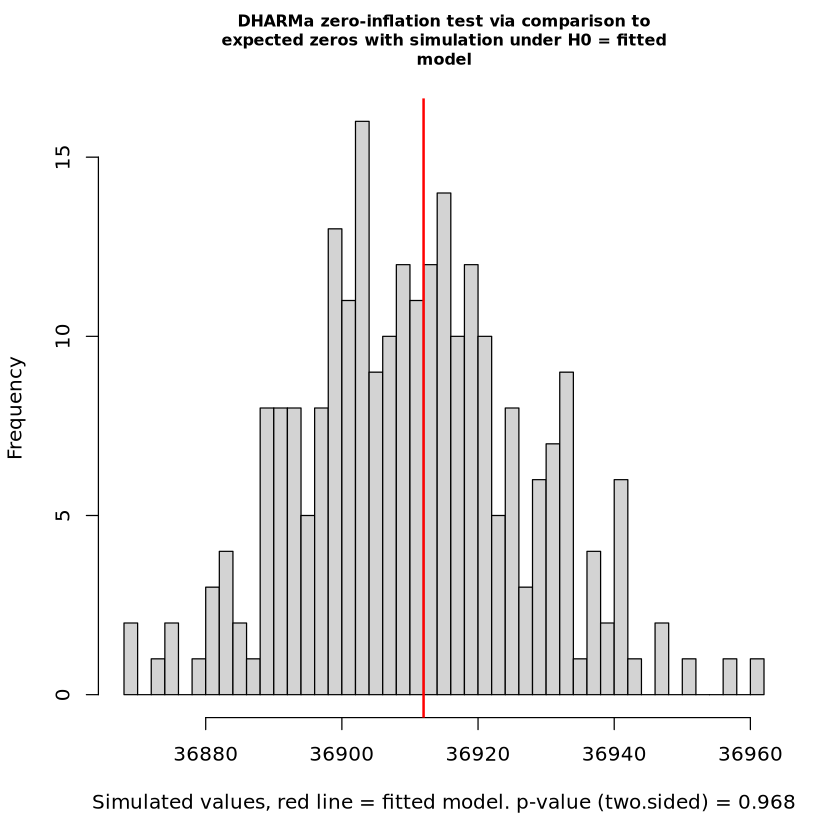

[1] "Full"


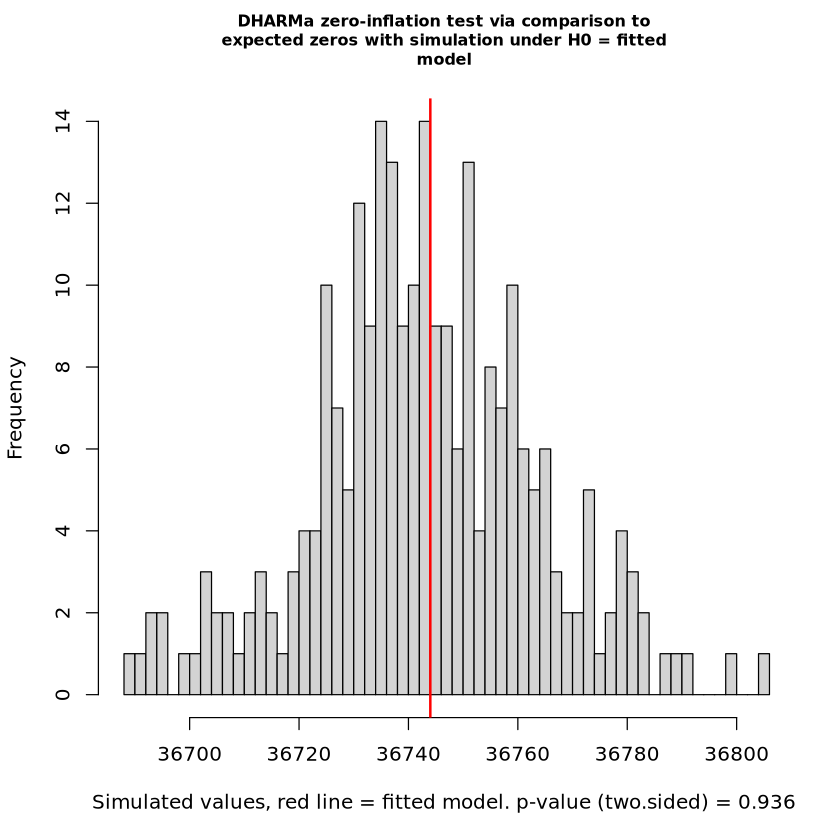

[1] "Full"


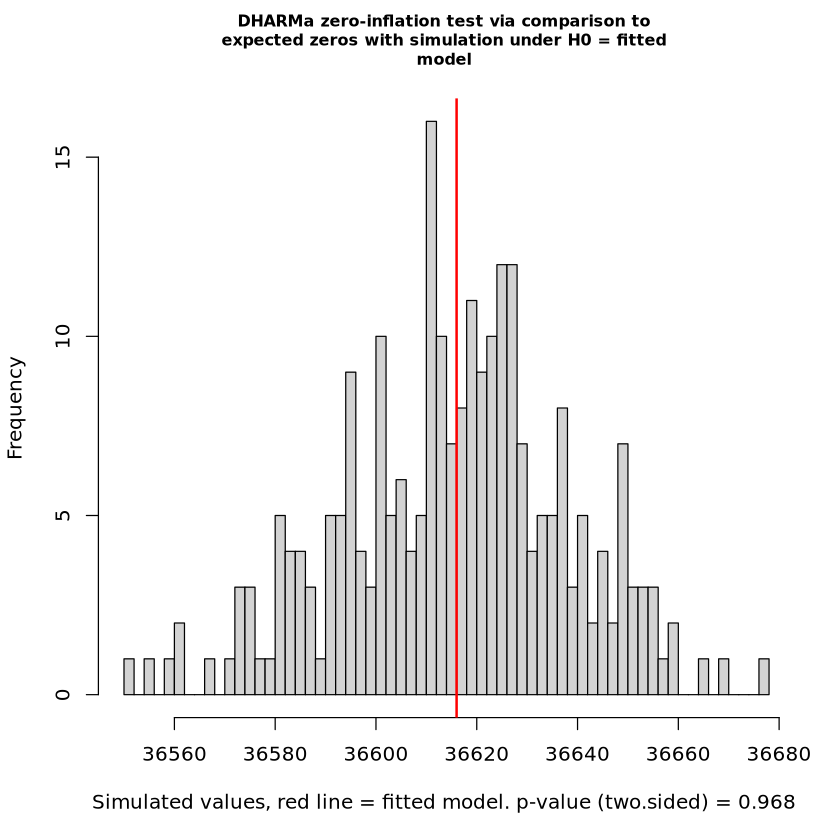

[1] "Full"


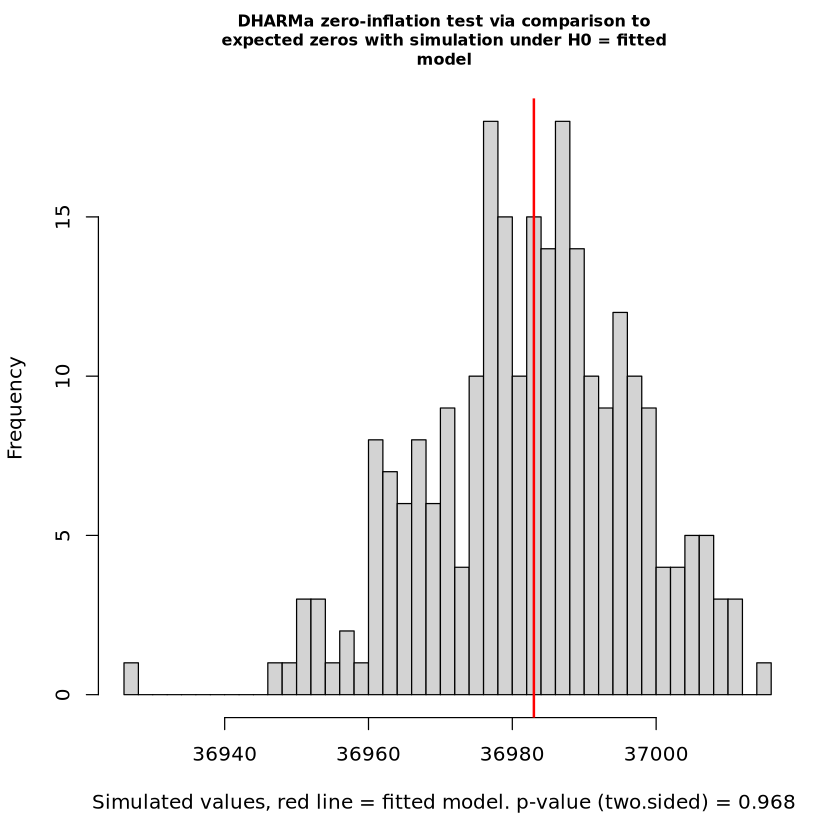

[1] "Full"


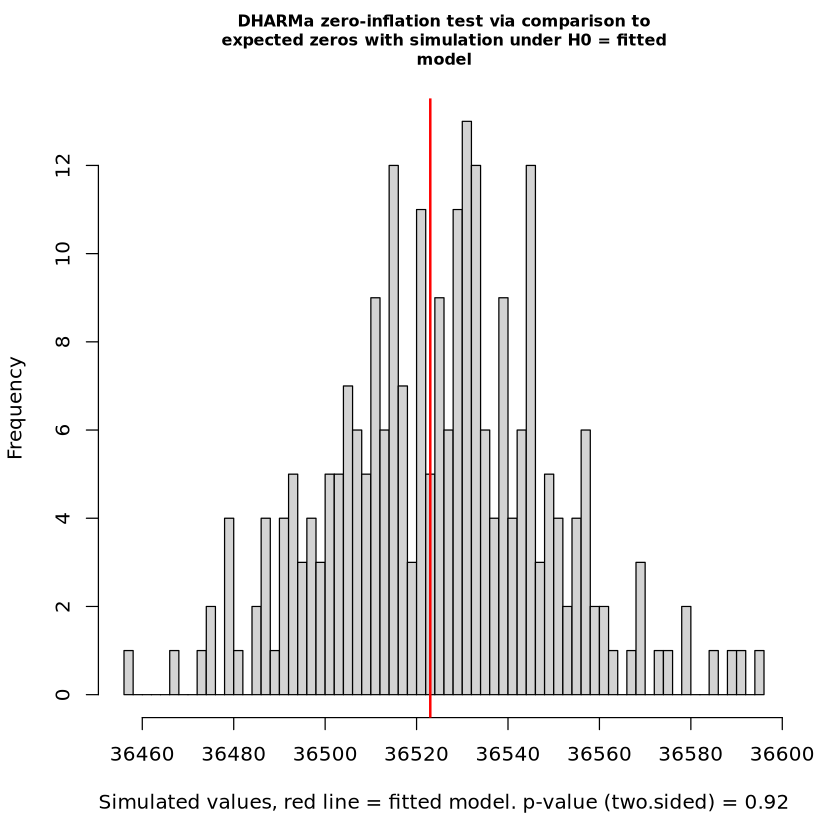

[1] "Full"


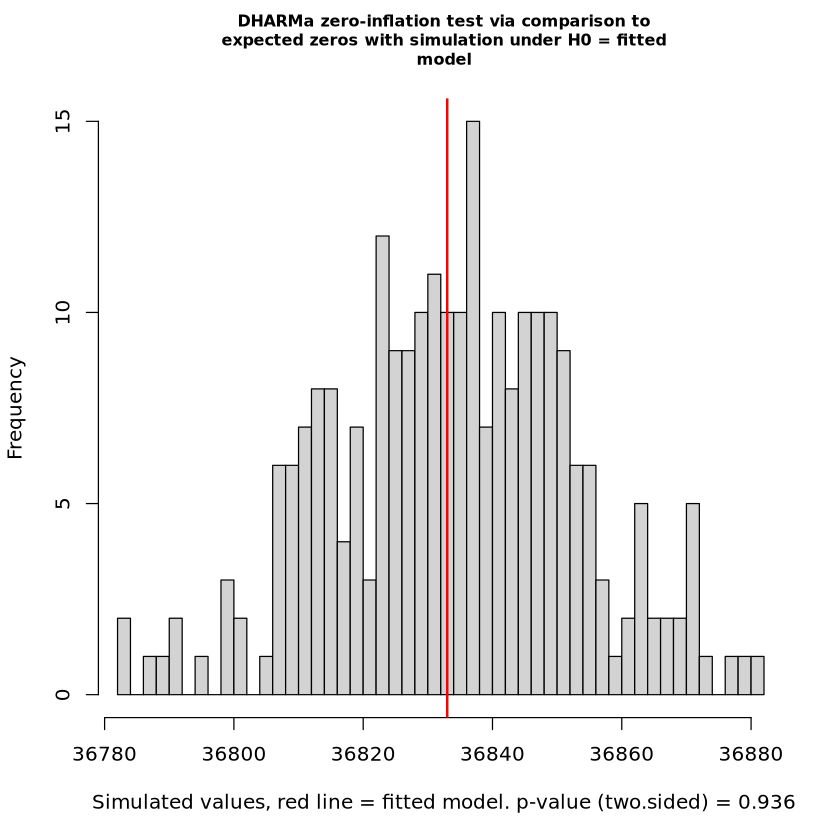

[1] "Full"


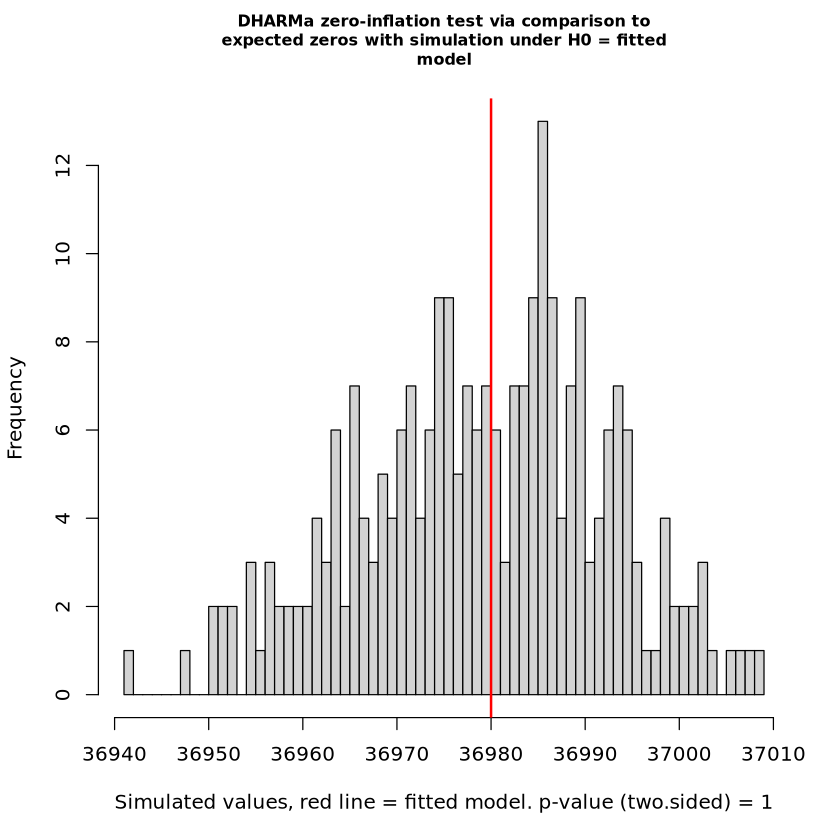

[1] "Full"


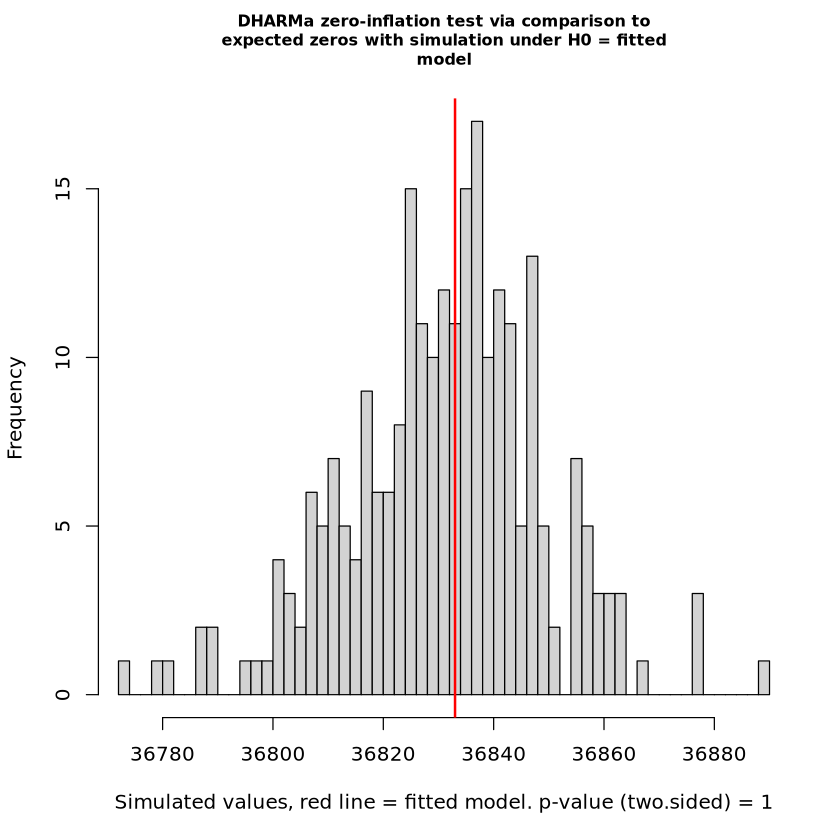

[1] "Full"


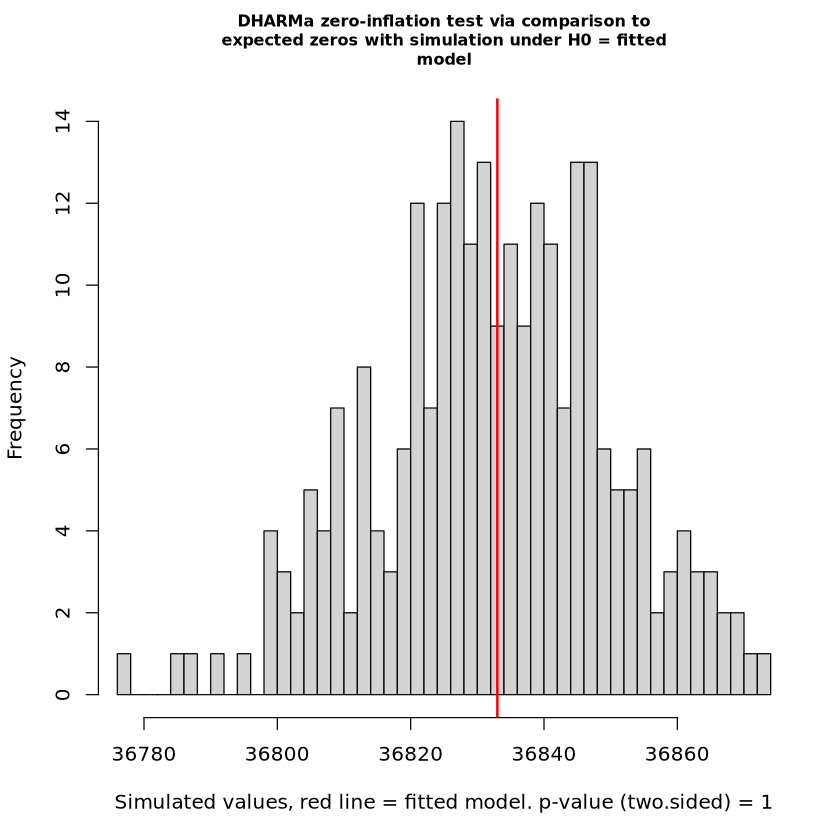

[1] "Full"


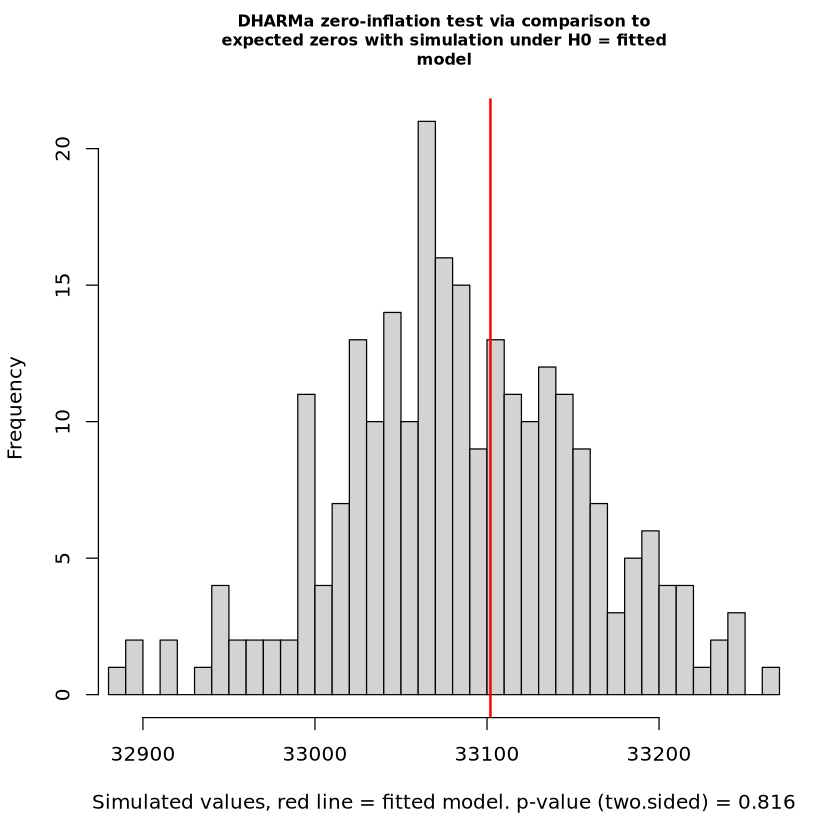

[1] "Full"


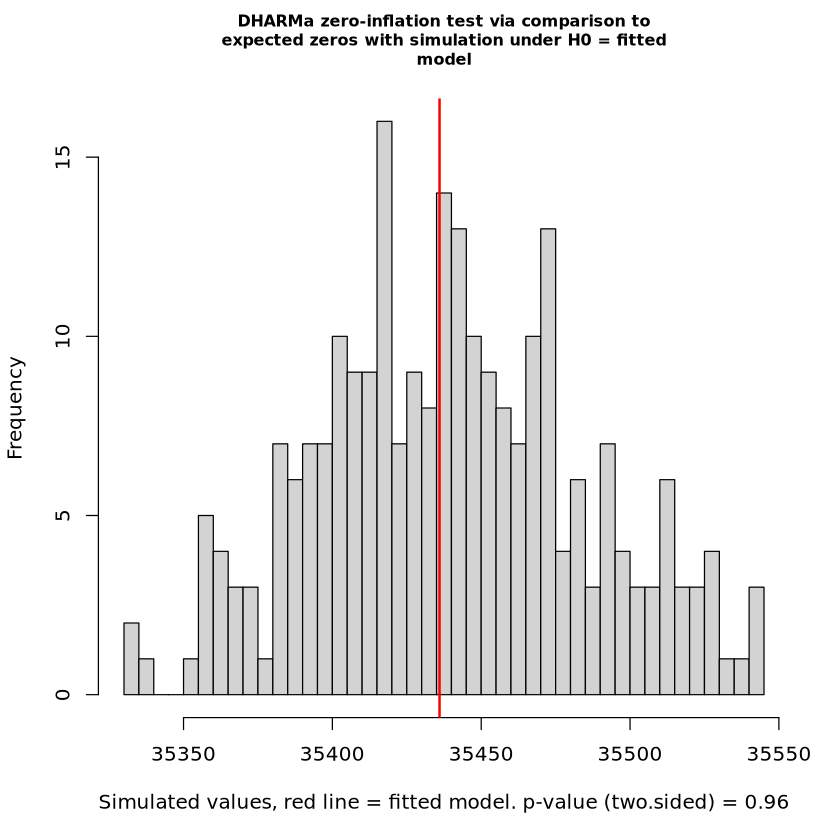

[1] "Full"


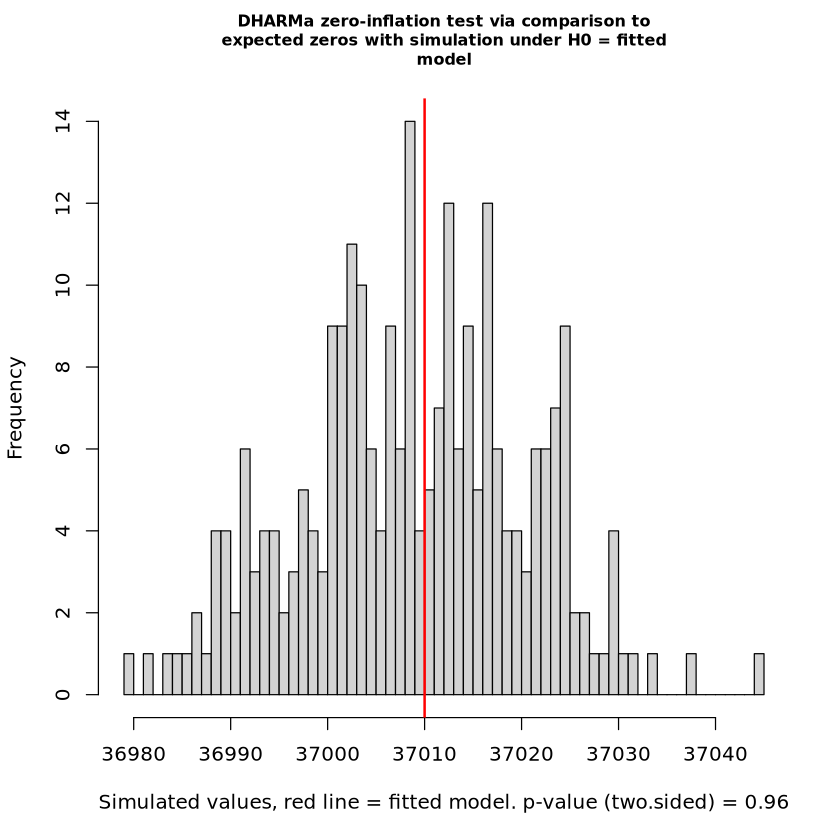

[1] "Full"


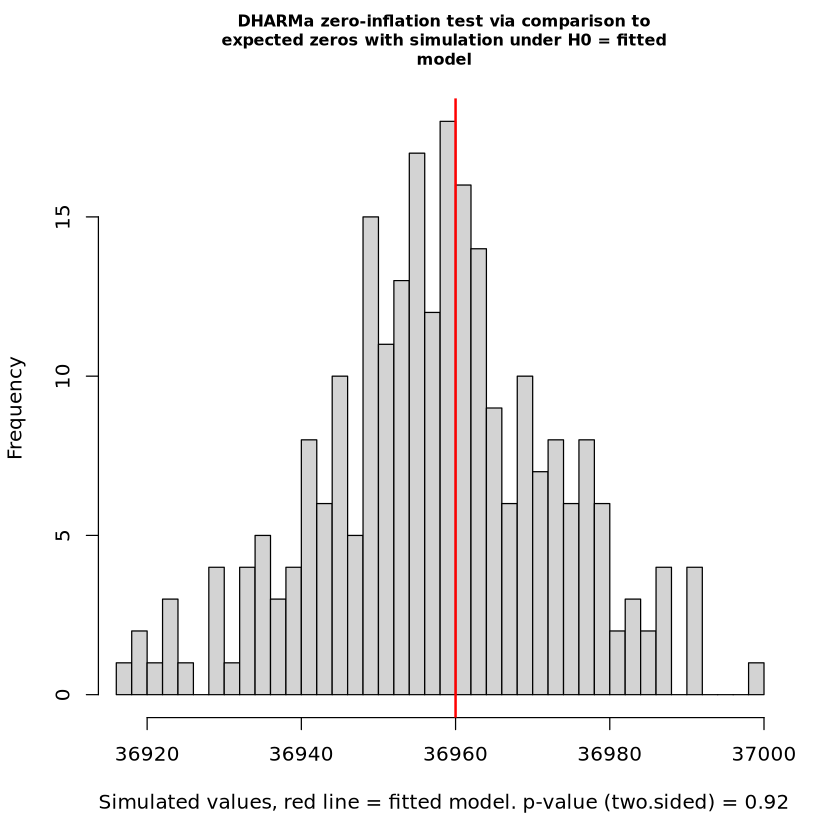

[1] "Full"


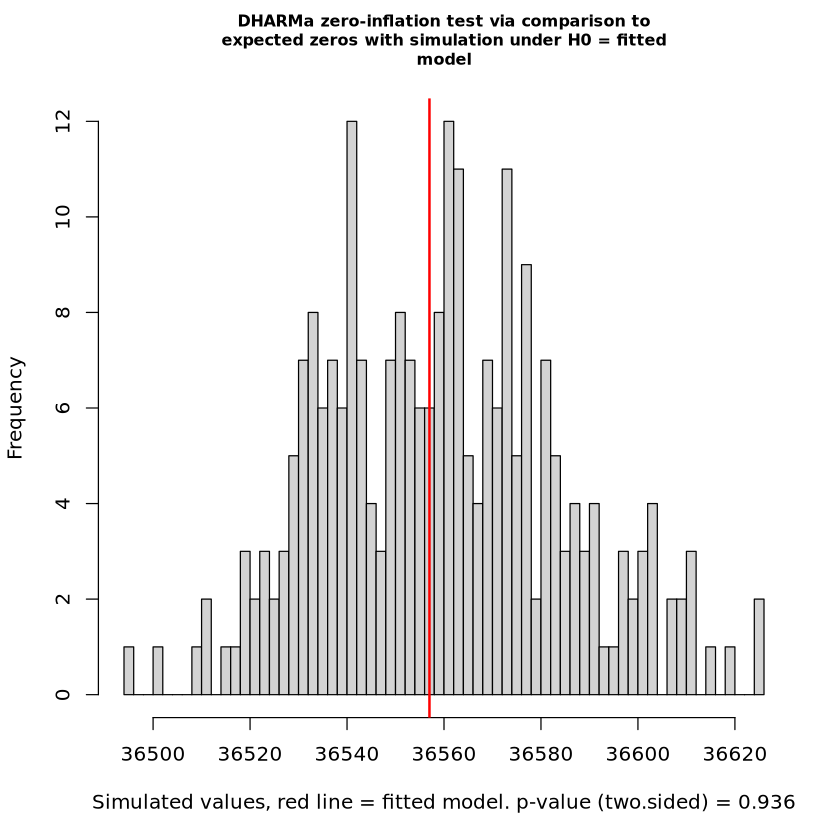

[1] "Full"


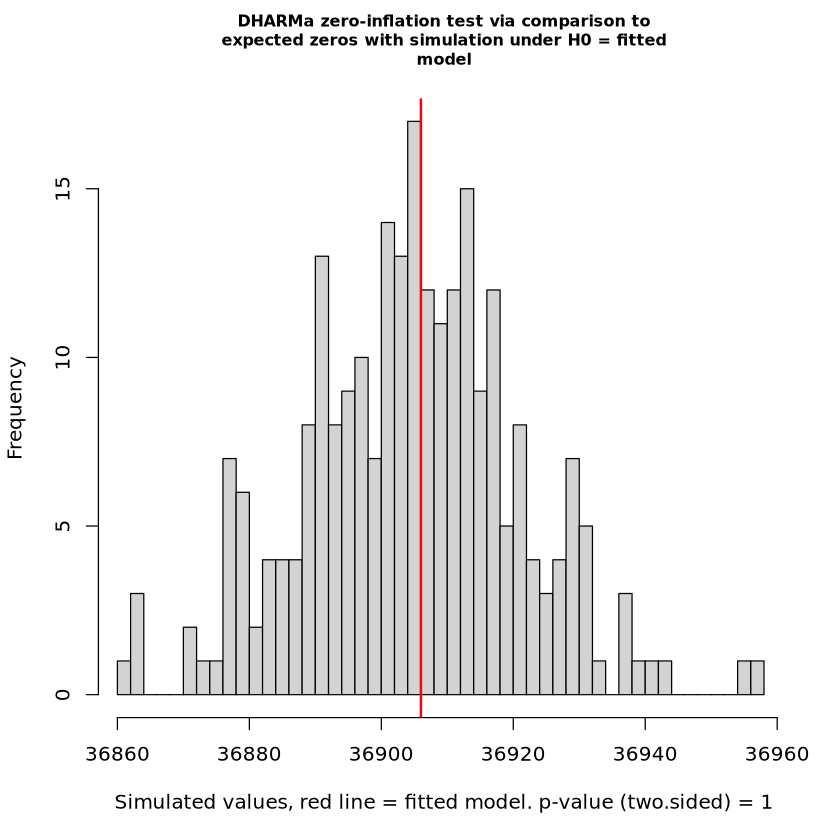

[1] "Full"


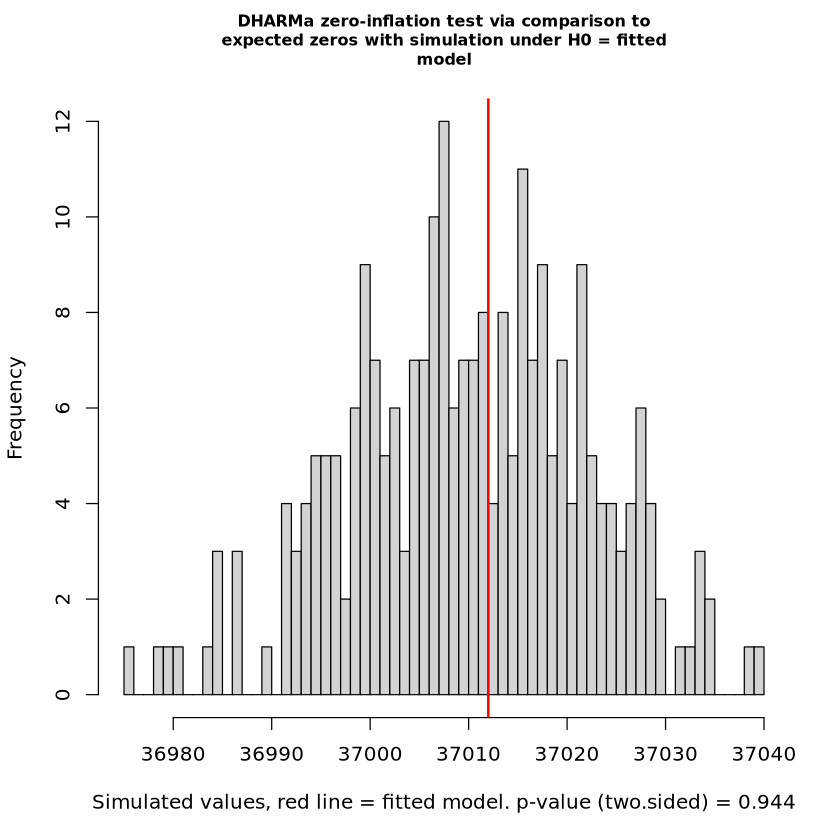

[1] "Full"


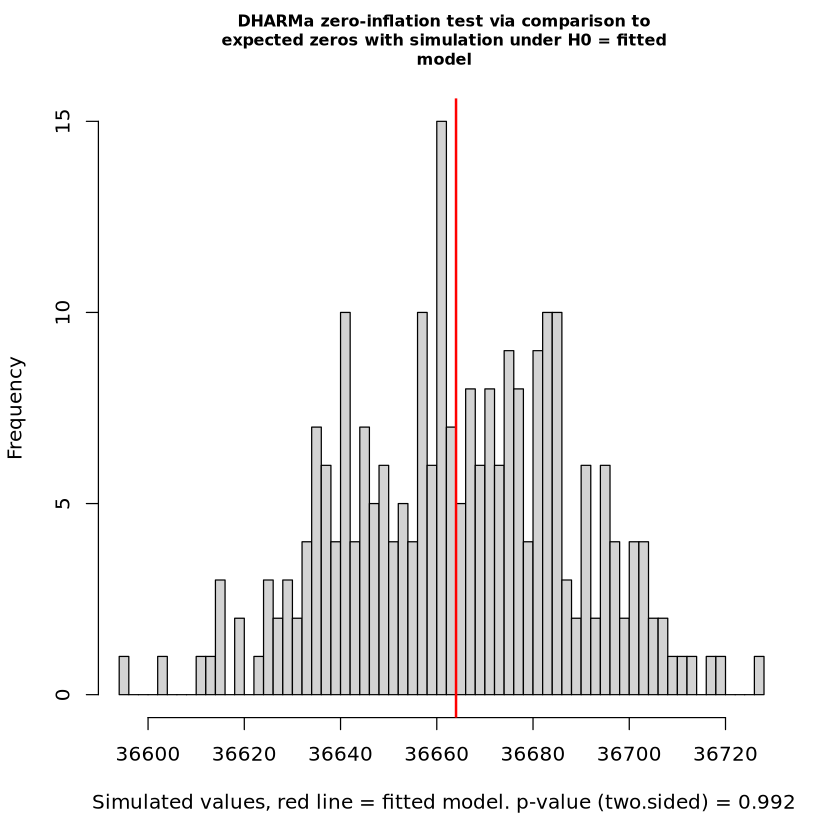

[1] "Full"


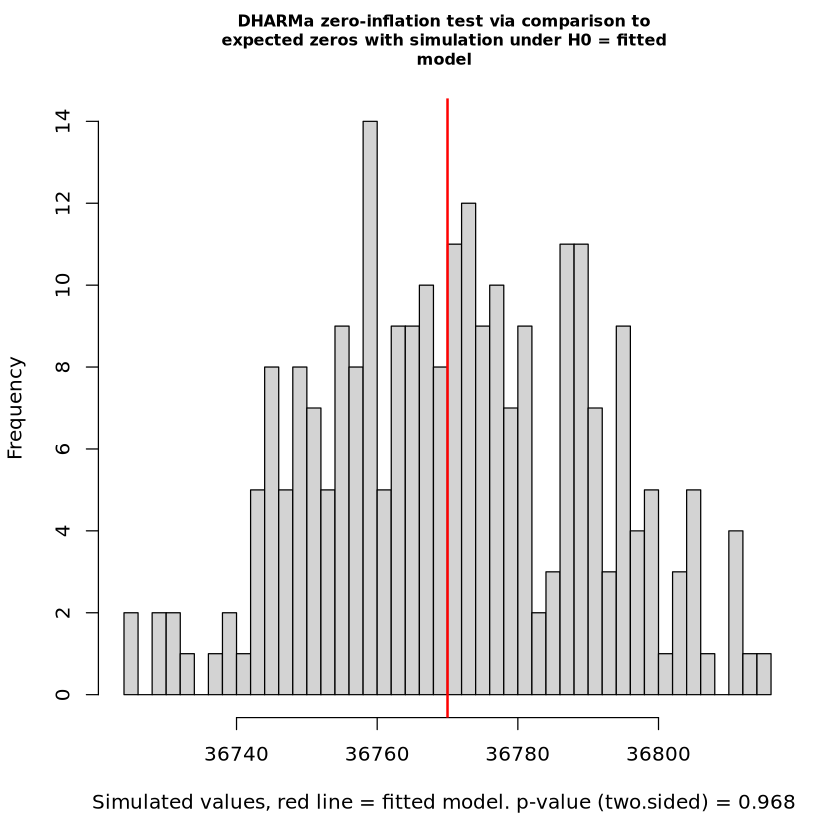

[1] "Full"


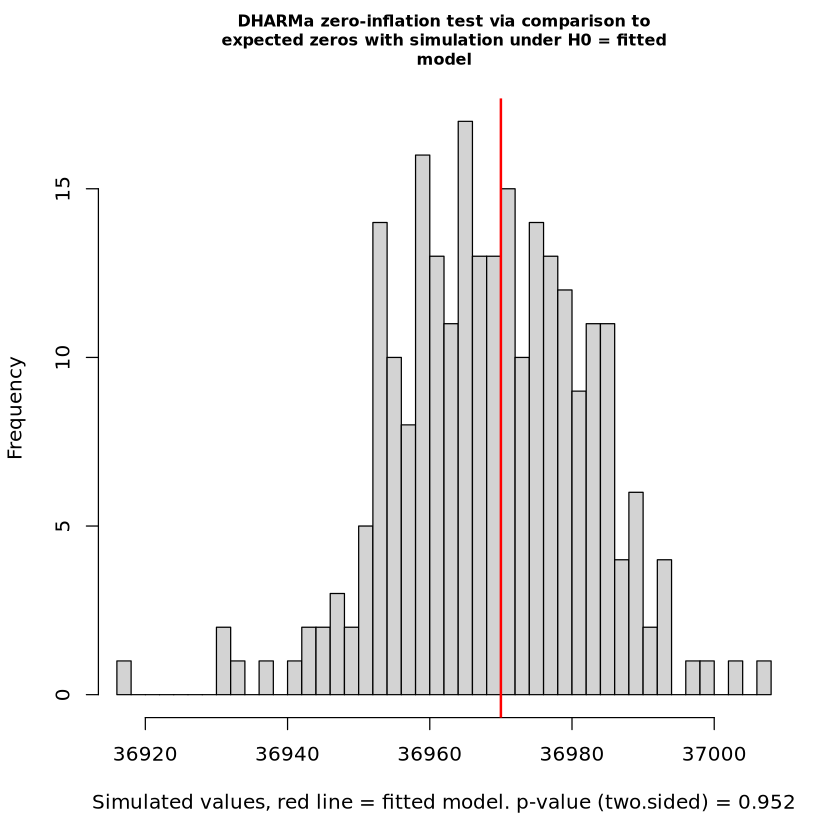

[1] "Full"


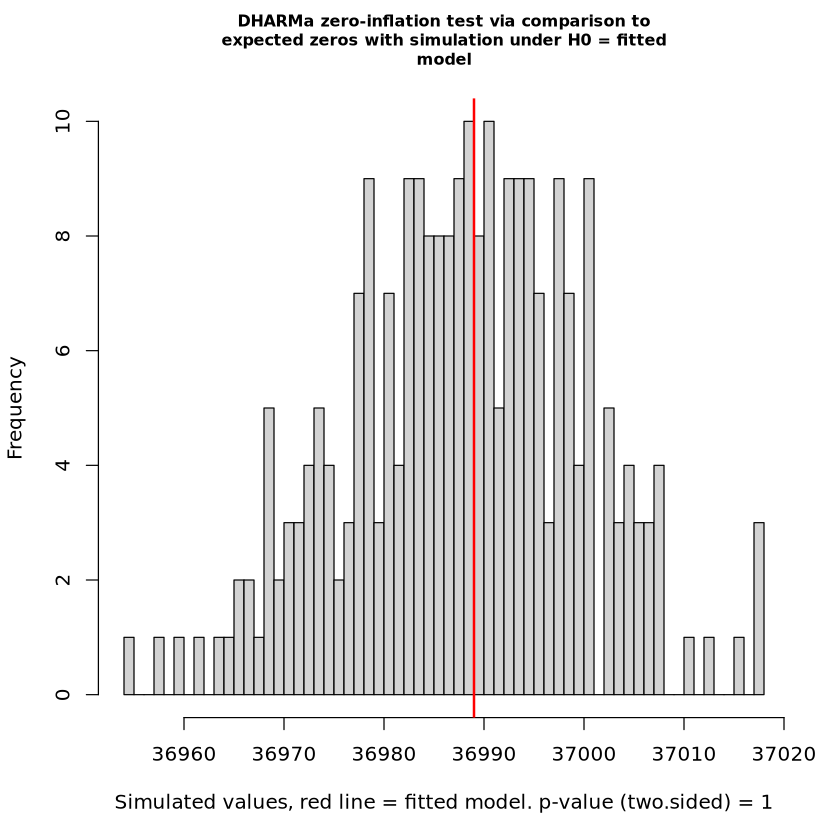

[1] "Full"


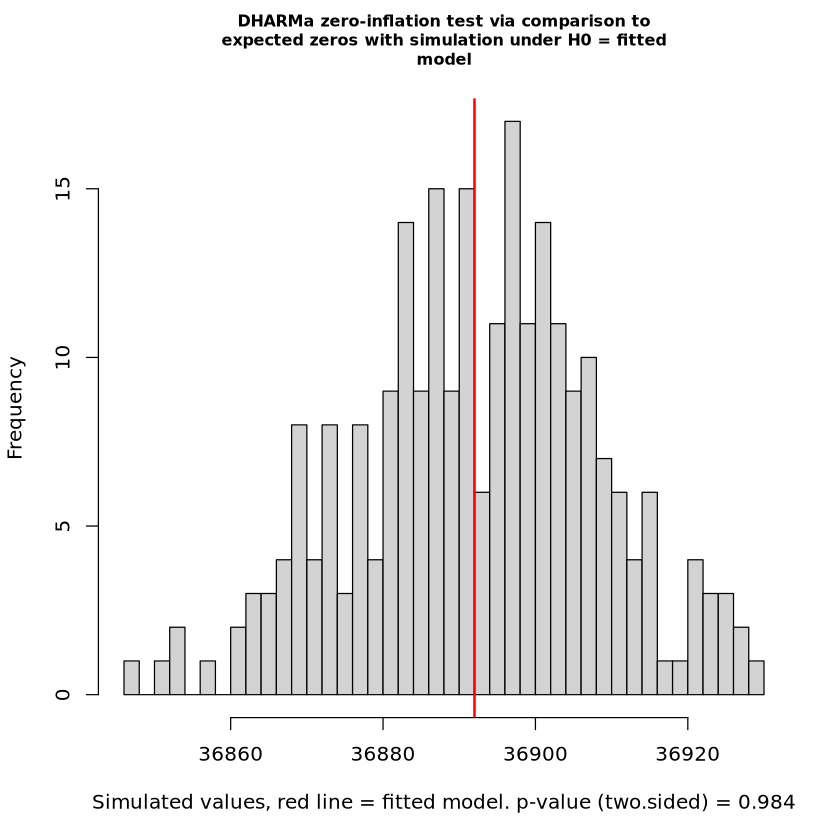

[1] "Full"


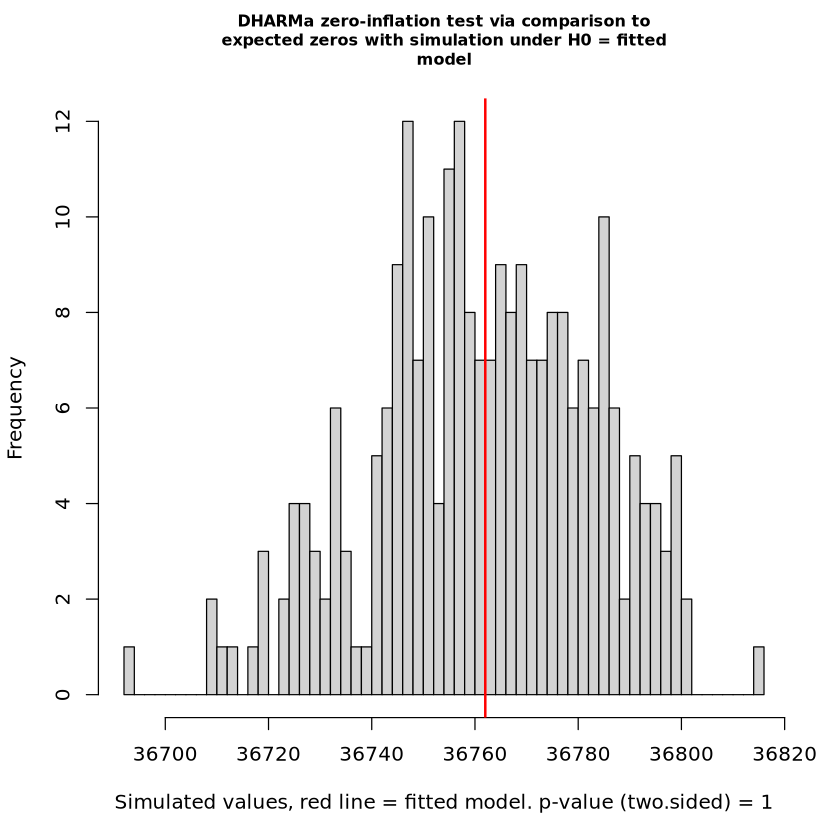

[1] "Full"


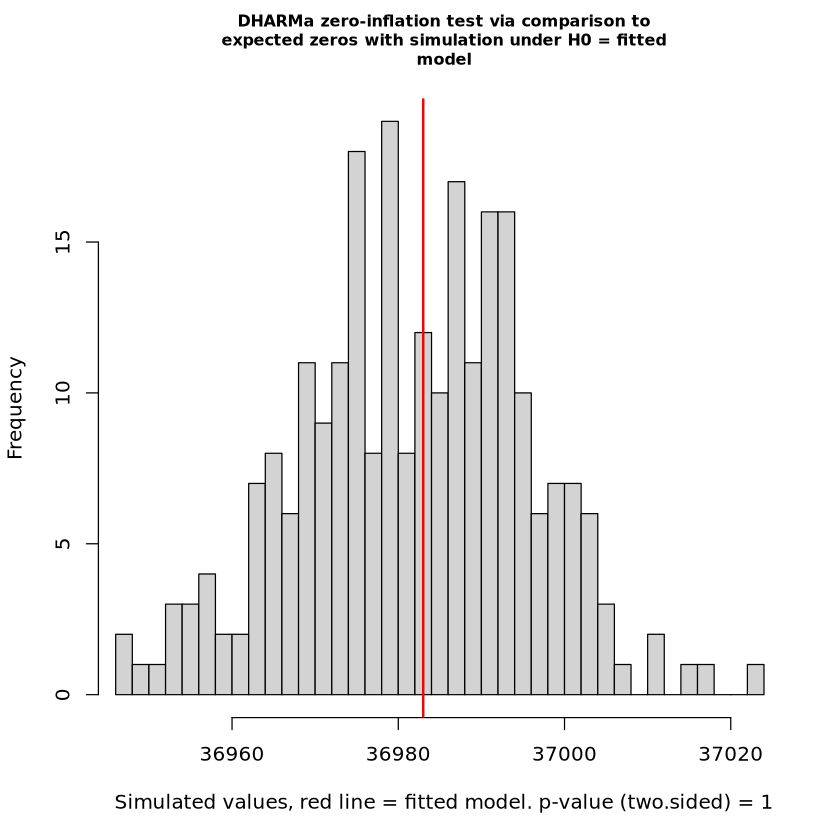

[1] "Full"


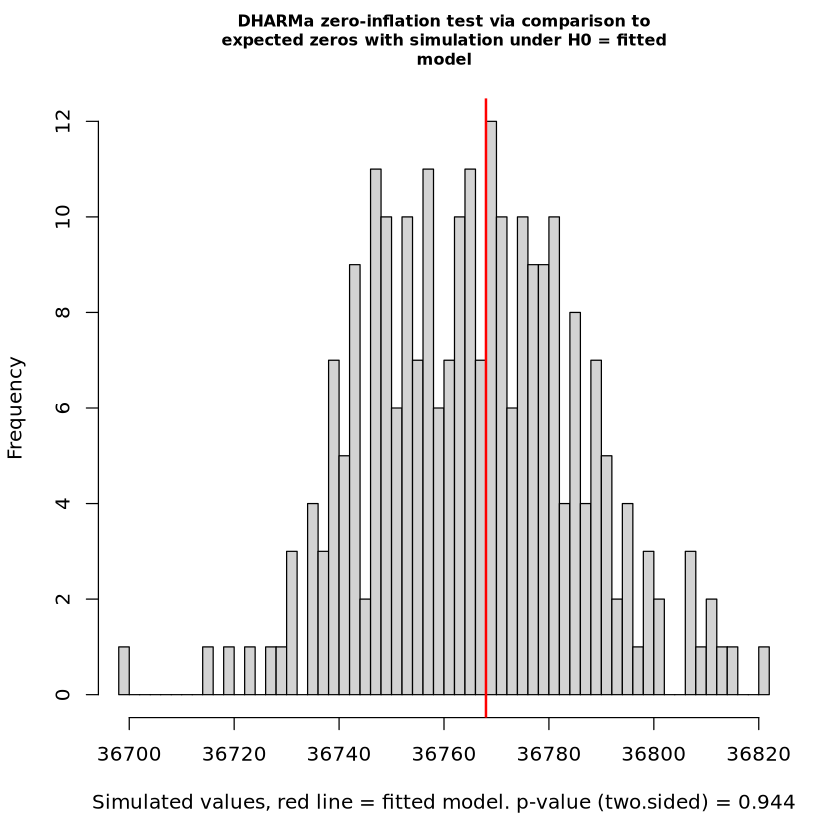

[1] "Full"


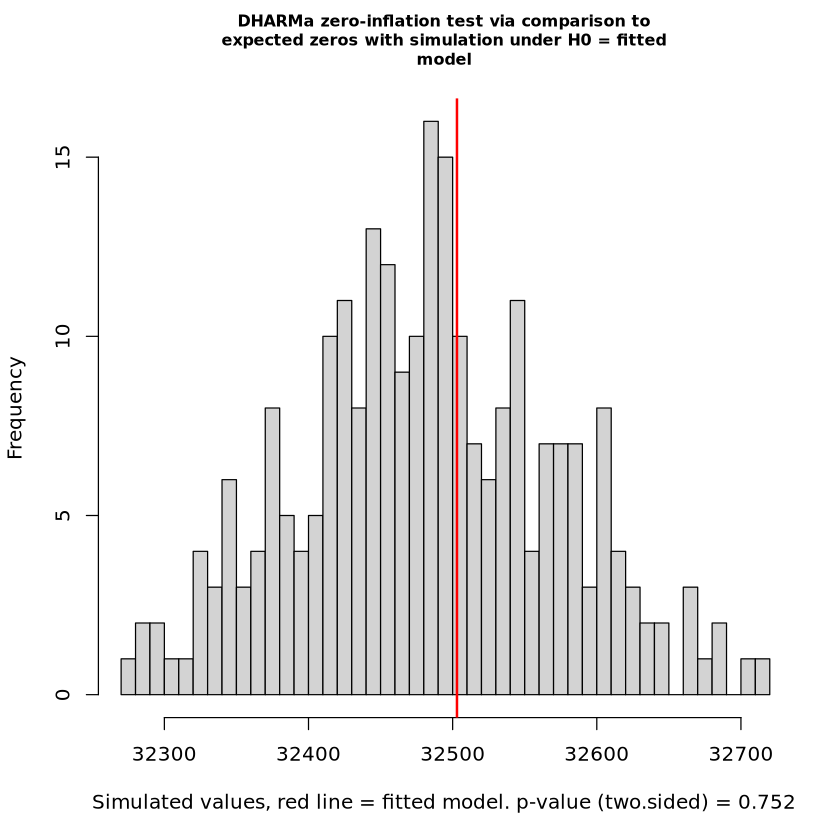

[1] "Full"


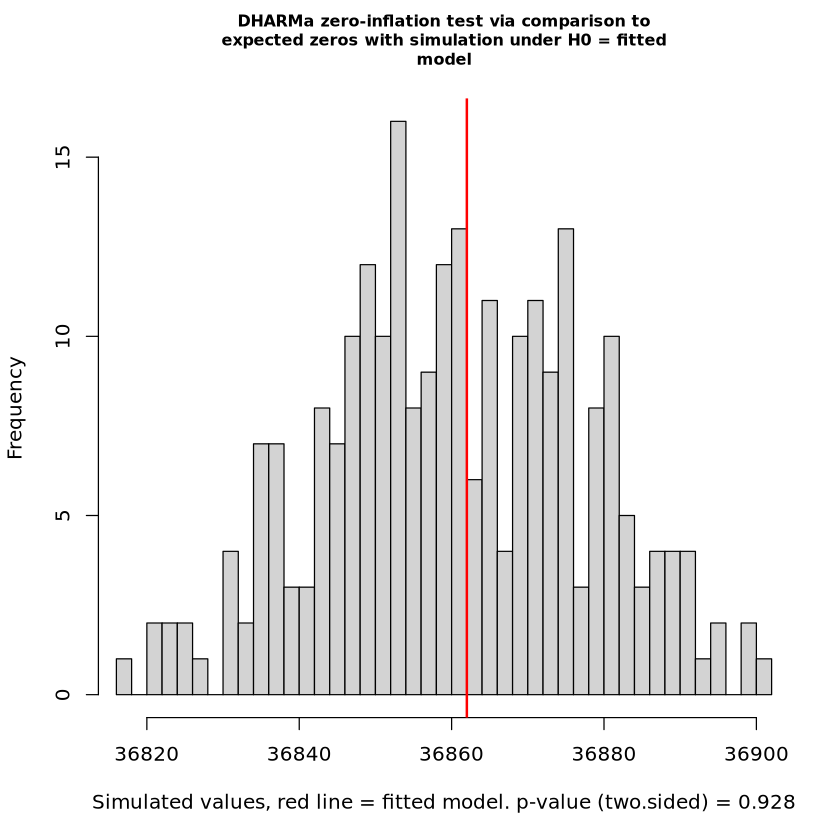

[1] "Full"


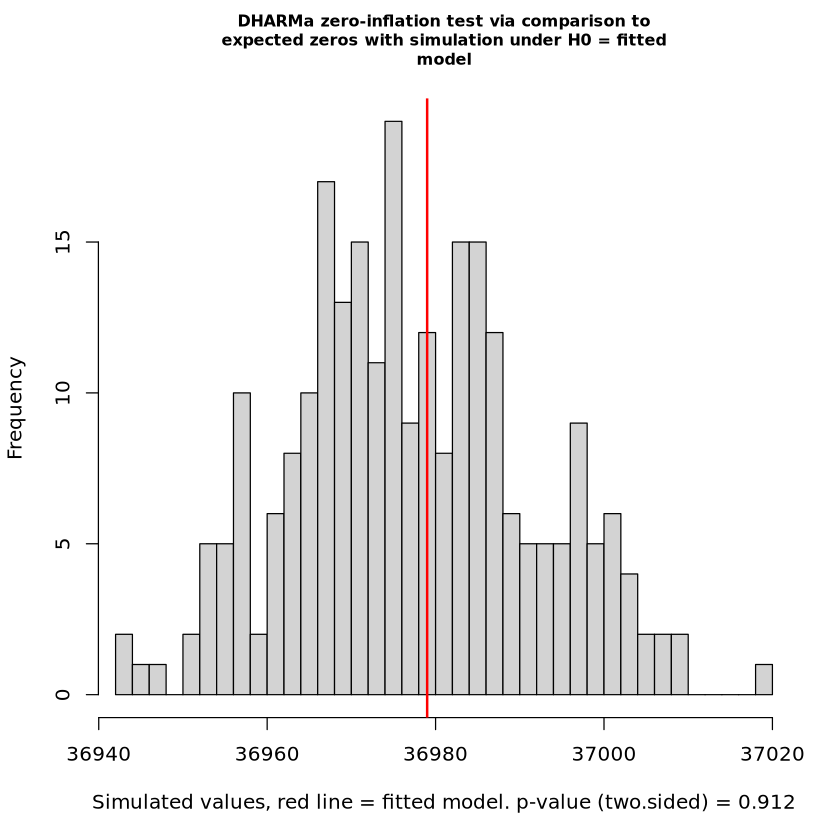

[1] "Full"


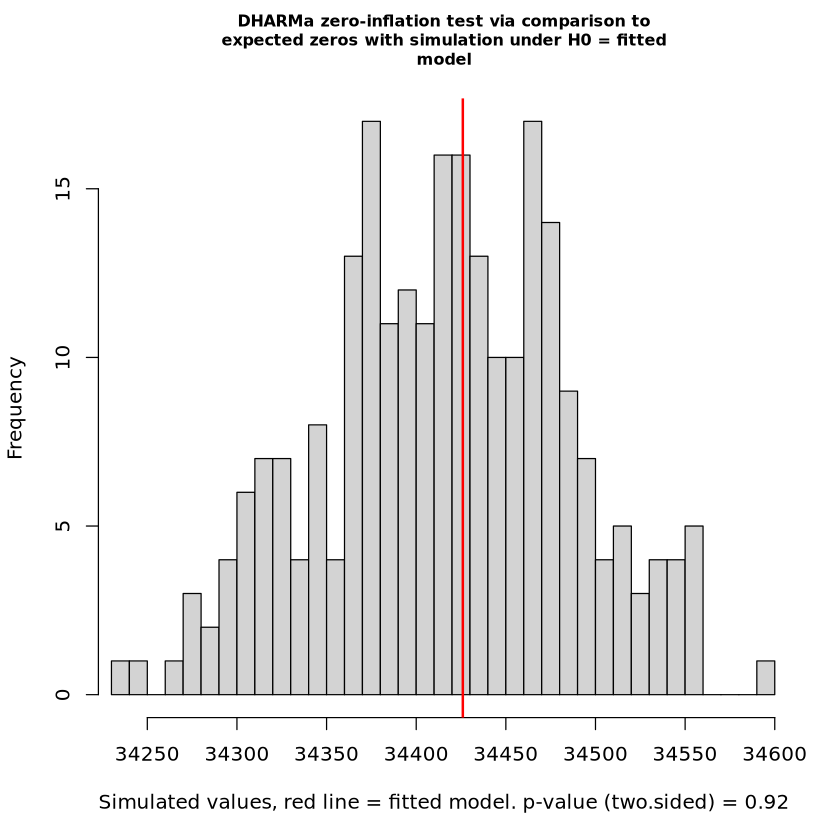

[1] "Full"


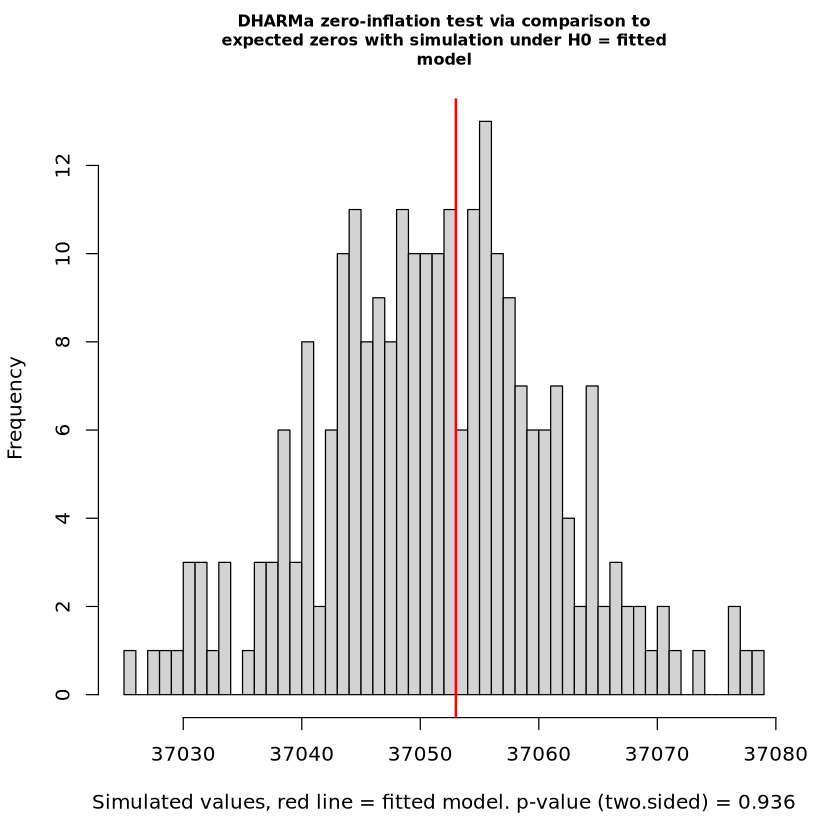

[1] "Full"


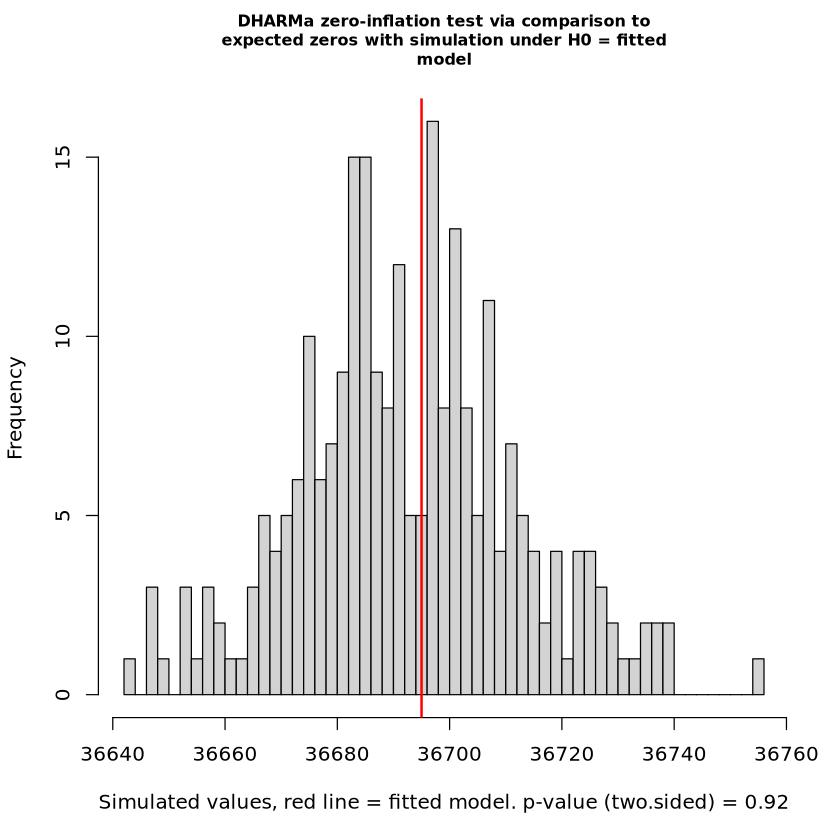

[1] "Full"


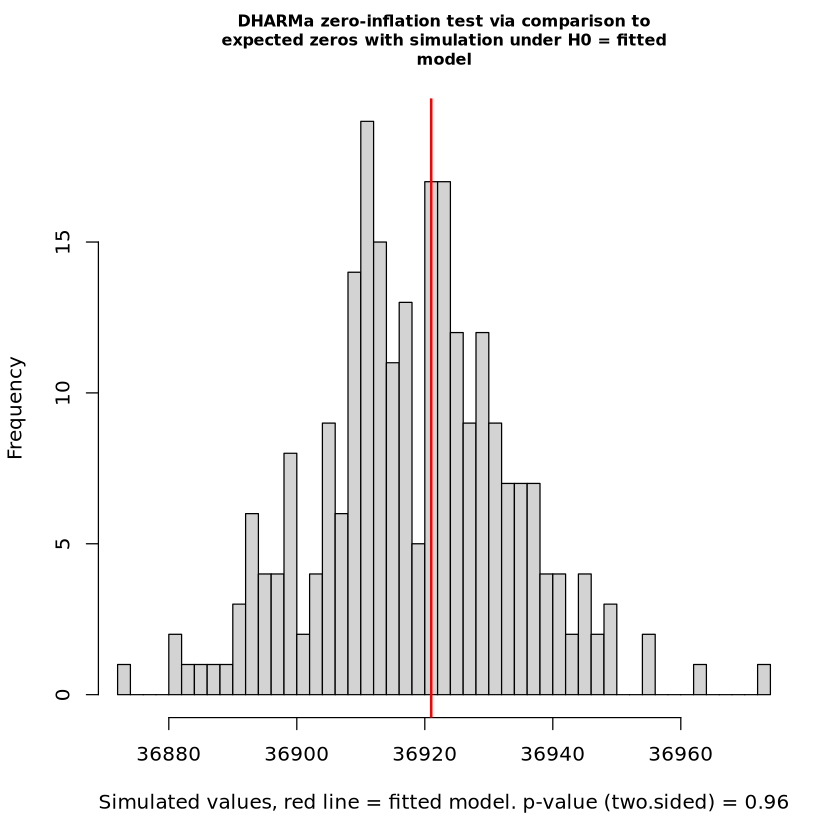

[1] "Full"


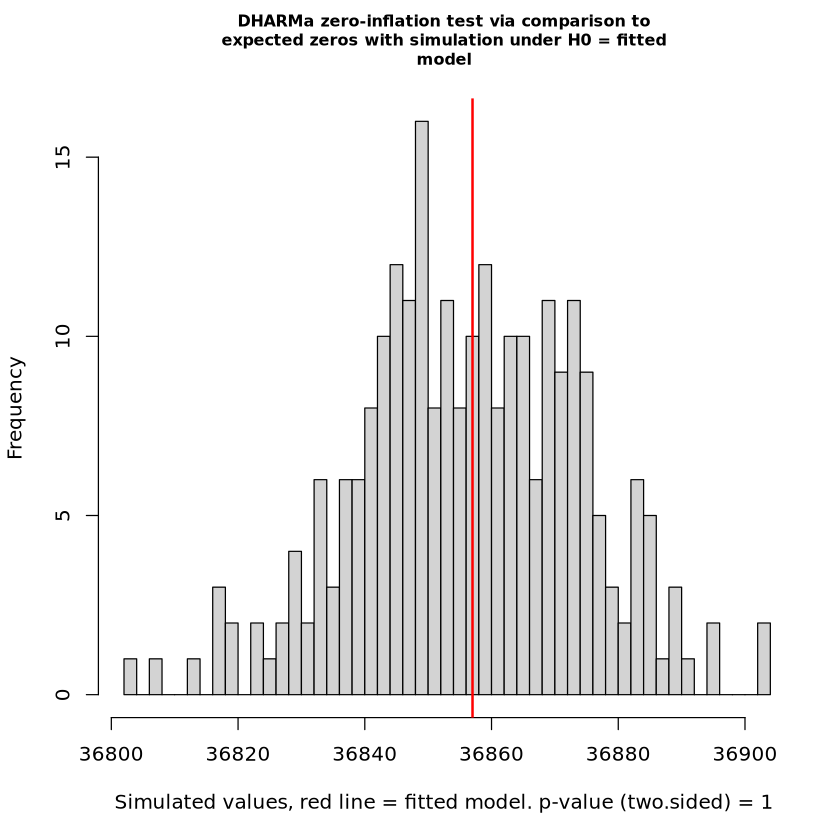

[1] "Full"


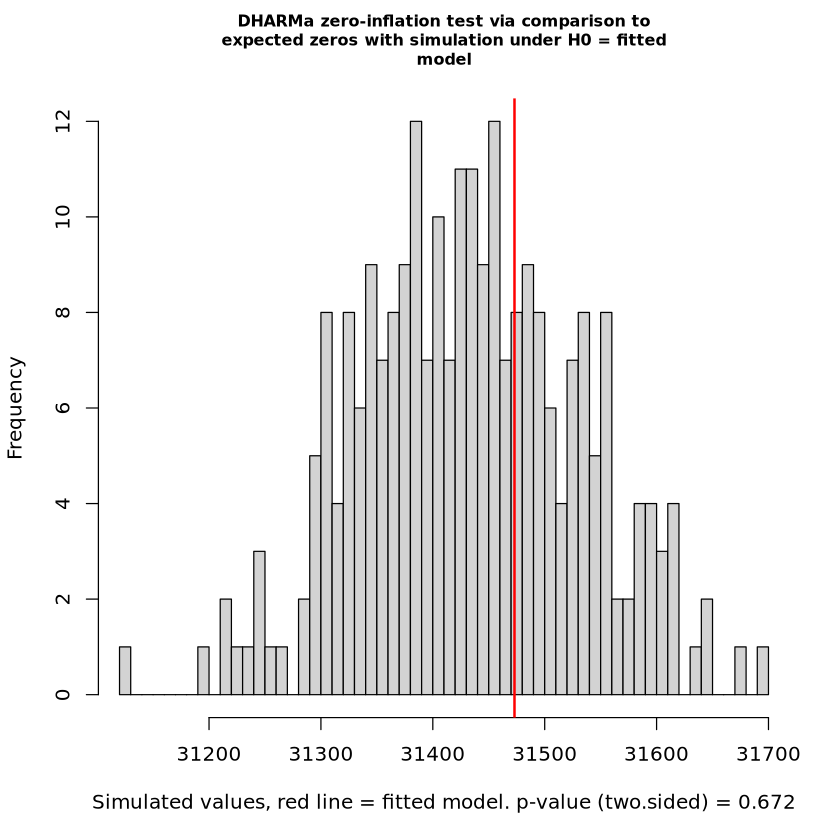

[1] "Full"


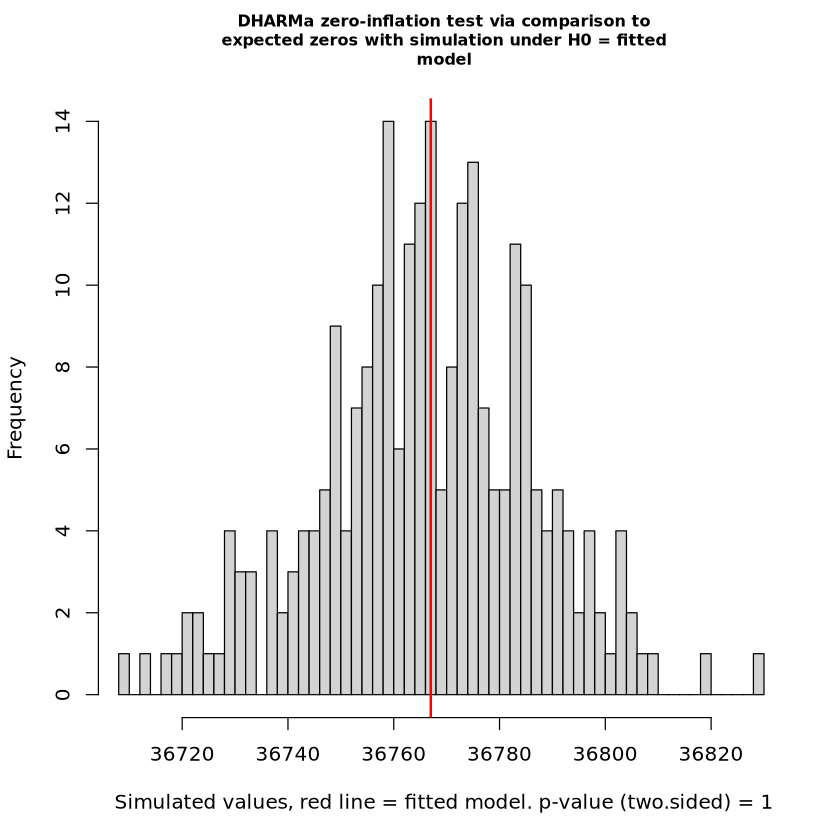

[1] "Full"


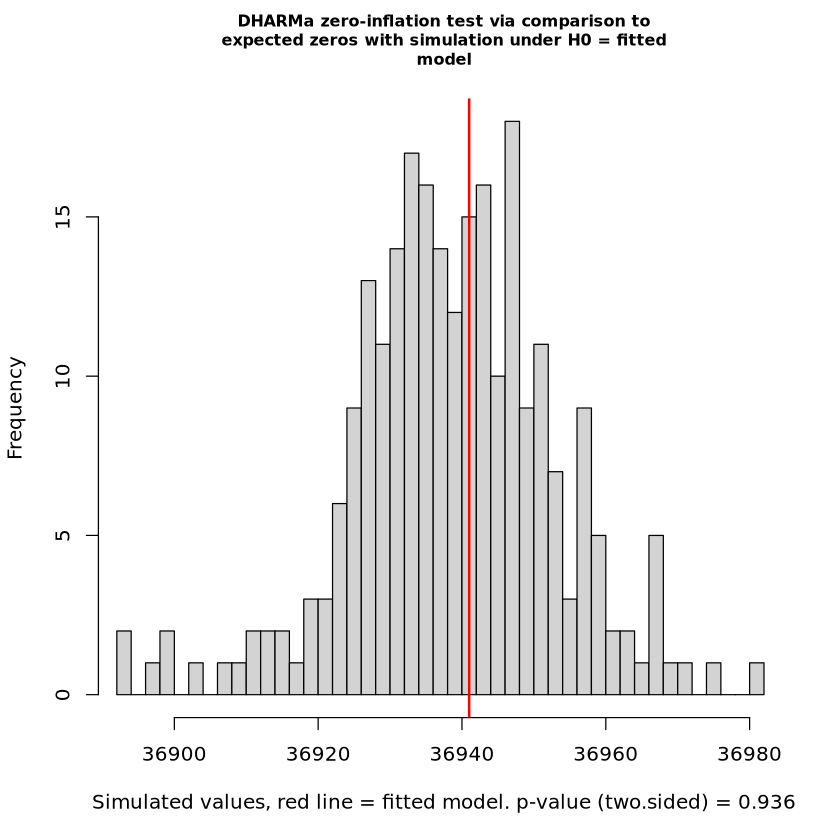

[1] "Full"


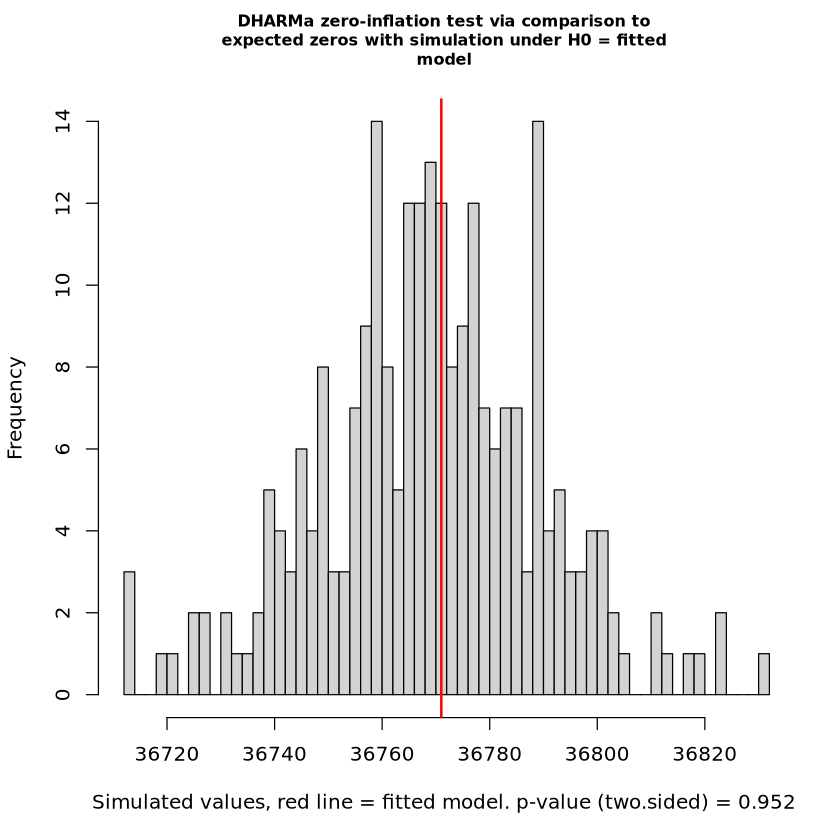

[1] "Full"


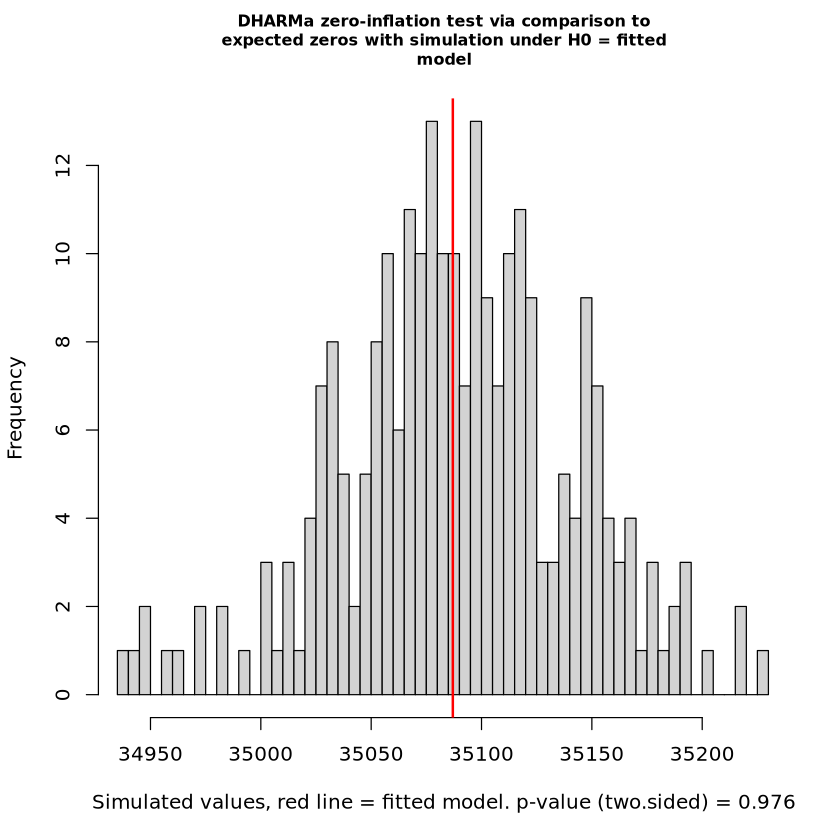

[1] "Full"


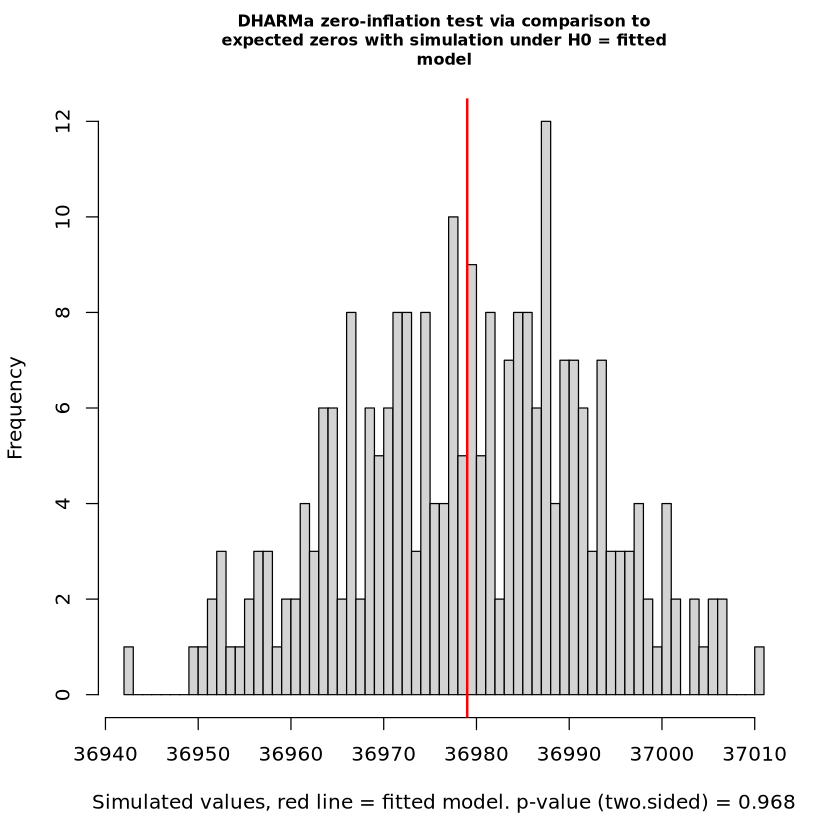

[1] "Full"


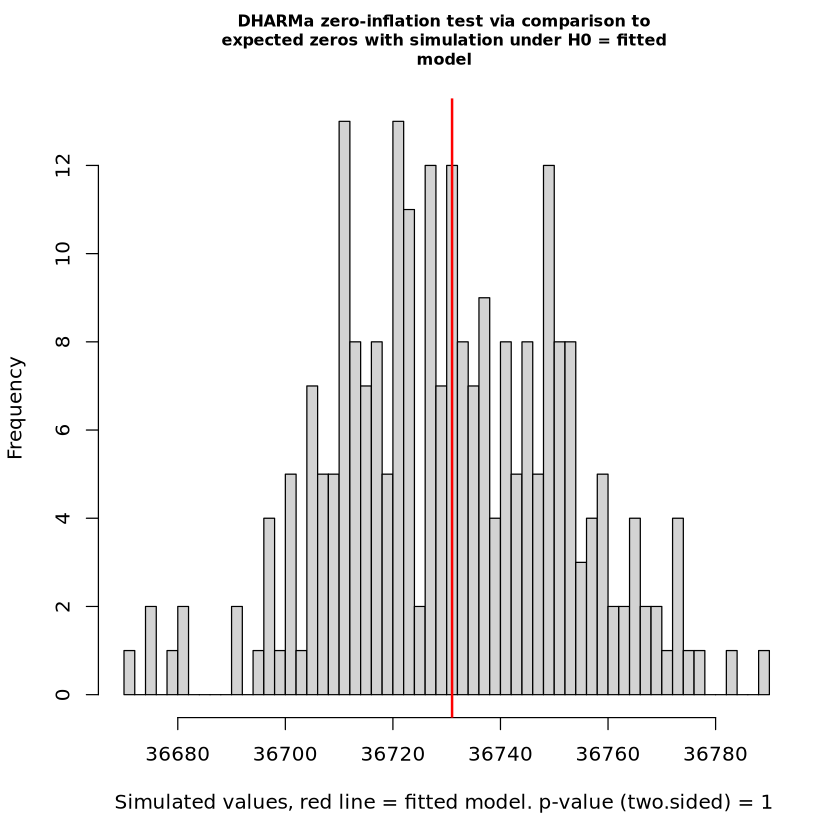

[1] "Full"


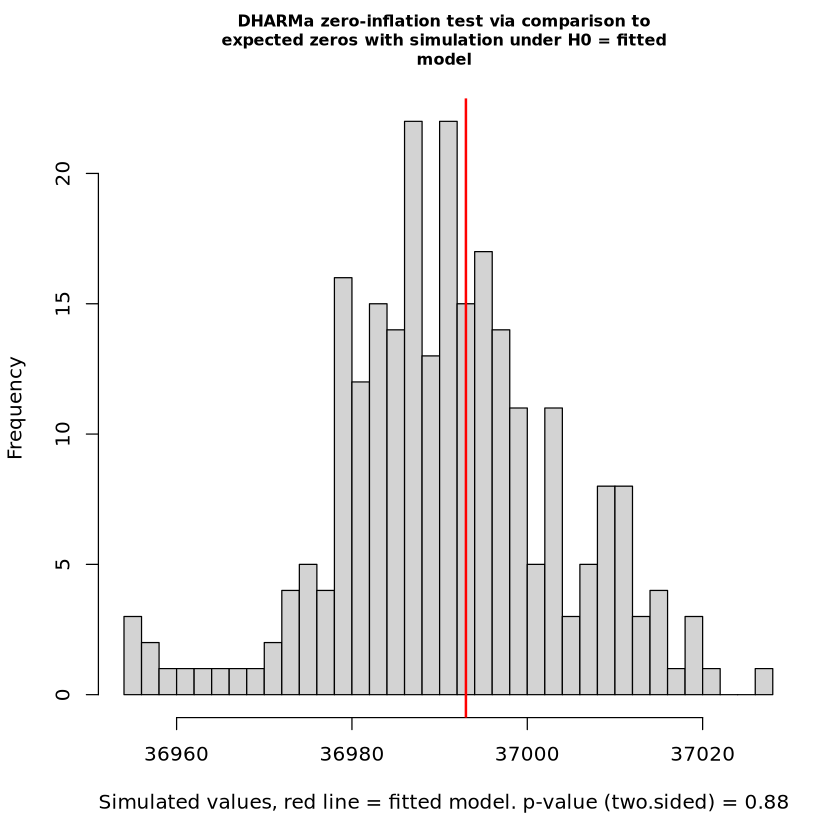

[1] "Full"


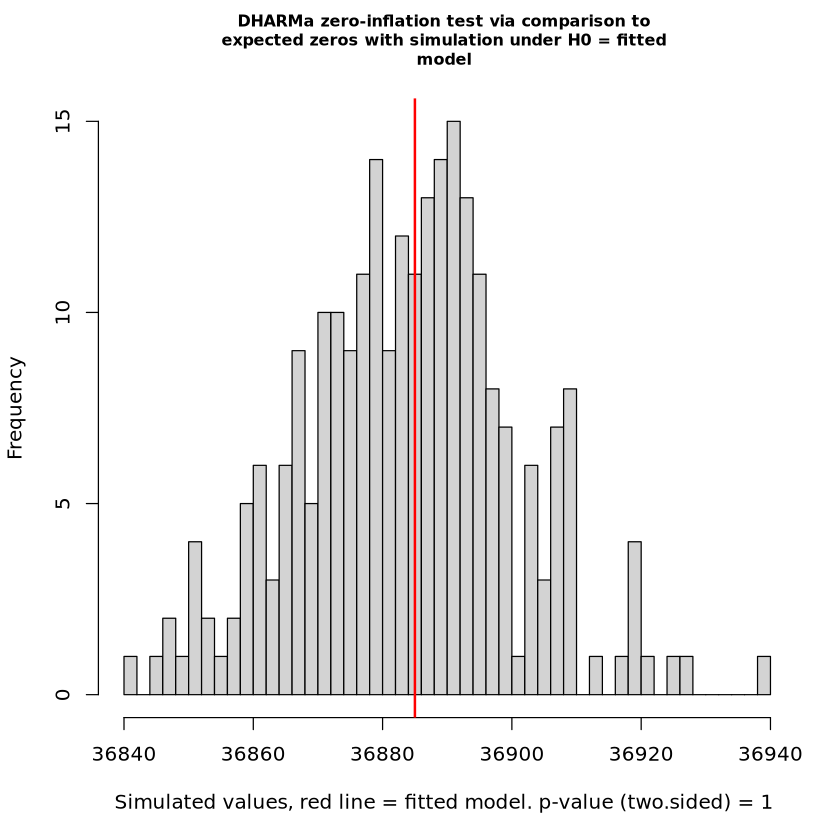

[1] "Full"


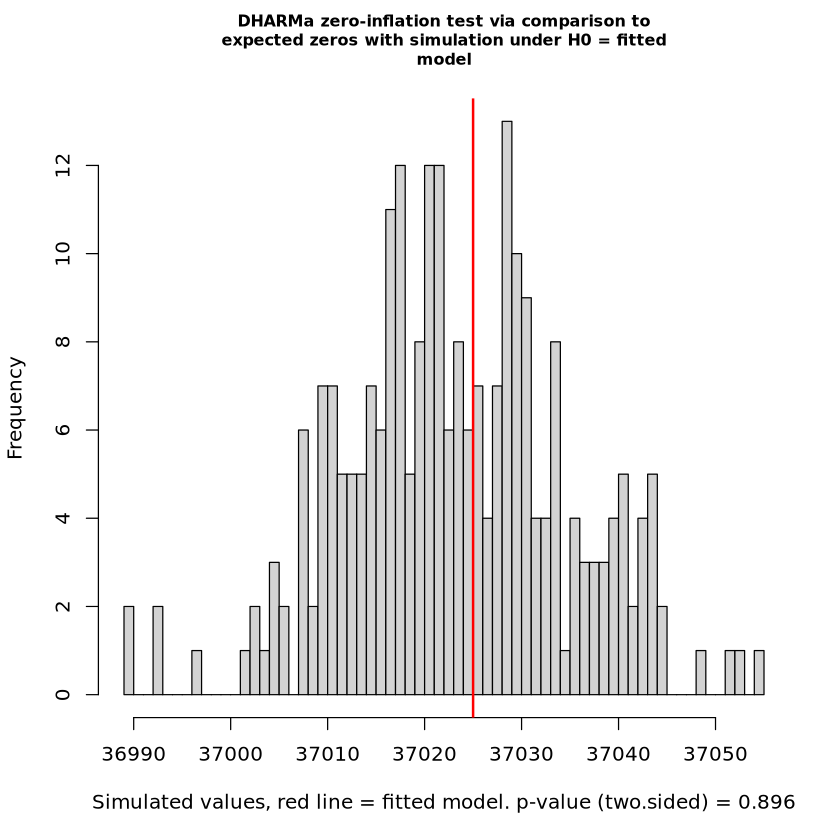

[1] "Full"


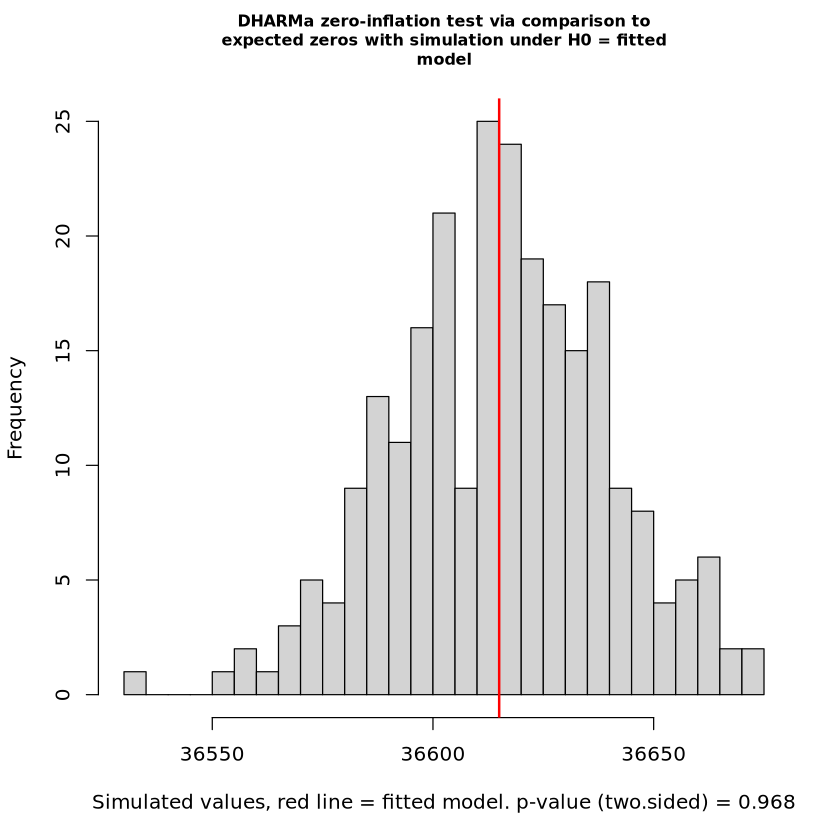

[1] "Full"


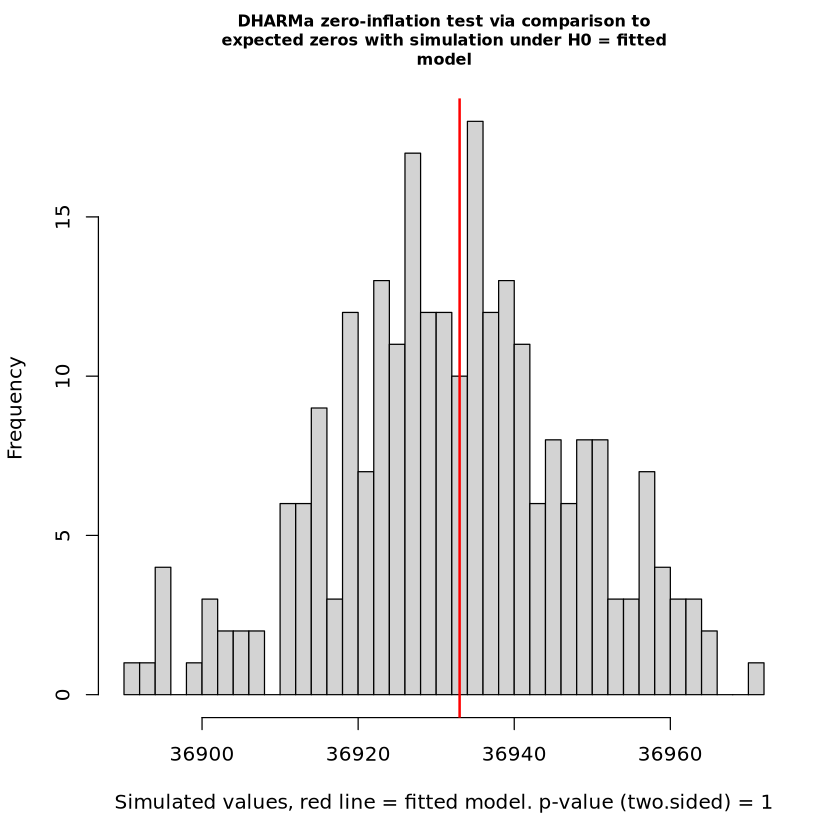

[1] "Full"


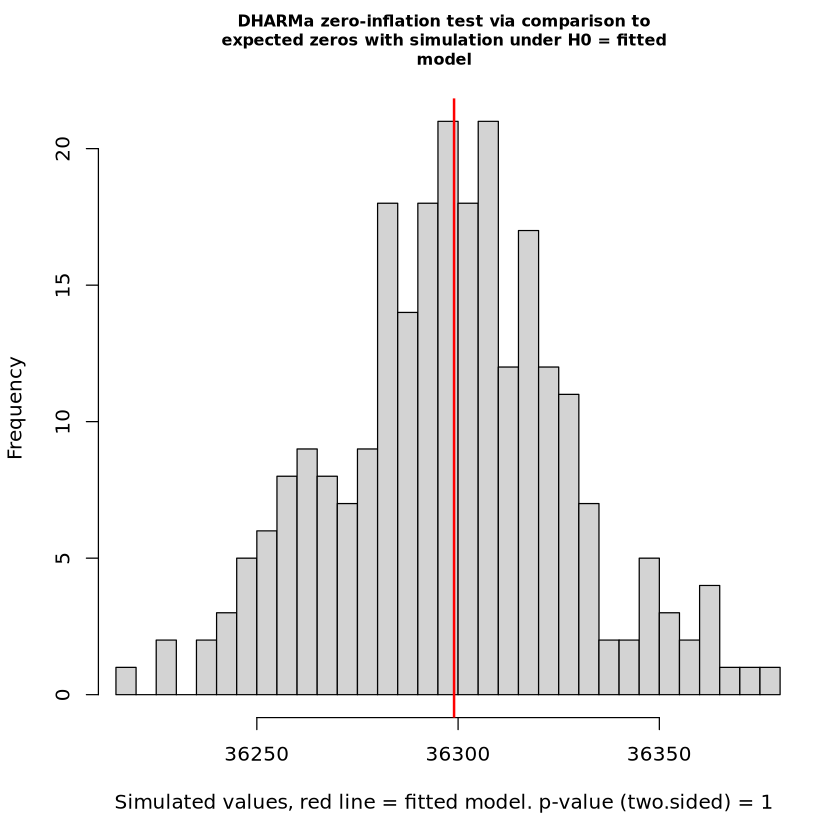

[1] "Full"


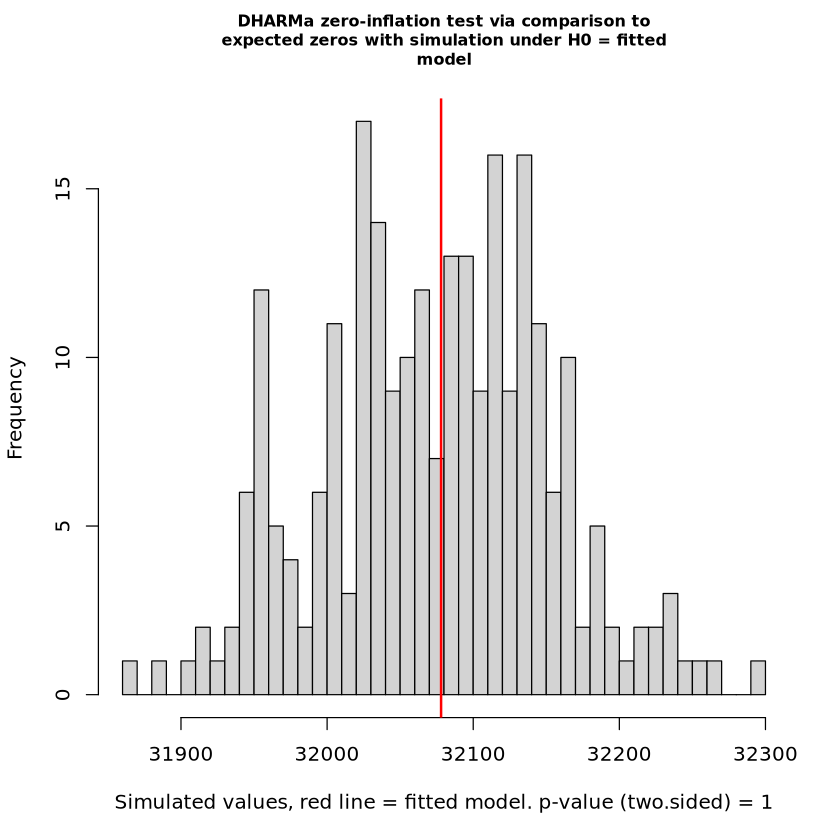

[1] "Full"


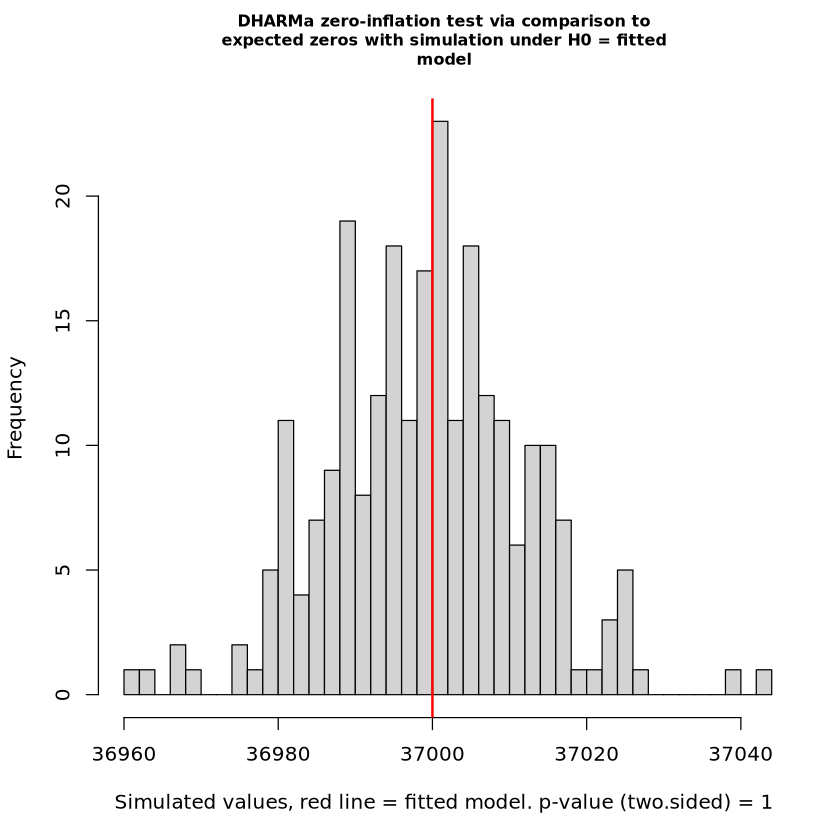

[1] "Full"


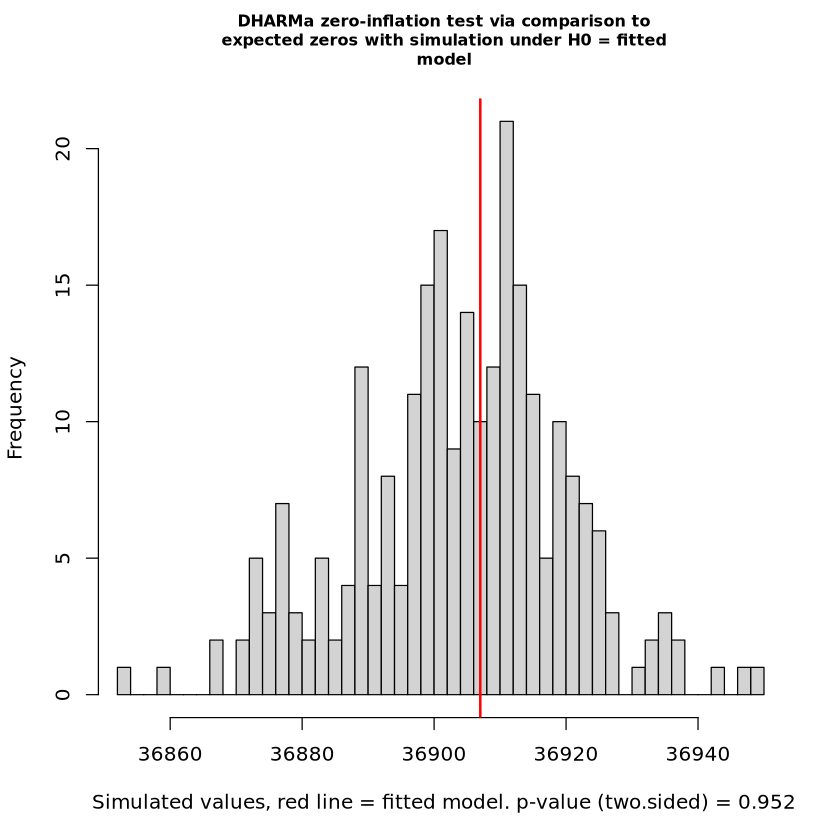

[1] "Full"


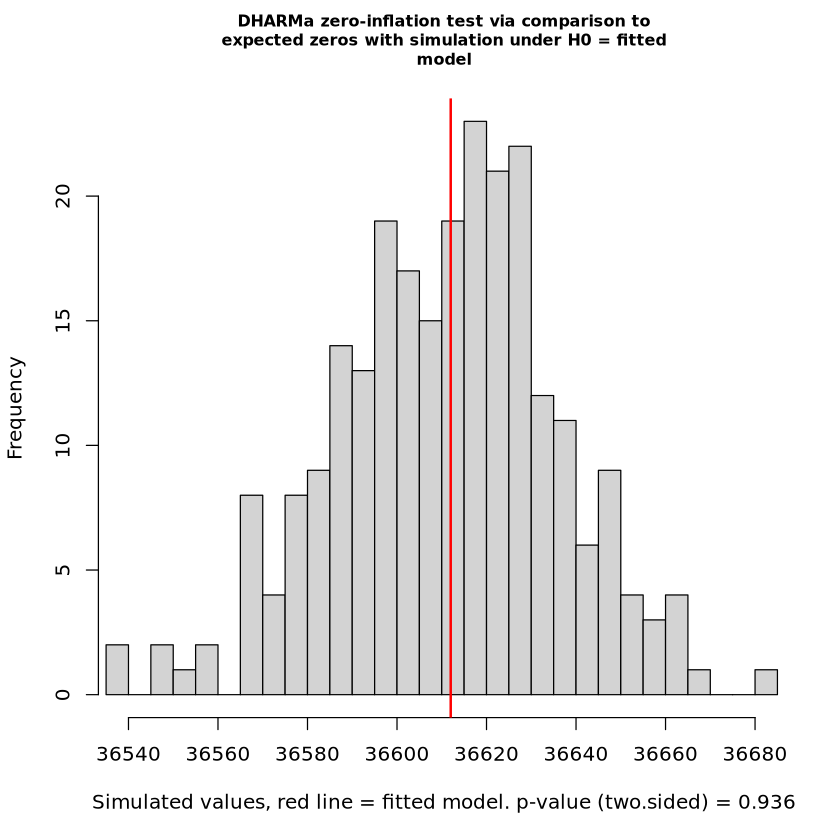

[1] "Full"


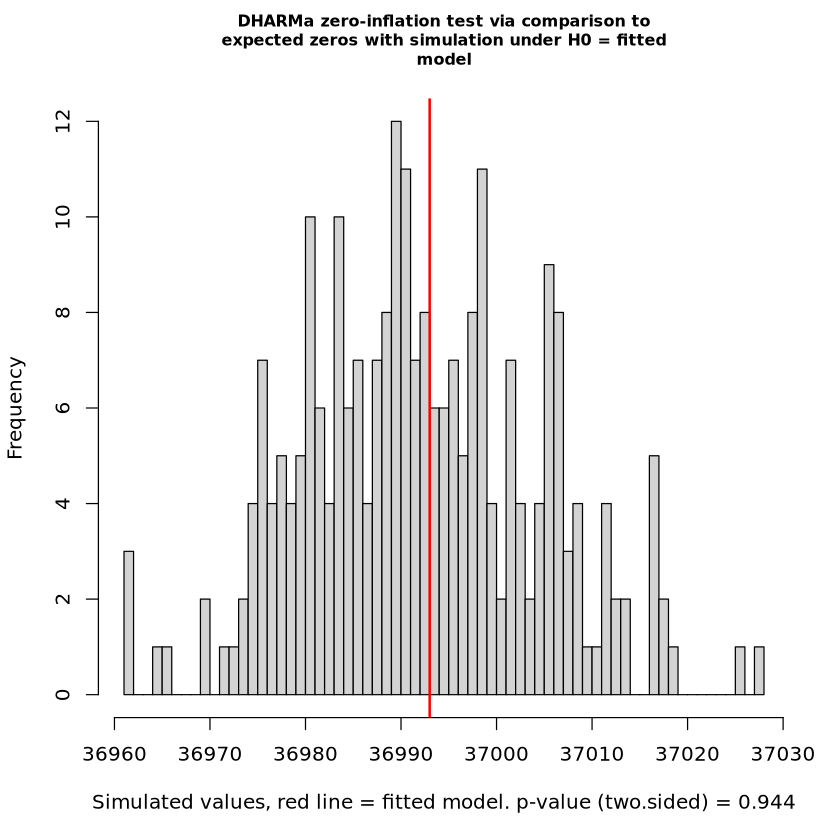

[1] "Full"


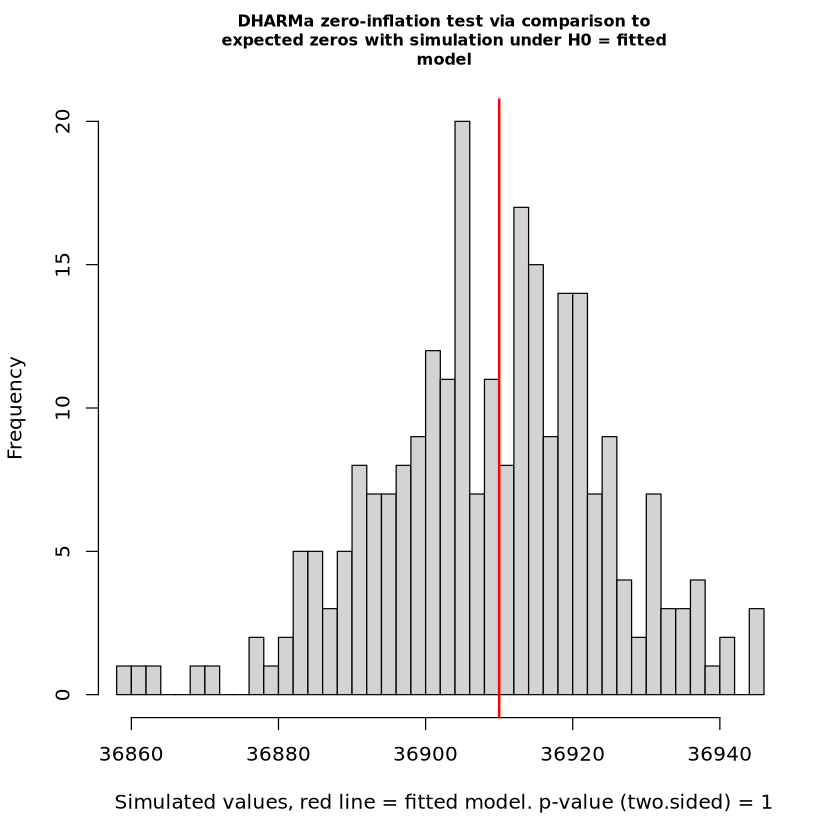

[1] "Full"


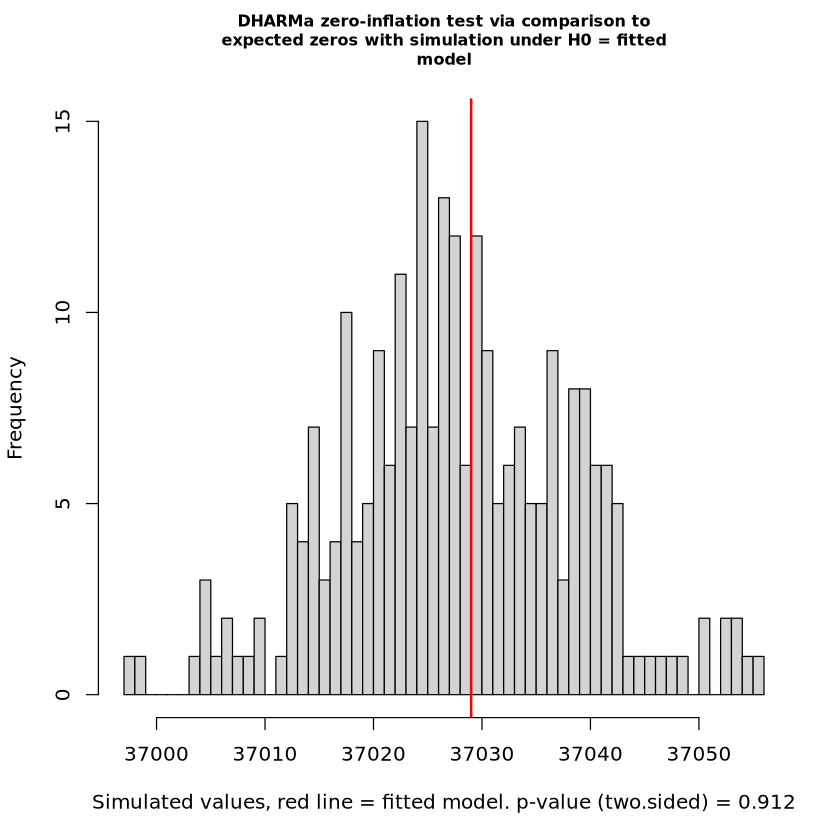

[1] "Full"


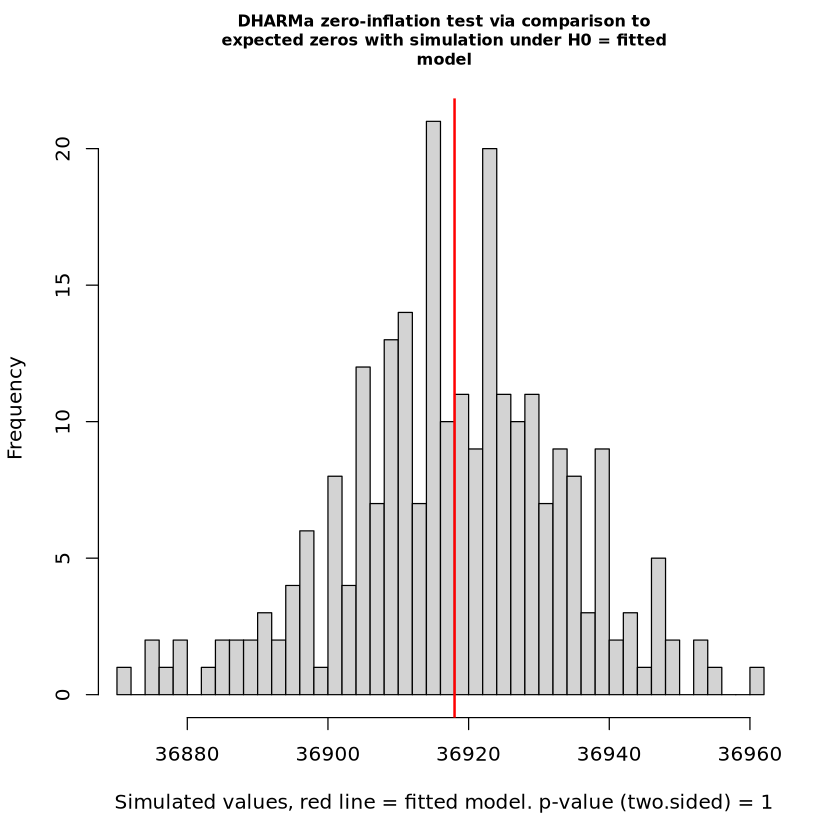

[1] "Full"


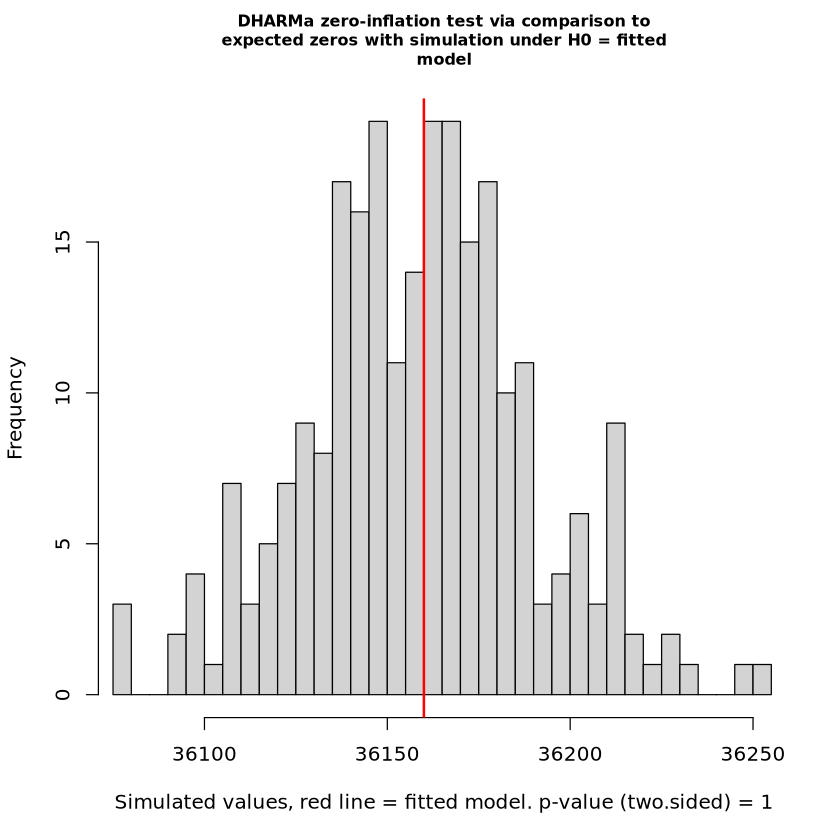

[1] "Full"


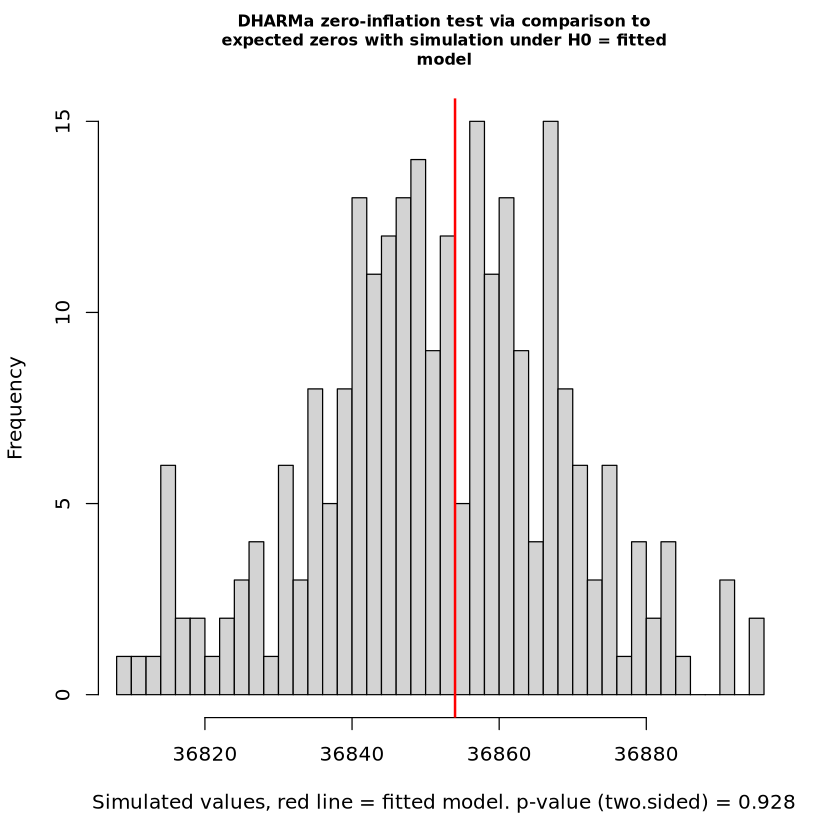

[1] "Full"


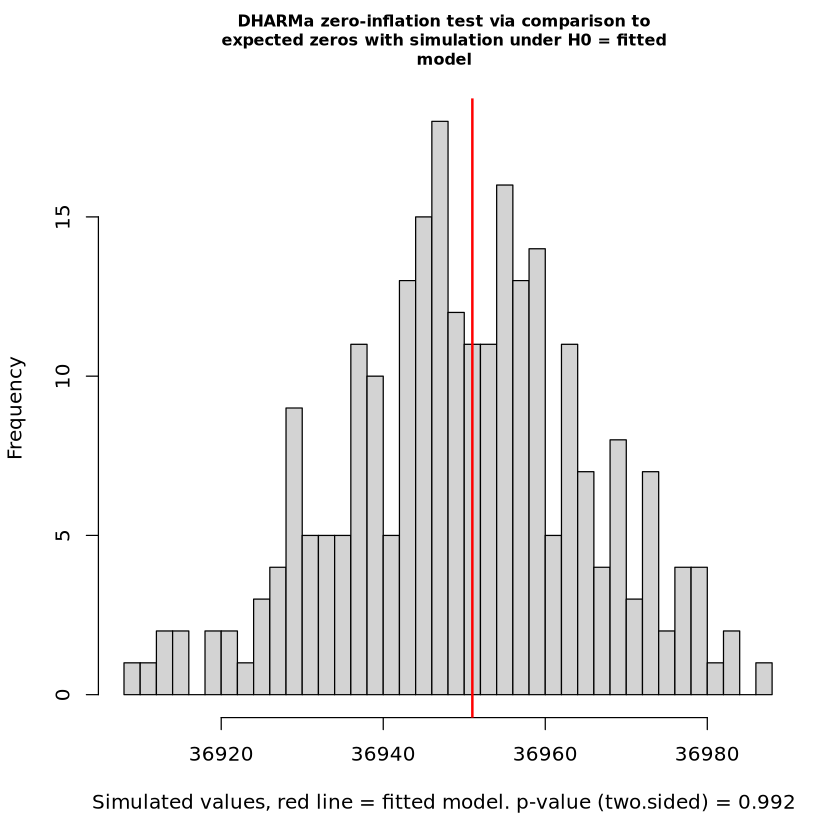

[1] "Full"


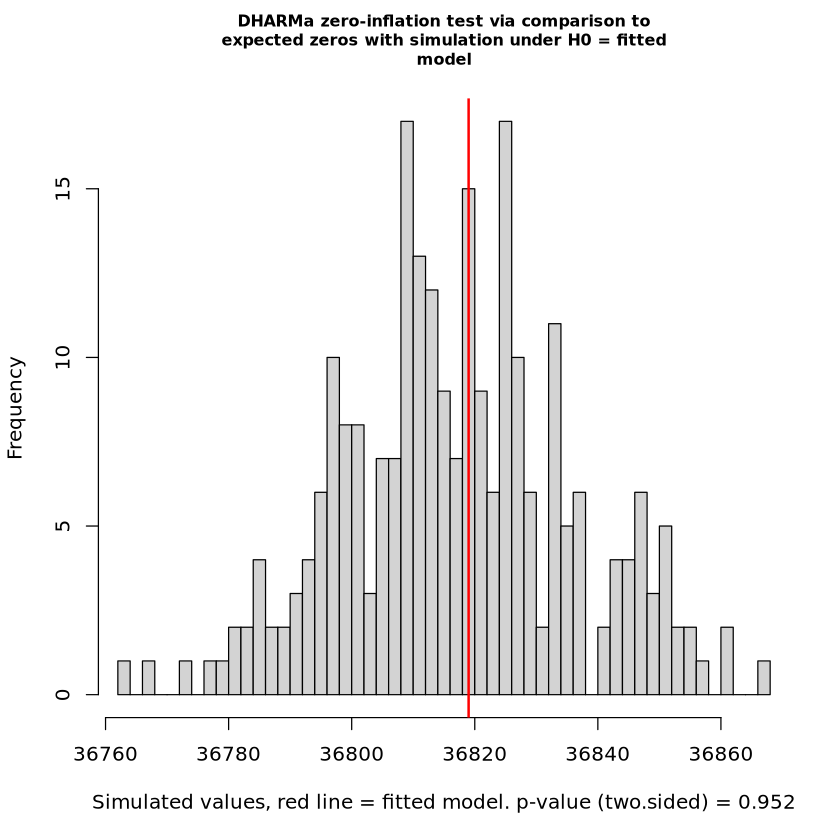

[1] "Full"


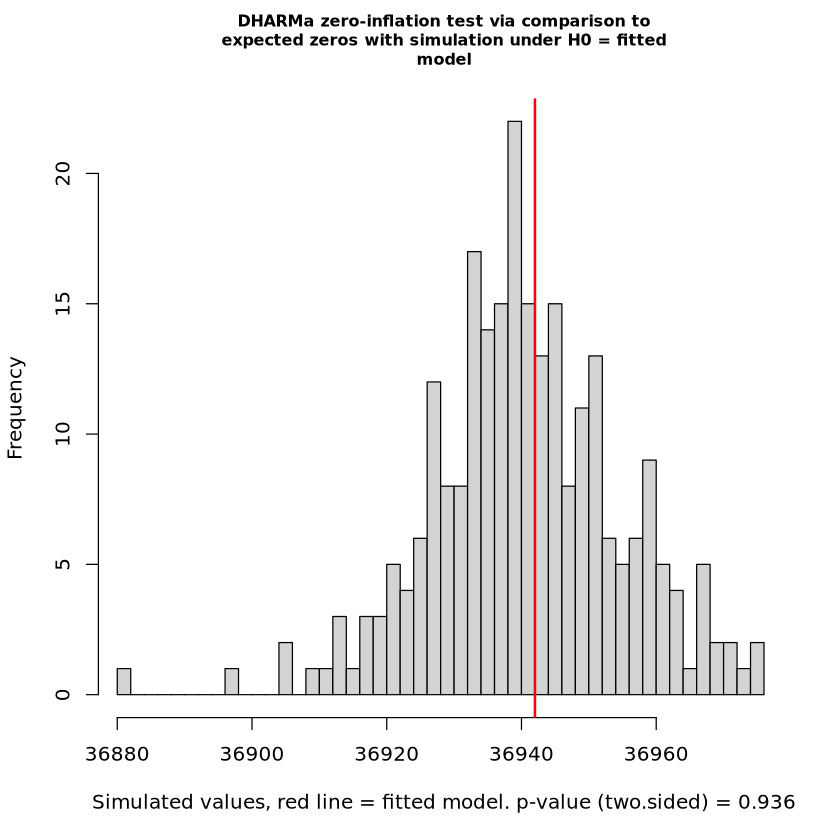

[1] "Full"


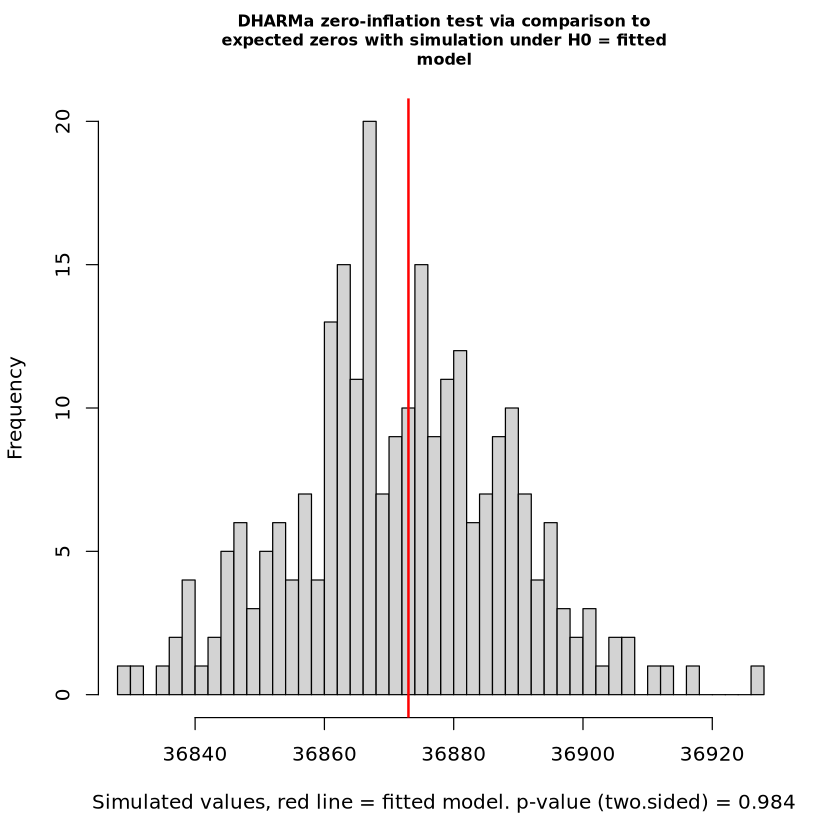

[1] "Full"


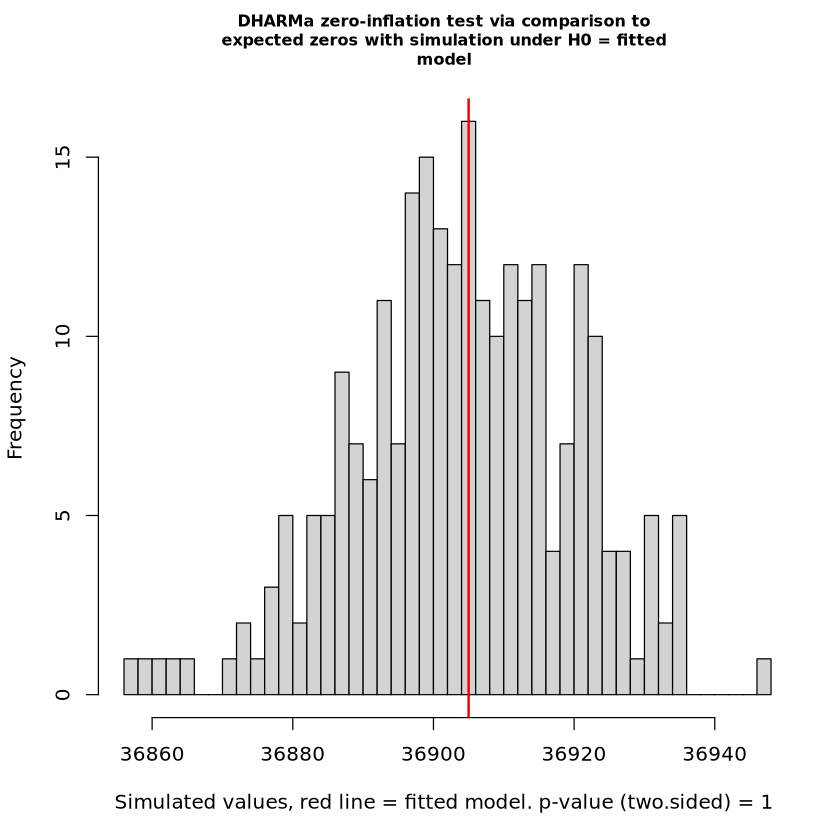

[1] "Full"


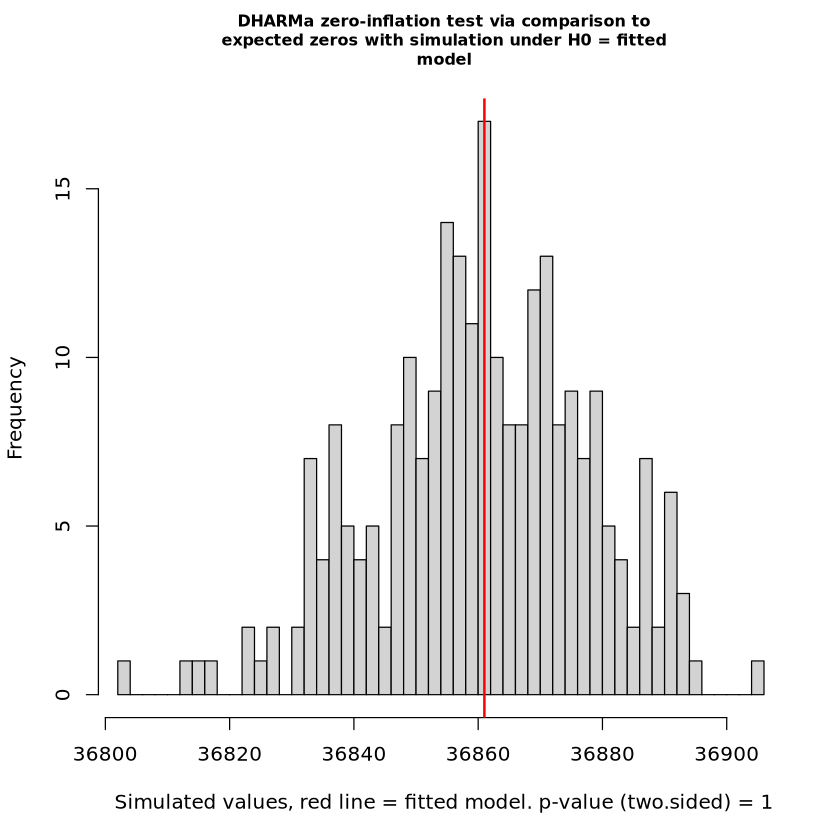

[1] "Full"


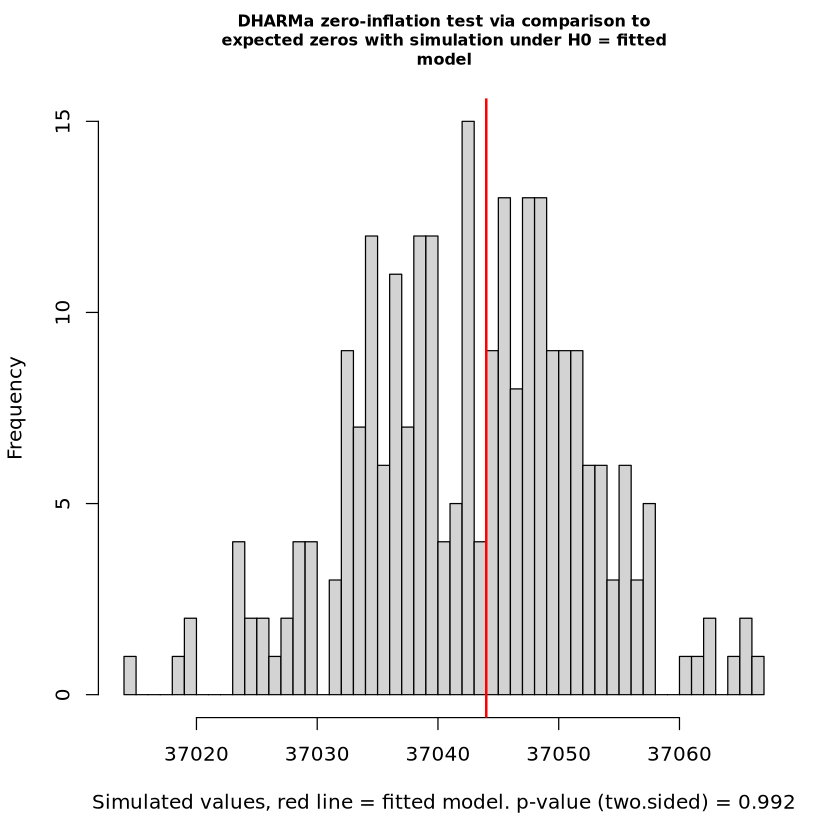

[1] "Full"


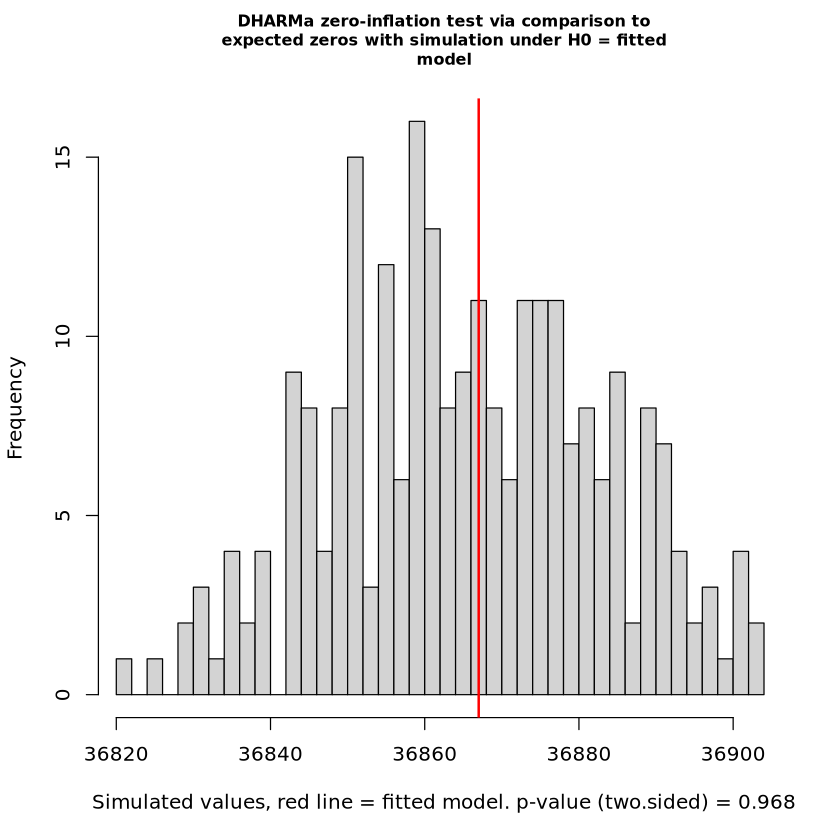

[1] "Full"


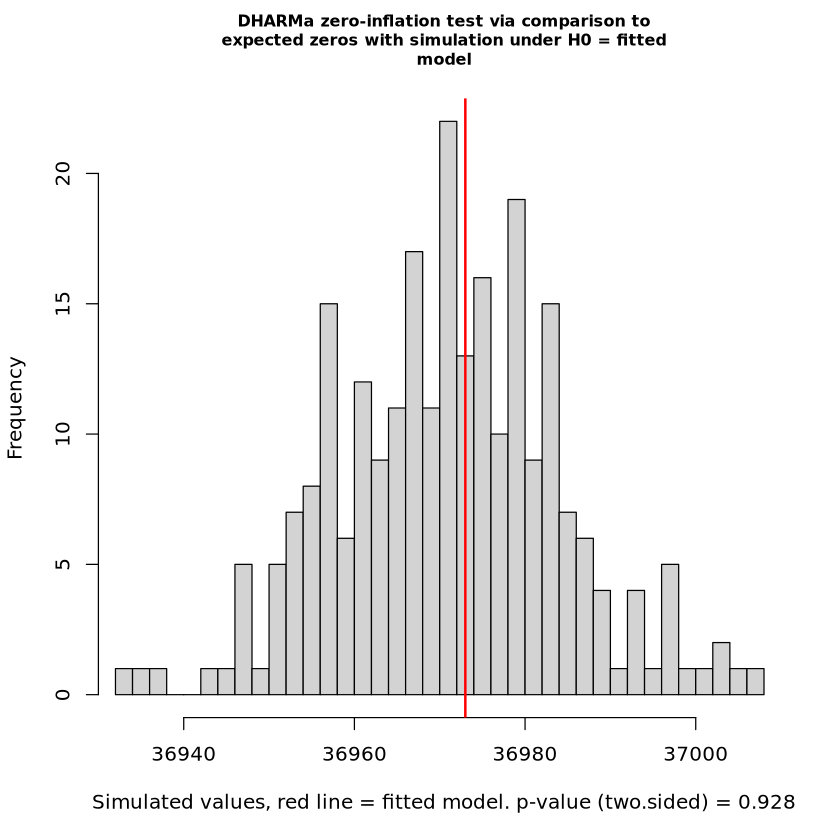

[1] "Full"


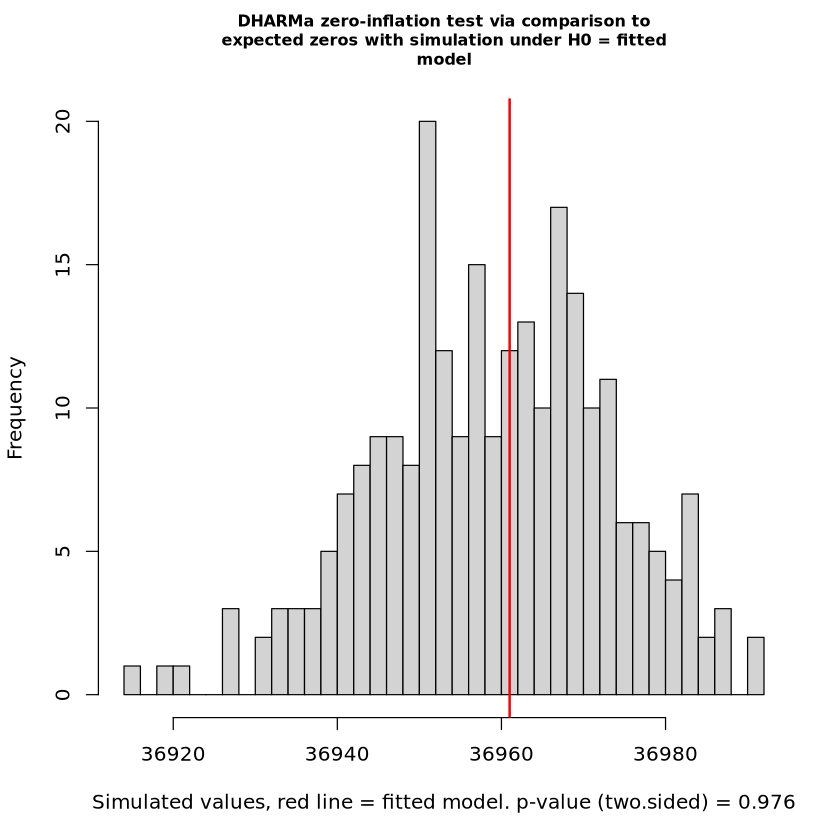

[1] "Full"


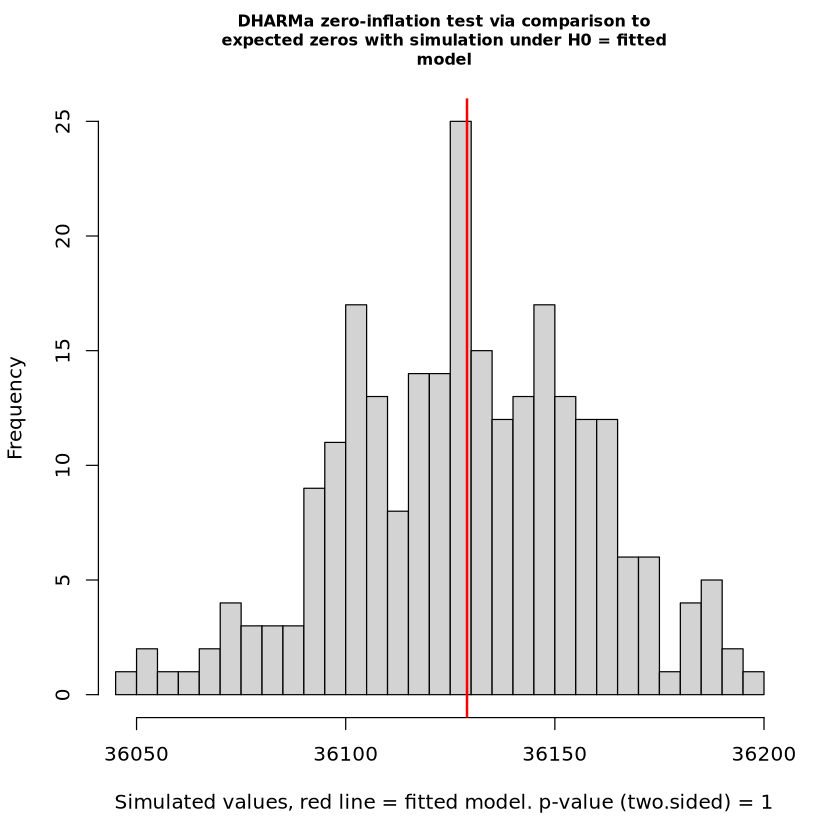

[1] "Full"


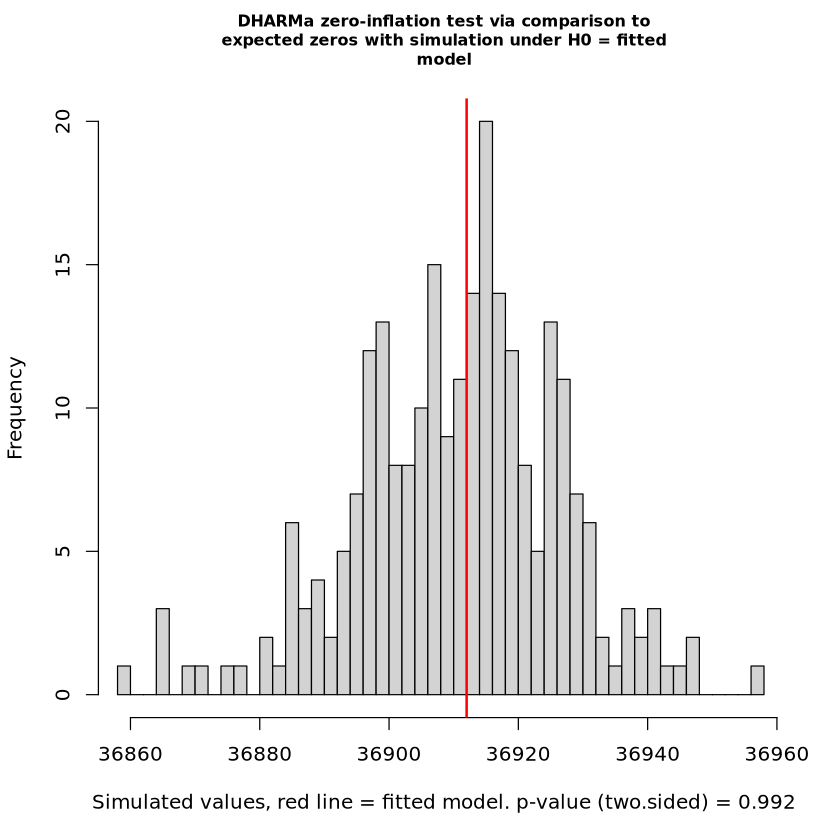

[1] "Full"


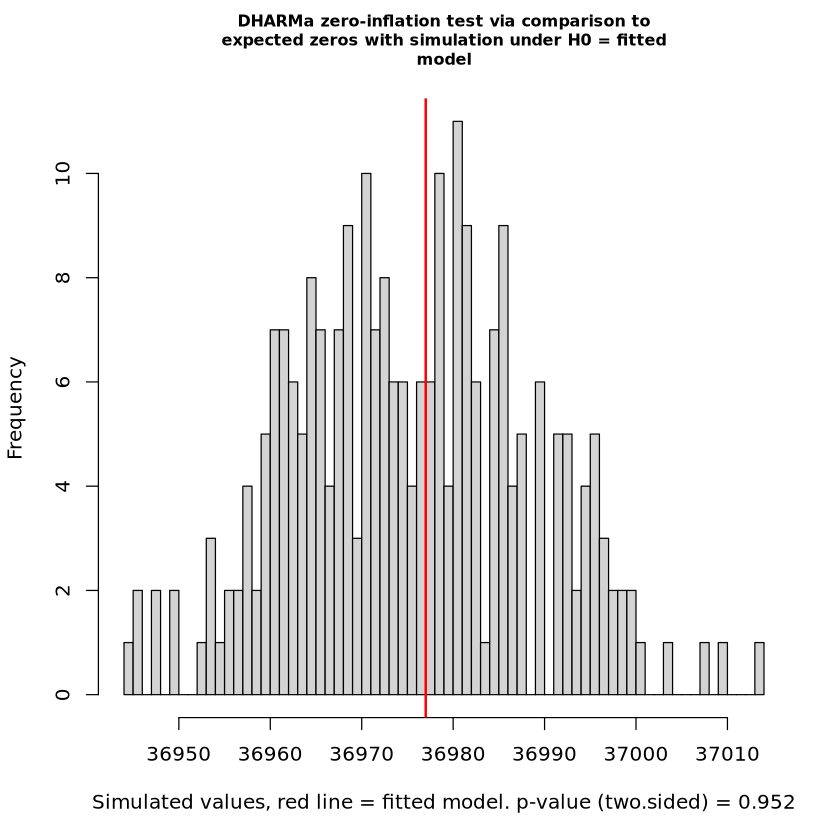

[1] "Full"


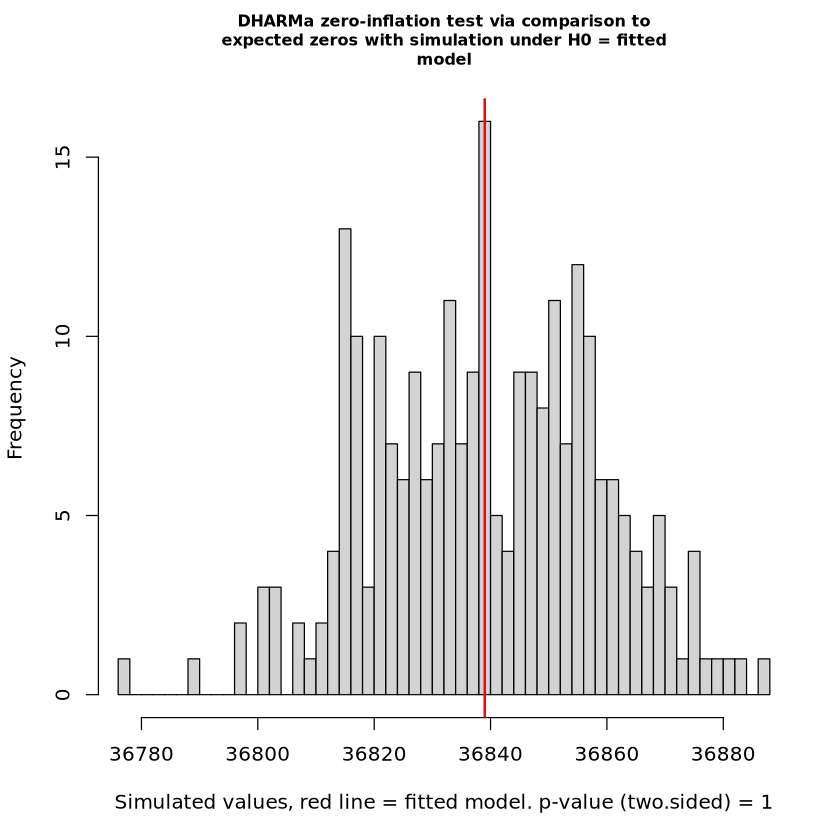

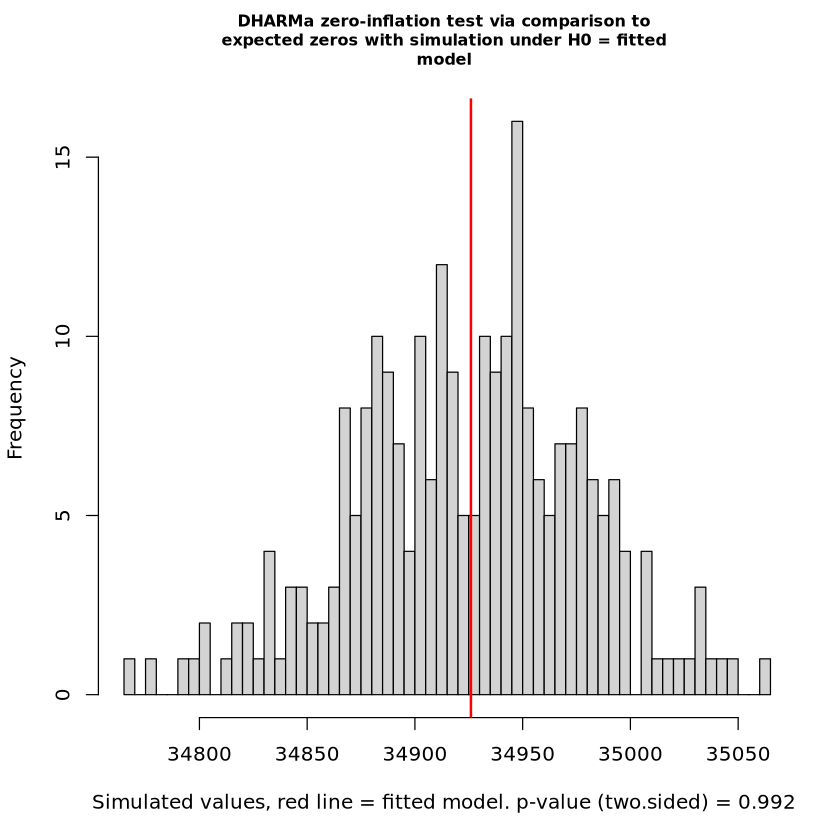

In [8]:
# Test a bunch
Test1k <- sample(rownames(exprF), 100)
head(Test1k)
pval1k <- c()

for (peak in Test1k) {
    
    test_dat = data.frame(
    GENE = as.numeric(exprF[peak,]),
    samp = metaF$sample,
    batch = as.factor(metaF$batch),
    sex = as.factor(metaF$sex),
    ogtt = as.factor(metaF$ogtt),
    bmi = as.numeric(metaF$bmi),
    age = as.numeric(metaF$age),
    tss_enrichment <- as.numeric(metaF$tss_enrichment)
  )

    # Generate new columns for the model, total_counts of this one gene (+1?)
    # and an individual id that includes the batch number... it seems. 
    test_dat %<>% mutate(total_counts = as.numeric(colSums(exprF)+1))
    test_dat %<>% mutate(individual = mapply(gsub, glue("--{batch}"), "", samp))
  
    ## initialize with NA in case of error late #AV#
    age = estimate = se = z = p_mod1 = p_val = NA
    
    print("Full")
    mod1 = glmmTMB(fmla_SS, test_dat, family = nbinom2, REML = FALSE)
    
    simulationOutput <- simulateResiduals(fittedModel = mod1, plot = F)
    temP <- testZeroInflation(simulationOutput)[5]
    pval1k <- c(pval1k, temP)
}

$p.value
[1] 1

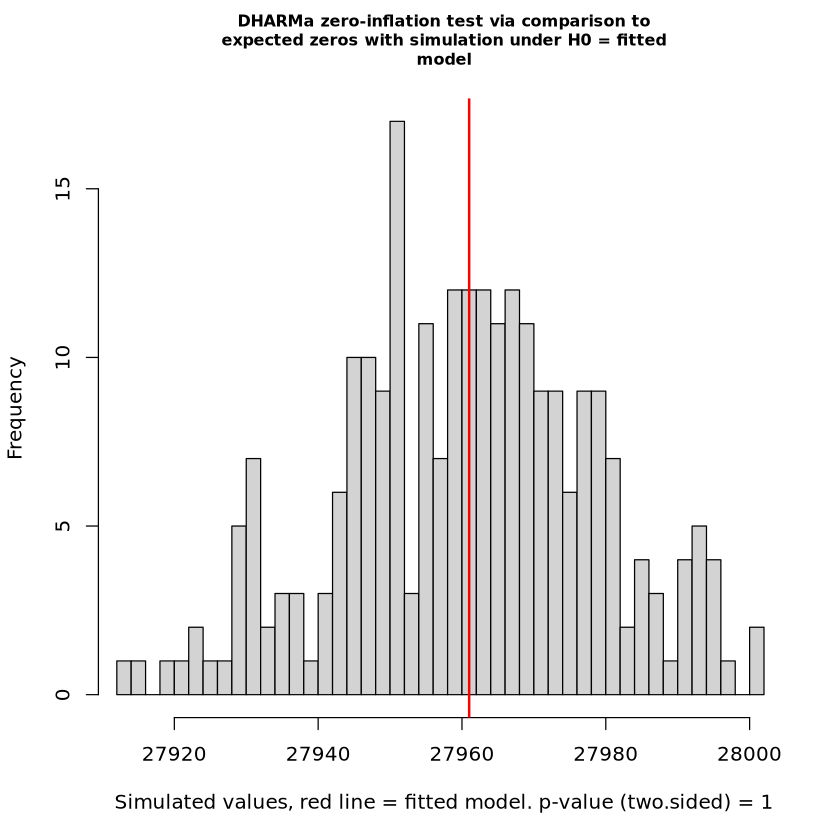

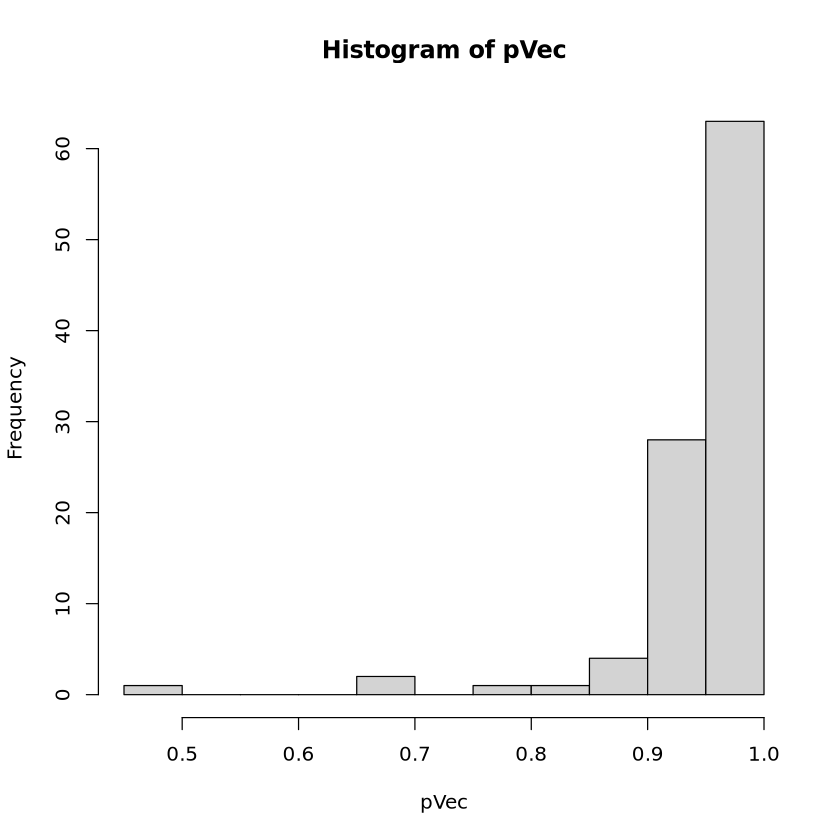

In [9]:
pVec <- (data.frame(t(data.frame(pval1k)))[,1])
hist(pVec)

In [71]:
print("Full")
mod1 = glmmTMB(fmla_SS, test_dat, family = binomial, REML = FALSE)
print("Null")
mod_null = glmmTMB(null_fmla_SS, test_dat, family = binomial, REML = FALSE)

[1] "Full"


ERROR: Error in eval(family$initialize): y values must be 0 <= y <= 1


In [12]:
print("Full")
mod1 = glmmTMB(fmla_SS, test_dat, family = poisson, REML = FALSE)
print("Null")
mod_null = glmmTMB(null_fmla_SS, test_dat, family = poisson, REML = FALSE)

[1] "Full"
[1] "Null"


In [13]:
print(summary(mod1))

 Family: poisson  ( log )
Formula:          
GENE ~ age + bmi + batch + ogtt + offset(log(total_counts)) +  
    (1 | individual)
Data: test_dat

     AIC      BIC   logLik deviance df.resid 
 20531.4  20652.7 -10249.7  20499.4    14508 

Random effects:

Conditional model:
 Groups     Name        Variance Std.Dev.
 individual (Intercept) 0.02583  0.1607  
Number of obs: 14524, groups:  individual, 120

Conditional model:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept) -10.398558   0.235230  -44.21  < 2e-16 ***
age          -0.014245   0.002882   -4.94 7.68e-07 ***
bmi           0.004688   0.005838    0.80 0.421929    
batch510     -0.159232   0.080321   -1.98 0.047429 *  
batch530     -0.018796   0.081359   -0.23 0.817299    
batch551     -0.158128   0.085784   -1.84 0.065281 .  
batch564     -0.236679   0.117936   -2.01 0.044768 *  
batch567     -0.125995   0.086072   -1.46 0.143239    
batch625     -0.147494   0.107814   -1.37 0.171300    
batch647     -0.286277  


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 1.4719, p-value < 2.2e-16
alternative hypothesis: two.sided


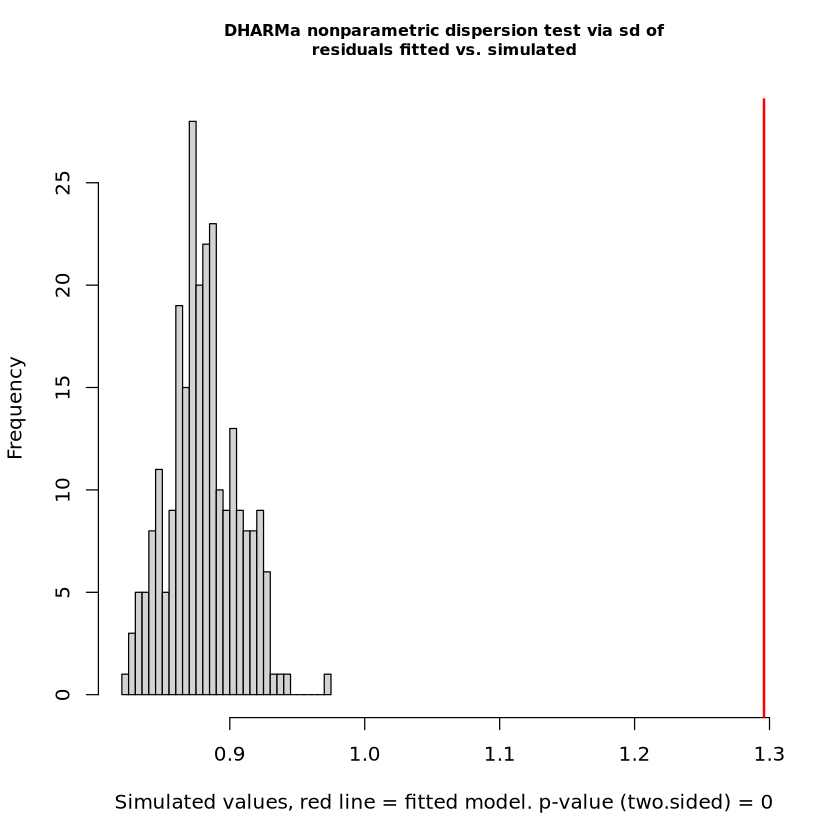


	DHARMa nonparametric dispersion test via sd of residuals fitted vs.
	simulated

data:  simulationOutput
dispersion = 1.4891, p-value < 2.2e-16
alternative hypothesis: two.sided


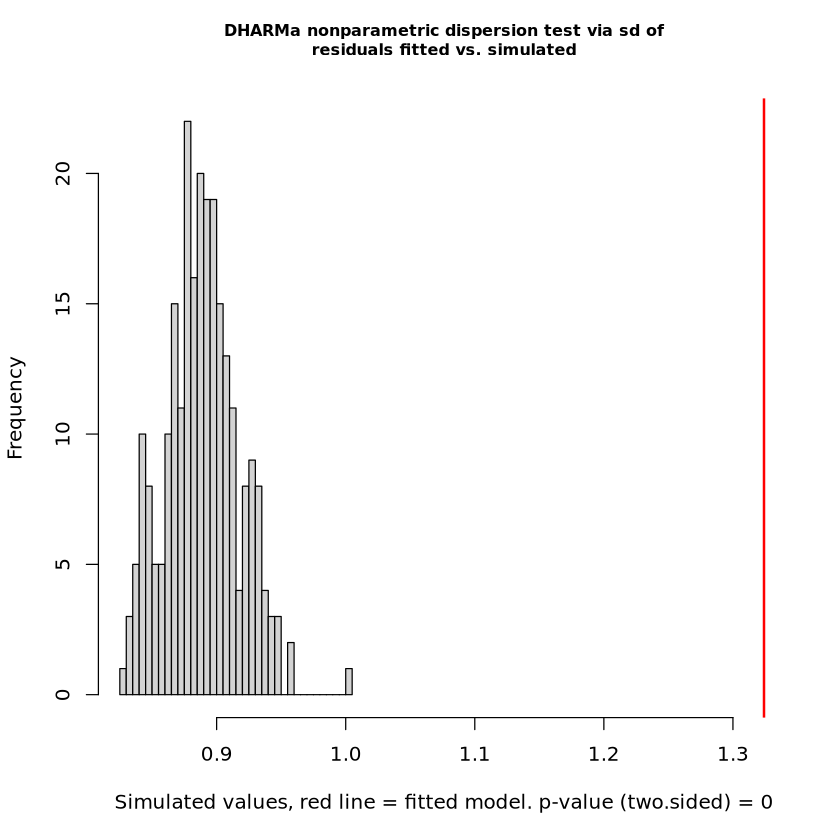

In [14]:
testDispersion(mod1)
testDispersion(mod_null)


	DHARMa bootstrapped outlier test

data:  simulationOutput
outliers at both margin(s) = 95, observations = 14524, p-value <
2.2e-16
alternative hypothesis: two.sided
 percent confidence interval:
 0.001445883 0.003029468
sample estimates:
outlier frequency (expected: 0.00223561002478656 ) 
                                       0.006540898 


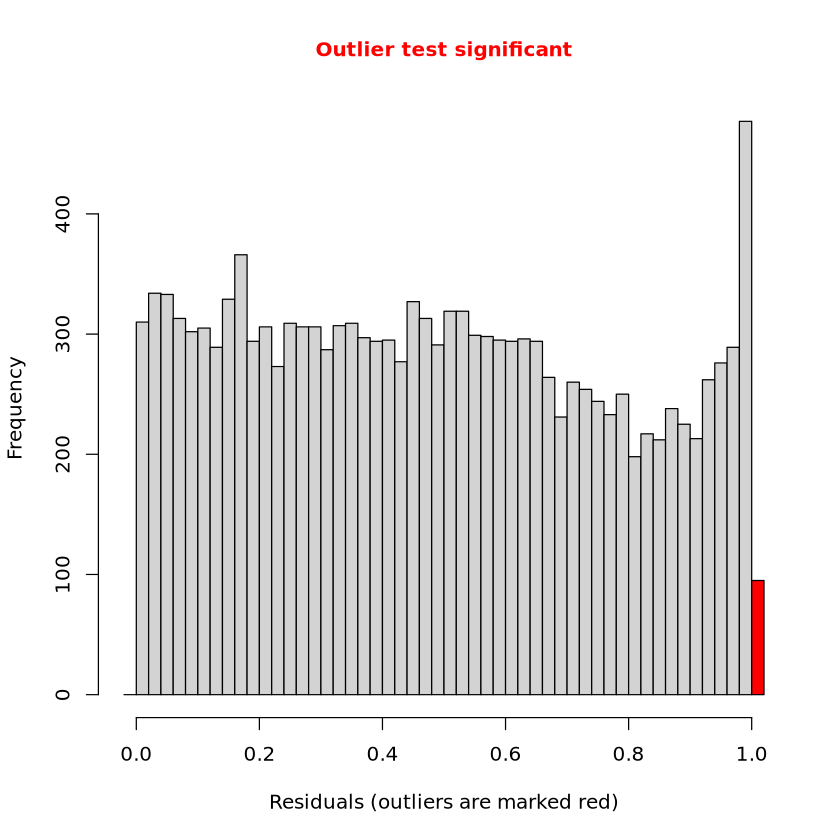

DHARMa:testOutliers with type = binomial may have inflated Type I error rates for integer-valued distributions. To get a more exact result, it is recommended to re-run testOutliers with type = 'bootstrap'. See ?testOutliers for details



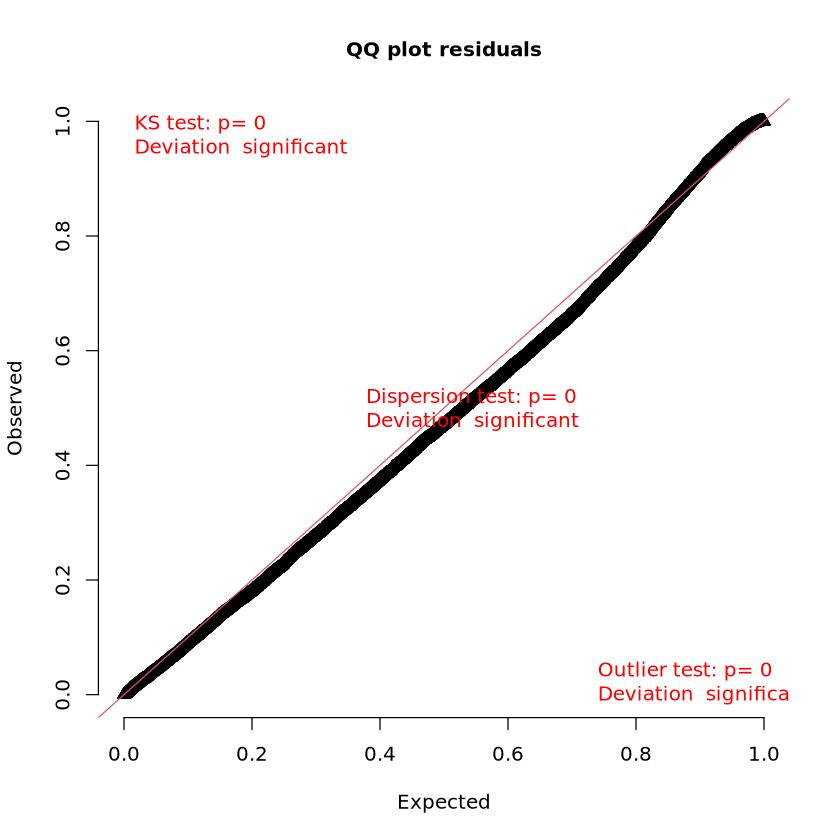

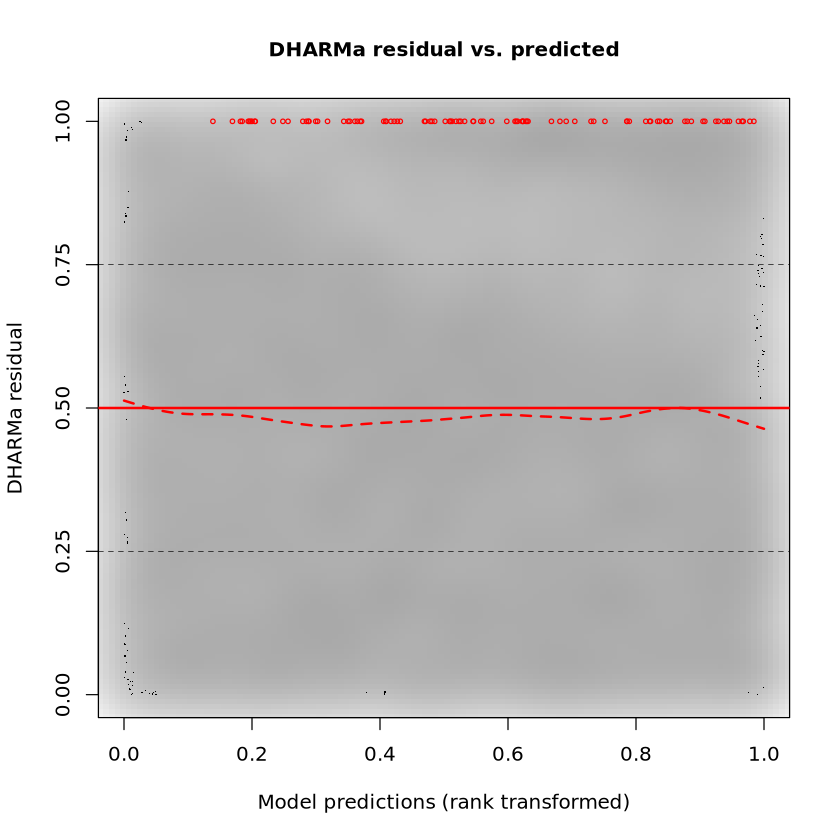


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 1.0627, p-value < 2.2e-16
alternative hypothesis: two.sided


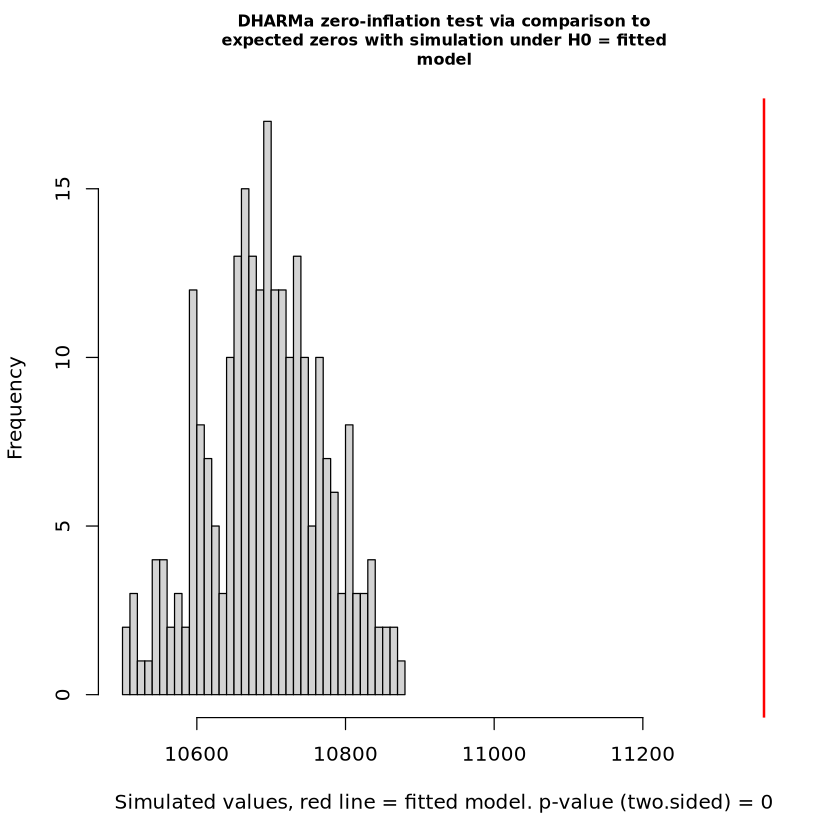

Warning message in newton(lsp = lsp, X = G$X, y = G$y, Eb = G$Eb, UrS = G$UrS, L = G$L, :
“Fitting terminated with step failure - check results carefully”



	Test for location of quantiles via qgam

data:  res
p-value = 2.105e-14
alternative hypothesis: both


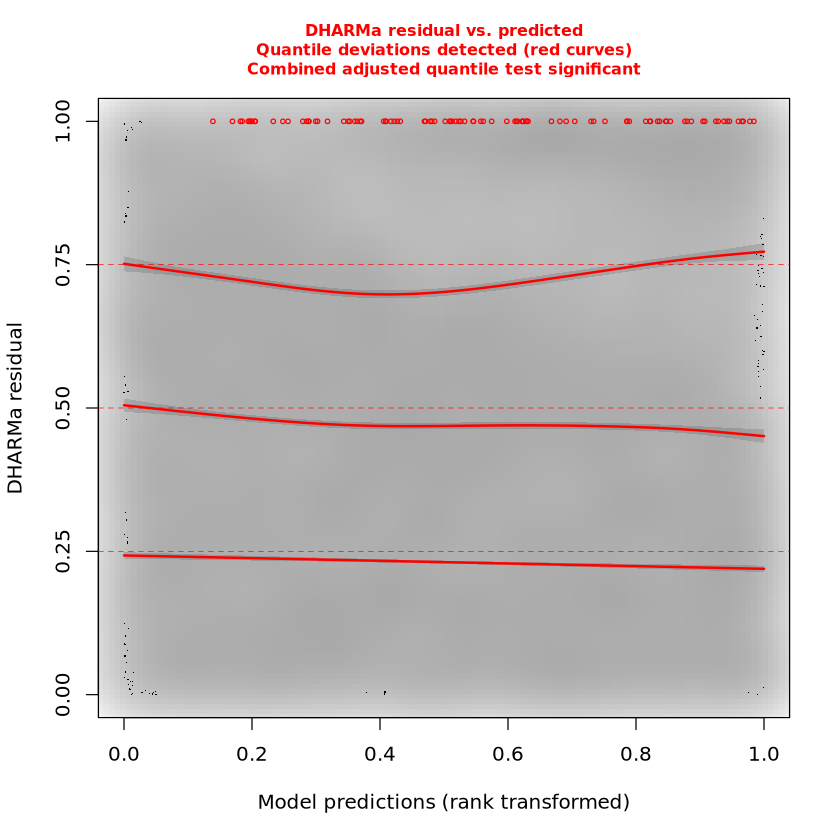


	DHARMa bootstrapped outlier test

data:  simulationOutput
outliers at both margin(s) = 95, observations = 14524, p-value <
2.2e-16
alternative hypothesis: two.sided
 percent confidence interval:
 0.001652437 0.003134467
sample estimates:
outlier frequency (expected: 0.00228793720738089 ) 
                                       0.006540898 


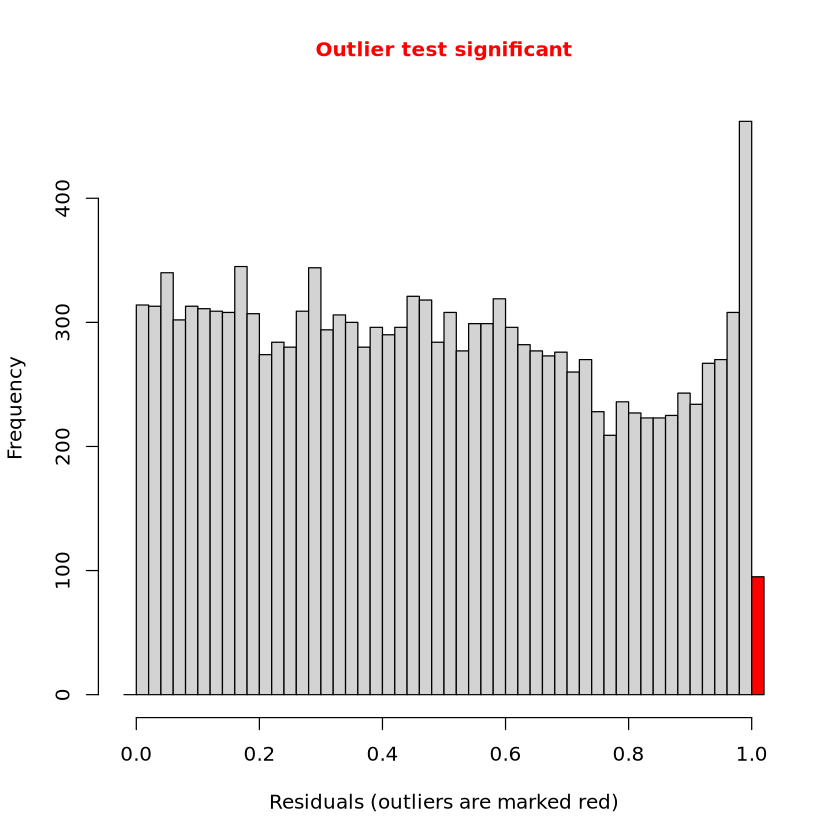

DHARMa:testOutliers with type = binomial may have inflated Type I error rates for integer-valued distributions. To get a more exact result, it is recommended to re-run testOutliers with type = 'bootstrap'. See ?testOutliers for details



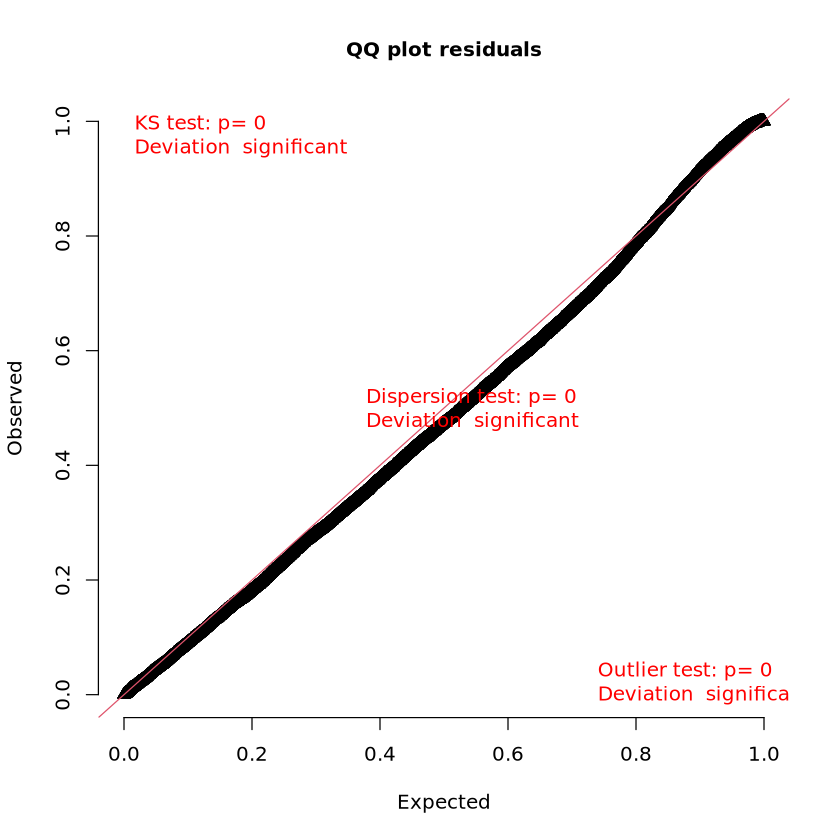

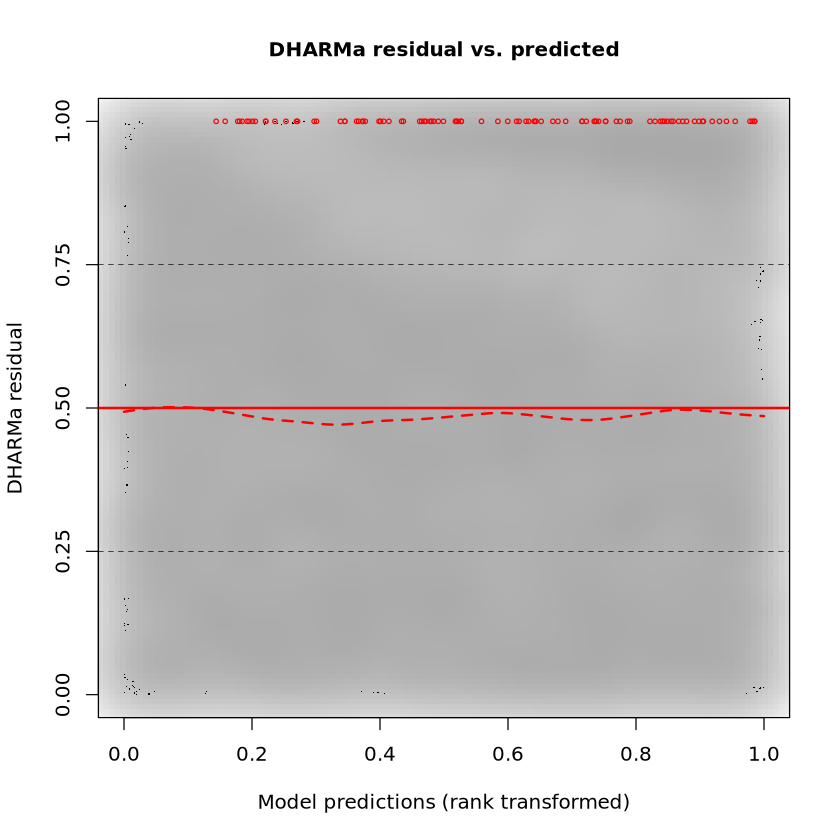


	DHARMa zero-inflation test via comparison to expected zeros with
	simulation under H0 = fitted model

data:  simulationOutput
ratioObsSim = 1.0595, p-value < 2.2e-16
alternative hypothesis: two.sided


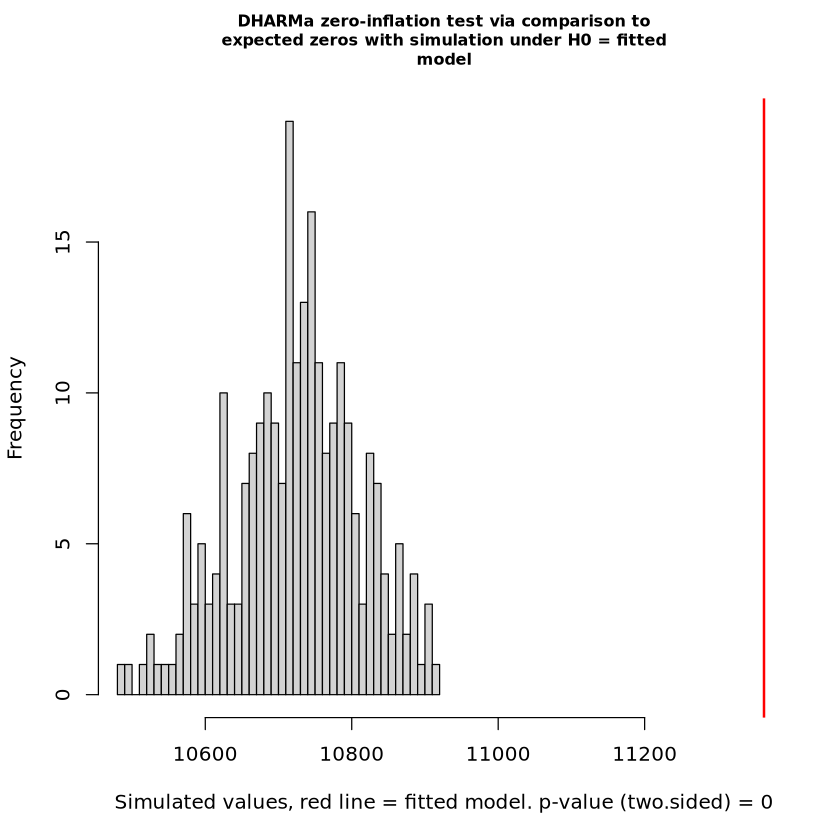

Warning message in newton(lsp = lsp, X = G$X, y = G$y, Eb = G$Eb, UrS = G$UrS, L = G$L, :
“Fitting terminated with step failure - check results carefully”



	Test for location of quantiles via qgam

data:  res
p-value < 2.2e-16
alternative hypothesis: both


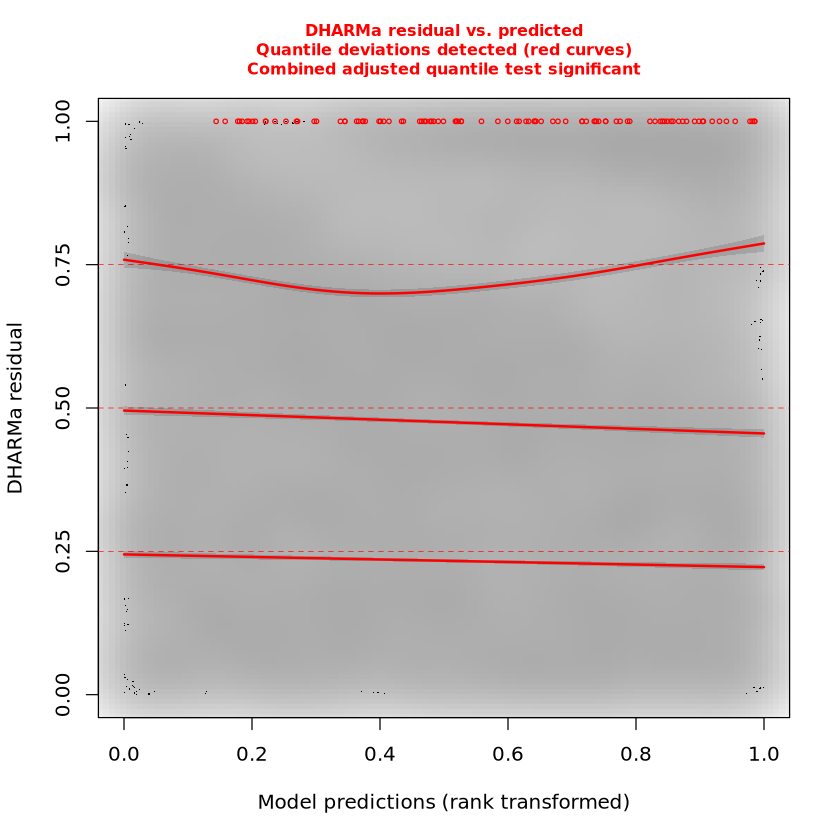

In [15]:
simulationOutput <- simulateResiduals(fittedModel = mod1, plot = F)
testOutliers(simulationOutput, type = "bootstrap")
plotQQunif(simulationOutput)
plotResiduals(simulationOutput)
testZeroInflation(simulationOutput)
testQuantiles(simulationOutput)
simulationOutput <- simulateResiduals(fittedModel = mod_null, plot = F)
testOutliers(simulationOutput, type = "bootstrap")
plotQQunif(simulationOutput)
plotResiduals(simulationOutput)
testZeroInflation(simulationOutput)
testQuantiles(simulationOutput)